# Imports

In [1]:
from biopandas.pdb import PandasPdb
import scipy as sp
import pandas as pd
import os
import numpy as np
# import Bio
# from abnumber import Chain
import math
import enum
import torch
import torch.nn.functional as F
from tqdm import trange
import warnings
import seaborn as sns
from pathlib import Path
from typing import Dict, Tuple, Sequence, List, Optional, Union
# from Bio import SeqIO
# from Bio.Seq import Seq
# from Bio.SeqRecord import SeqRecord
# from Bio import AlignIO
# from Levenshtein import ratio
# from Benchmarking.benchmark.ops.all_funcs import * 
# from Benchmarking.benchmark.ops.protein import *
# from Benchmarking.benchmark.ops.benchmark_clean_funcs import *
# import colorcet as cc
# from scipy.stats import mannwhitneyu, ranksums
from scipy import stats
# import statsmodels #.api as sm
import shutil

In [2]:
import matplotlib.pyplot as plt

In [ ]:
pose = pose_from_pdb('4fp8')
pose_i1 = pyrosetta.rosetta.protocols.antibody.AntibodyInfo(pose)
print(pose_i1)

# Data setup

# Loading in dataframes

In [ ]:
# Revised benchmark curated af3 benchmark import
# final_af3_benchmark = pd.read_csv("results/round_7/datafiles/complete_af3_benchmark.csv").drop(columns=['Unnamed: 0'])
nb_trainnonredund=pd.read_csv("/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchmark/New_AF3_Benchmark/results/round_8/datafiles/train_red_dropped_nb_finalbench.csv").reset_index(drop=True).drop(columns=['index'])
ab_trainnonredund=pd.read_csv("/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchmark/New_AF3_Benchmark/results/round_8/datafiles/train_red_dropped_ab_finalbench.csv").reset_index(drop=True).drop(columns=['index'])
vhsim_addedbench  = pd.read_csv("results/round_7/datafiles/complete_af3_benchmark.csv").drop(columns=['Unnamed: 0']).iloc[-60:,:]
final_af3_benchmark = pd.concat([nb_trainnonredund, ab_trainnonredund,vhsim_addedbench], axis=0).reset_index(drop=True)
final_af3_benchmark.loc[-60:,['PDB_short']] = ['_'.join(x.split('_')[-2:]) for x in final_af3_benchmark.Native_PDB.tolist()]
final_af3_benchmark.loc[-60:,['PDB_short']] = final_af3_benchmark['PDB_short'].astype(str)
final_af3_benchmark['Seed'] = [int([y for y in x.split('seed')[-1].split('_') if y!=''][0]) for x in final_af3_benchmark.AF3_PDB.tolist()]
final_af3_benchmark['Model'] = [int([y.split('.')[0] for y in x.split('model')[-1].split('_') if y!=''][0]) for x in final_af3_benchmark.AF3_PDB.tolist()]
ranking_df = pd.read_csv("results/round_6/datafiles/af3_withproperranking_results.csv").drop(columns=['Unnamed: 0'])
ranking_df = ranking_df.rename(columns={"Dir":"AF3_Dir","PDB":"AF3_PDB"})
fulldf_fixed = pd.read_csv("results/round_6/datafiles/af3_withauxdata_andproperranking_results_fixeddf.csv").drop(columns=['Unnamed: 0'])

# AF3 v AF2 results with aux data

AF2_v_AF3 = pd.read_csv("results/round_6/datafiles/af3_v_af2_results.csv").drop(columns=['Unnamed: 0'])
AF2_v_AF3['H3_local_RMSD'] = [x if x!='length mismatch' else np.nan for x in AF2_v_AF3['H3_local_RMSD'].tolist()]
melted_AF2_v_AF3 = pd.melt(AF2_v_AF3,id_vars = ['Model_Source','Protein_type', 'Bound_Unbound',
       'Seed', 'Model', 'PDB_short', 'h3_len','h3_length'],value_vars=['ocd', 'frh_rms', 'h1_rms', 'h2_rms', 'h3_rms','H3_local_RMSD','frl_rms',
       'l1_rms', 'l2_rms', 'l3_rms'],var_name = "Fv_Region",value_name = "RMSD (Å)")
melted_AF2_v_AF3

# IgFold benchmark
igfold_benchmark = pd.read_csv("results/round_6/datafiles/topranked_inventoried_finalIgFoldFullresults.csv",index_col='Unnamed: 0')

In [4]:
# antibodies
ab_sabdab_path = "../sabdab_summary_all_240531.tsv"
ab_sabdab = pd.read_csv(ab_sabdab_path,delimiter='\t')

# nanobodies
nb_sabdab_path = "../20240604_0067950_summary_nanobodies.tsv"
nb_sabdab = pd.read_csv(nb_sabdab_path,delimiter='\t')

In [5]:
#Final benchmark has been filtered to only include the PDBs that had antigens of type protein, peptide, or protein | protein
def final_culled(final_af3_benchmark,pdbslist):
    pdbs = []
    for x in pdbslist:
        pdbs.append(final_af3_benchmark[final_af3_benchmark['PDB_short'].str.contains(x)])
    return pd.concat(pdbs,ignore_index=True)
final_ab_benchmark = final_culled(final_af3_benchmark,ab_sabdab[(ab_sabdab['pdb'].isin([x.split('_')[0] for x in final_af3_benchmark.PDB_short.unique().tolist()]))\
    &(ab_sabdab['antigen_type'].isin(['protein','peptide','protein | protein']))].pdb.unique().tolist())
final_nb_benchmark = final_culled(final_af3_benchmark,nb_sabdab[(nb_sabdab['pdb'].isin([x.split('_')[0] for x in final_af3_benchmark.PDB_short.unique().tolist()]))\
    &(nb_sabdab['antigen_type'].isin(['protein','peptide','protein | protein']))].pdb.unique().tolist())
final_benchmark = pd.concat([final_ab_benchmark,final_nb_benchmark],ignore_index=True)
final_af3_benchmark = pd.concat([final_af3_benchmark[final_af3_benchmark['Bound_Unbound']=='unbound'],final_benchmark],ignore_index=True)
bad_pdbs = ['7zxu_1.pdb','8cby_0.pdb','7yiz_1.pdb']
final_af3_benchmark = final_af3_benchmark[~final_af3_benchmark['PDB_short'].isin(bad_pdbs)]
abs_list = final_af3_benchmark[final_af3_benchmark['Protein_type']=='antibody'].PDB_short.unique().tolist()
nbs_list = final_af3_benchmark[final_af3_benchmark['Protein_type']=='nanobody'].PDB_short.unique().tolist()

In [8]:
final_withranked = final_af3_benchmark.drop(list(final_af3_benchmark.dropna(subset=['Rank']).index.values)).drop(columns=['Rank']).merge(ranking_df,on=["AF3_Dir","AF3_PDB",'Bound_Unbound','Protein_type'])
final_withranked=pd.concat([final_withranked,final_af3_benchmark.dropna(subset=['Rank'])]).drop_duplicates() #[final_withranked['AF3_PDB'].str.contains('8gkk_0_seed2')].PDB_short
final_withranked

,AF3_Dir,AF3_PDB,Bound_Unbound,Native_Dir,Native_PDB,H3_local_RMSD,ocd,frh_rms,h1_rms,h2_rms,...,ipTM_LA,I_pLDDT,DockQ_Classification,h3_len,h3_length,L3_plddt_arrays,Avg_L3_pLDDT,F1,Fnat,Rank
0,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fold_8e2n_1_seed1_model_4.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8e2n_1.pdb,0.813025,0.0,0.474868,0.846050,2.261091,...,NaN,NaN,NaN,17.0,long,NaN,NaN,NaN,NaN,0.87
1,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fold_8e2n_1_seed1_model_3.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8e2n_1.pdb,0.801910,0.0,0.475264,0.901126,2.466063,...,NaN,NaN,NaN,17.0,long,NaN,NaN,NaN,NaN,0.87
2,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fold_8e2n_1_seed1_model_0.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8e2n_1.pdb,0.842664,0.0,0.450681,0.854061,2.229291,...,NaN,NaN,NaN,17.0,long,NaN,NaN,NaN,NaN,0.88
3,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fold_8e2n_1_seed1_model_2.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8e2n_1.pdb,0.817250,0.0,0.507618,0.847317,2.279391,...,NaN,NaN,NaN,17.0,long,NaN,NaN,NaN,NaN,0.88
4,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fold_8e2n_1_seed1_model_1.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8e2n_1.pdb,0.870796,0.0,0.490179,0.880228,2.310187,...,NaN,NaN,NaN,17.0,long,NaN,NaN,NaN,NaN,0.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1675,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_stitched_renamed_fold_8cy7_2_seed1_model...,bound,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,8cy7_2.pdb,0.654266,0.0,1.292215,4.526315,2.592564,...,NaN,68.964634,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.26
1676,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_stitched_renamed_fold_8cy7_2_seed1_model...,bound,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,8cy7_2.pdb,0.417248,0.0,1.366356,4.098543,2.514115,...,NaN,80.078235,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.26
1677,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_stitched_renamed_fold_8cy7_2_seed1_model...,bound,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,8cy7_2.pdb,0.289253,0.0,1.300287,3.848574,2.665106,...,NaN,60.572500,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.25
1678,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_stitched_renamed_fold_8cy7_2_seed1_model...,bound,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,8cy7_2.pdb,0.318991,0.0,1.270244,3.920507,2.704645,...,NaN,73.244607,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.25


In [ ]:
# final_withranked = final_af3_benchmark.merge(ranking_df,on=["AF3_Dir","AF3_PDB",'Bound_Unbound','Protein_type'])
# final_withranked = fulldf_fixed
ab_bound_unique_pdbs = final_withranked[(final_withranked['Bound_Unbound']=='bound')&(final_withranked['Protein_type']=='antibody')].PDB_short.unique().tolist()
ab_unbound_unique_pdbs = final_withranked[(final_withranked['Bound_Unbound']=='unbound')&(final_withranked['Protein_type']=='antibody')].PDB_short.unique().tolist()
nb_bound_unique_pdbs = final_withranked[(final_withranked['Bound_Unbound']=='bound')&(final_withranked['Protein_type']=='nanobody')].PDB_short.unique().tolist()
nb_unbound_unique_pdbs = final_withranked[(final_withranked['Bound_Unbound']=='unbound')&(final_withranked['Protein_type']=='nanobody')].PDB_short.unique().tolist()
bubs = ['bound','unbound','bound','unbound']
prots = ['antibody','antibody','nanobody','nanobody']
pdb_list = [ab_bound_unique_pdbs,ab_unbound_unique_pdbs,nb_bound_unique_pdbs,nb_unbound_unique_pdbs]
alltoppreds = []
toppreds_perseed = []
for a in range(1,4):
    # print(a)
    for i in range(4):
    # for i in range(1):
        pdbs = pdb_list[i]
        bub = bubs[i]
        prot = prots[i]
        toppreds = []
        for j in trange(len(pdbs)):
        # for j in trange(1):
            try:
                pdb_df = final_withranked[(final_withranked['Bound_Unbound']==bub)&(final_withranked['Seed']==a)&(final_withranked['Protein_type']==prot)&(final_withranked['PDB_short']==pdbs[j])].reset_index()
                print(pdbs[j])
                # print(pdb_df.shape)
                # print(pdb_df)
                # print(pdb_df['Rank'].idxmax())
                top_pred = pd.DataFrame(pdb_df.iloc[pdb_df['Rank'].idxmax()]) #.T
                # print(top_pred.shape)
                if top_pred.shape!=(36,1):
                    # print(top_pred['ipTM_HA'])
                    top_pred = top_pred.iloc[top_pred['ipTM_HA'].idxmax()]
                    if top_pred.shape!=(32,1):
                        top_pred= top_pred.iloc[0]
                        toppreds.append(top_pred.T)
                    else:
                        toppreds.append(top_pred.T)
                else:
                    # print(top_pred.T)
                    toppreds.append(top_pred.T)
            except Exception as e:
                print(e)
        alltoppreds.append(pd.concat(toppreds).reset_index().drop(columns=['index']))
    top_df = pd.concat(alltoppreds).drop(columns=['level_0'])
    toppreds_perseed.append(top_df)
top_df_perseed = pd.concat(toppreds_perseed)
top_df_perseed =top_df_perseed.drop_duplicates().reset_index(drop=True)
top_df_perseed

1


 12%|█▏        | 6/49 [00:00<00:00, 59.14it/s]

8qrg_0.pdb
4
(36, 1)
8tbq_1.pdb
0
(36, 1)
8r1d_0.pdb
1
(36, 1)
8sdg_1.pdb
1
(36, 1)
8cii_1.pdb
1
(36, 1)
8cin_0.pdb
0
(36, 1)
8j7t_0.pdb
3
(36, 1)
8e6j_0.pdb
4
(36, 1)
7yds_0.pdb
0
(36, 1)


 24%|██▍       | 12/49 [00:00<00:00, 58.61it/s]

8d9y_0.pdb
1
(36, 1)
8d9z_0.pdb
1
(36, 1)
8da0_1.pdb
3
(36, 1)
8da0_0.pdb
0
(36, 1)


...

  0%|          | 0/10 [00:00<?, ?it/s]

8e2n_1.pdb
0
(36, 1)
8coh_0.pdb
0
(36, 1)
7t84_1.pdb
1
(36, 1)
8gz6_1.pdb
0
(36, 1)
7xl0_0.pdb
0
(36, 1)
7t84_3.pdb
0
(36, 1)
7t84_2.pdb
0
(36, 1)
7q6c_0.pdb
0
(36, 1)
7t83_1.pdb
0
(36, 1)


100%|██████████| 10/10 [00:00<00:00, 61.68it/s]

7r20_0.pdb
attempt to get argmax of an empty sequence


,AF3_Dir,AF3_PDB,Bound_Unbound,Native_Dir,Native_PDB,H3_local_RMSD,ocd,frh_rms,h1_rms,h2_rms,...,ipTM_LA,I_pLDDT,DockQ_Classification,h3_len,h3_length,L3_plddt_arrays,Avg_L3_pLDDT,F1,Fnat,Rank
0,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8qrg_0_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8qrg_0.pdb,2.012609,1.412208,0.332826,0.632234,0.412164,...,0.87,81.565395,Incorrect,12.0,medium,NaN,NaN,NaN,NaN,0.61
1,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8tbq_1_seed1_model_2.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8tbq_1.pdb,1.685917,2.89052,0.289481,0.325972,0.420205,...,0.79,84.445286,Medium,15.0,medium,NaN,NaN,NaN,NaN,0.86
2,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8r1d_0_seed1_model_1.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8r1d_0.pdb,2.176737,4.517764,0.358965,0.58391,0.465347,...,0.72,69.58419,Incorrect,14.0,medium,NaN,NaN,NaN,NaN,0.32
3,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8sdg_1_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8sdg_1.pdb,3.032309,2.751782,0.435095,0.54936,0.949082,...,0.87,84.263649,Incorrect,15.0,medium,NaN,NaN,NaN,NaN,0.65
4,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8cii_1_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8cii_1.pdb,1.07422,4.399033,0.400842,1.179872,0.632352,...,0.88,77.940143,Incorrect,19.0,long,NaN,NaN,NaN,NaN,0.58
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fold_7xl0_0_seed3_model_2.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_7xl0_0.pdb,3.806065,0.0,0.716844,1.439683,1.614849,...,NaN,NaN,NaN,15.0,medium,NaN,NaN,NaN,NaN,0.86
376,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fold_7t84_3_seed3_model_0.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_7t84_3.pdb,1.519906,0.0,0.65562,2.708012,2.459866,...,NaN,NaN,NaN,12.0,medium,NaN,NaN,NaN,NaN,0.86
377,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fold_7t84_2_seed3_model_4.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_7t84_2.pdb,1.175316,0.0,0.554841,2.334403,2.570052,...,NaN,NaN,NaN,12.0,medium,NaN,NaN,NaN,NaN,0.88
378,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fold_7q6c_0_seed3_model_3.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_7q6c_0.pdb,1.475521,0.0,0.412668,0.647626,0.810992,...,NaN,NaN,NaN,11.0,medium,NaN,NaN,NaN,NaN,0.88


In [12]:
final_withranked[(final_withranked['Bound_Unbound']=='bound')&(final_withranked['Protein_type']=='antibody')]

,AF3_Dir,AF3_PDB,Bound_Unbound,Native_Dir,Native_PDB,H3_local_RMSD,ocd,frh_rms,h1_rms,h2_rms,...,ipTM_LA,I_pLDDT,DockQ_Classification,h3_len,h3_length,L3_plddt_arrays,Avg_L3_pLDDT,F1,Fnat,Rank
330,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8qrg_0_seed2_model_1.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8qrg_0.pdb,1.956648,1.867501,0.314176,0.655175,0.355895,...,0.88,81.299733,Incorrect,12.0,medium,NaN,NaN,NaN,NaN,0.58
331,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8qrg_0_seed2_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8qrg_0.pdb,2.158613,0.940148,0.321670,0.601064,0.408045,...,0.88,81.837377,Medium,12.0,medium,NaN,NaN,NaN,NaN,0.58
332,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8qrg_0_seed2_model_3.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8qrg_0.pdb,2.016567,1.958765,0.320293,0.648882,0.348301,...,0.88,83.593529,Incorrect,12.0,medium,NaN,NaN,NaN,NaN,0.57
333,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8qrg_0_seed2_model_2.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8qrg_0.pdb,2.328009,2.885775,0.292686,0.646273,0.348642,...,0.88,80.823056,Incorrect,12.0,medium,NaN,NaN,NaN,NaN,0.58
334,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8qrg_0_seed2_model_4.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8qrg_0.pdb,2.008822,2.203642,0.304527,0.647429,0.379808,...,0.88,80.724545,Incorrect,12.0,medium,NaN,NaN,NaN,NaN,0.57
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1890,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fv_fold_7so5_0_seed2_model_3.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7so5_0.pdb,2.819486,0.825789,0.260595,0.860758,0.322451,...,0.91,77.786667,Incorrect,15.0,medium,NaN,NaN,NaN,NaN,0.39
1891,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fv_fold_7so5_0_seed2_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7so5_0.pdb,2.787734,1.050990,0.272739,0.839577,0.375823,...,0.91,83.741196,Incorrect,15.0,medium,NaN,NaN,NaN,NaN,0.40
1892,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fv_fold_7so5_0_seed2_model_4.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7so5_0.pdb,1.337025,1.603973,0.319099,0.990098,0.268618,...,0.91,84.612021,Incorrect,15.0,medium,NaN,NaN,NaN,NaN,0.39
1893,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fv_fold_7so5_0_seed2_model_2.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7so5_0.pdb,2.932350,1.086382,0.289172,0.875932,0.351857,...,0.91,82.804561,Incorrect,15.0,medium,NaN,NaN,NaN,NaN,0.39


In [13]:
def cp_to_new(df):
    af3_dir = '/home/ftalib1/scr16_jgray21/ftalib1/AF3_Benchmark/revised_Compiled_Benchmark_Data/AF3/'
    xtal_dir = '/home/ftalib1/scr16_jgray21/ftalib1/AF3_Benchmark/revised_Compiled_Benchmark_Data/Xtal/'
    for i in trange(df.shape[0]):
        pdb = df.iloc[i]
        pred_pdb = os.path.join(pdb.AF3_Dir,pdb.AF3_PDB)
        native_pdb = os.path.join(pdb.Native_Dir,pdb.Native_PDB)
        if os.path.exists(os.path.join(af3_dir,pdb.Protein_type,pdb.Bound_Unbound,pdb.AF3_PDB)):
            pass
        else:
            shutil.copy(pred_pdb,os.path.join(af3_dir,pdb.Protein_type,pdb.Bound_Unbound,pdb.AF3_PDB))
        if os.path.exists(os.path.join(xtal_dir,pdb.Protein_type,pdb.Bound_Unbound,pdb.Native_PDB)):
            pass
        else:
            shutil.copy(native_pdb,os.path.join(xtal_dir,pdb.Protein_type,pdb.Bound_Unbound,pdb.Native_PDB))
    print('done')
    return 

cp_to_new(final_withranked[(final_withranked['Bound_Unbound']=='bound')&(final_withranked['Protein_type']=='antibody')])

100%|██████████| 735/735 [00:34<00:00, 21.02it/s]

done


In [8]:
top_df_perseed[(top_df_perseed['Bound_Unbound']=='bound')&(top_df_perseed['Protein_type']=='nanobody')].PDB_short.unique().shape

(60,)

In [ ]:
top_df_perseed[(top_df_perseed['Bound_Unbound']=='bound')&(top_df_perseed['Protein_type']=='antibody')].Native_PDB.unique().shape

(49,)

In [ ]:
top_df_perseed[(top_df_perseed['Bound_Unbound']=='unbound')&(top_df_perseed['Protein_type']=='nanobody')].Native_PDB.unique().shape

(10,)

In [ ]:
top_df_perseed[(top_df_perseed['Bound_Unbound']=='unbound')&(top_df_perseed['Protein_type']=='antibody')].Native_PDB.unique().shape

(13,)

In [10]:
def get_top(pdbinfo):
    best_byrank = pdbinfo[pdbinfo['Rank']==pdbinfo['Rank'].max()]
    if best_byrank.shape[0]>1:
        best_byrank = best_byrank[best_byrank['ipTM_HA']==best_byrank['ipTM_HA'].max()]
    if best_byrank.shape[0]>1:
        best_byrank = best_byrank[best_byrank['I_pLDDT']==best_byrank['I_pLDDT'].max()]
    return pd.DataFrame(best_byrank)


In [11]:
def get_topranked(df,pdblist):
    pdbs = []
    for x in trange(len(pdblist)):
        pdbinfo = df[df['PDB_short']==pdblist[x]]
        bubprot_dict= dict(zip(pdbinfo.Bound_Unbound.unique().tolist(),[pdbinfo[pdbinfo['Bound_Unbound']==i].Protein_type.unique().tolist() for i in pdbinfo.Bound_Unbound.unique().tolist()]))
        # print(bubprot_dict)
        unique_bubs = list(bubprot_dict.keys())
        for j in unique_bubs:
            for k in bubprot_dict[j]:
                pdbinfo = df[(df['PDB_short']==pdblist[x])&(df['Bound_Unbound']==j)&(df['Protein_type']==k)]
                if pdbinfo.shape[0]==0:
                    print(f'for bub: {j}')
                    print(f'for prot: {k}')
                    print(f'error getting dataframe for pdb {pdblist[x]}')
                pdbs.append(get_top(pdbinfo))
    return pd.concat(pdbs,ignore_index=True)
top_df = get_topranked(top_df_perseed,top_df_perseed.drop_duplicates(subset=['PDB_short','Bound_Unbound','Protein_type']).PDB_short.tolist()).drop_duplicates()
top_df

 16%|█▌        | 21/132 [00:00<00:00, 209.14it/s]

100%|██████████| 132/132 [00:01<00:00, 82.31it/s]


,AF3_Dir,AF3_PDB,Bound_Unbound,Native_Dir,Native_PDB,H3_local_RMSD,ocd,frh_rms,h1_rms,h2_rms,...,ipTM_LA,I_pLDDT,DockQ_Classification,h3_len,h3_length,L3_plddt_arrays,Avg_L3_pLDDT,F1,Fnat,Rank
0,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8qrg_0_seed3_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8qrg_0.pdb,2.032374,1.351977,0.309075,0.557942,0.505188,...,0.87,82.146235,Incorrect,12.0,medium,NaN,NaN,NaN,NaN,0.63
1,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8tbq_1_seed2_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8tbq_1.pdb,1.390445,1.926631,0.2702,0.301443,0.388581,...,0.79,84.908209,Medium,15.0,medium,NaN,NaN,NaN,NaN,0.86
2,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8r1d_0_seed3_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8r1d_0.pdb,2.540755,3.592467,0.341119,0.534769,0.421884,...,0.76,67.890449,Incorrect,14.0,medium,NaN,NaN,NaN,NaN,0.38
3,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8sdg_1_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8sdg_1.pdb,3.032309,2.751782,0.435095,0.54936,0.949082,...,0.87,84.263649,Incorrect,15.0,medium,NaN,NaN,NaN,NaN,0.65
4,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8cii_1_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8cii_1.pdb,1.07422,4.399033,0.400842,1.179872,0.632352,...,0.88,77.940143,Incorrect,19.0,long,NaN,NaN,NaN,NaN,0.58
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_stitched_renamed_fold_8cy7_2_seed1_model...,bound,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,8cy7_2.pdb,0.654266,0.0,1.292215,4.526315,2.592564,...,NaN,68.964634,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.26
117,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fold_8coh_0_seed1_model_0.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8coh_0.pdb,2.065025,0.0,0.469335,4.194932,1.860691,...,NaN,NaN,NaN,19.0,long,NaN,NaN,NaN,NaN,0.86
118,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fold_8gz6_1_seed2_model_0.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8gz6_1.pdb,0.368579,0.0,0.524123,1.205353,0.339651,...,NaN,NaN,NaN,13.0,medium,NaN,NaN,NaN,NaN,0.87
119,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fold_7t84_3_seed1_model_0.pdb,unbound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_7t84_3.pdb,1.510934,0.0,0.659061,2.861539,3.105805,...,NaN,NaN,NaN,12.0,medium,NaN,NaN,NaN,NaN,0.87


In [12]:
# AF2 DockQ for same benchmark
af2_rmsds = pd.read_csv("results/AF2_results_renum_fv.csv").drop(columns=['Unnamed: 0'])
af2_rmsds['Protein_type'] = ['nanobody' if x == 0.0 else 'antibody' for x in af2_rmsds.ocd.tolist()]
af2_rmsds['PDB_short'] = ['_'.join(af2_rmsds.iloc[x].AF2_PDB.split("_")[2:4])+'.pdb' if af2_rmsds.iloc[x].Protein_type=='antibody'\
                           else '_'.join(af2_rmsds.iloc[x].AF2_PDB.split("_")[1:3])+'.pdb' \
                            for x in range(af2_rmsds.shape[0])]
af2_rmsds
aux_af2_data = pd.read_csv("results/AF2_results_renum_remaining.csv").drop(columns=['Unnamed: 0'])
aux_af2_data['Protein_type'] = ['nanobody' if x == 0.0 else 'antibody' for x in aux_af2_data.ocd.tolist()]
aux_af2_data['PDB_short'] = ['_'.join(aux_af2_data.iloc[x].AF2_PDB.split("_")[1:3])+'.pdb' if aux_af2_data.iloc[x].Protein_type=='antibody'\
                           else '_'.join(aux_af2_data.iloc[x].AF2_PDB.split("_")[1:3])+'.pdb' \
                            for x in range(aux_af2_data.shape[0])]
filtered_af2_rmsds = pd.concat([af2_rmsds,aux_af2_data],ignore_index=True).drop_duplicates(subset=['Native_Dir','Native_PDB'])
# filtered_af2_rmsds = filtered_af2_rmsds[filtered_af2_rmsds['PDB_short'].isin(final_abs+final_nbs)]
# filtered_af2_rmsds = filtered_af2_rmsds[filtered_af2_rmsds['PDB_short'].isin(final_af3_benchmark['PDB_short'].tolist())].drop_duplicates(subset=['Native_PDB'])
filtered_af2_rmsds

,AF2_Dir,AF2_PDB,Bound_Unbound,Native_Dir,Native_PDB,H3_local_RMSD,ocd,frh_rms,h1_rms,h2_rms,h3_rms,frl_rms,l1_rms,l2_rms,l3_rms,Protein_type,PDB_short
0,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_fv_8hpv_0_bound_unrelaxed_rank_001_alpha...,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8hpv_0.pdb,2.397536,7.107105,0.527684,0.648099,0.756977,4.459346,0.623289,0.708072,0.466722,1.837412,antibody,8hpv_0.pdb
1,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_fv_7wtf_2_bound_unrelaxed_rank_001_alpha...,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7wtf_2.pdb,2.963492,4.973178,1.781762,2.126026,1.354388,7.077146,1.836908,2.800014,2.228559,3.857574,antibody,7wtf_2.pdb
2,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_fv_7uz8_0_bound_unrelaxed_rank_001_alpha...,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7uz8_0.pdb,0.558642,9.471605,1.246516,1.392394,1.608492,1.299126,1.472906,2.305938,1.273990,1.652838,antibody,7uz8_0.pdb
3,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_fv_8da0_0_bound_unrelaxed_rank_001_alpha...,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8da0_0.pdb,2.540730,4.474914,0.331121,0.718409,0.396665,3.582089,0.321535,0.184007,0.428795,0.316020,antibody,8da0_0.pdb
4,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_fv_8f9t_1_bound_unrelaxed_rank_001_alpha...,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8f9t_1.pdb,2.401452,5.915431,0.949044,0.292986,0.573948,4.137211,0.409200,0.208218,0.678726,0.870488,antibody,8f9t_1.pdb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
370,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_7wtf_1_bound_unrelaxed_rank_001_alphafol...,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7wtf_1.pdb,2.674199,10.069936,1.662654,1.977371,1.494230,6.209845,1.956531,2.773181,2.079332,4.024571,antibody,7wtf_1.pdb
371,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_7uz7_0_bound_unrelaxed_rank_001_alphafol...,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7uz7_0.pdb,0.328539,3.178877,1.100932,1.197163,1.714239,0.941100,1.236262,1.723271,1.632311,1.254248,antibody,7uz7_0.pdb
372,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_7wti_1_bound_unrelaxed_rank_001_alphafol...,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7wti_1.pdb,1.585375,4.538418,1.387058,3.699121,1.743795,2.471121,1.654403,4.613019,2.158692,3.964386,antibody,7wti_1.pdb
373,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_8cby_0_bound_unrelaxed_rank_001_alphafol...,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8cby_0.pdb,0.633229,152.114768,0.311432,0.496288,0.935680,1.519652,0.000000,0.000000,0.000000,0.000000,antibody,8cby_0.pdb


In [12]:
af2m_dock_scores = pd.read_csv("results/round_7/datafiles/af2_mybench_dockqs.csv",index_col='Unnamed: 0')
dockqclassifs = []
for i in af2m_dock_scores.DockQ:
    if i < 0.23:
        dockqclassifs.append('Incorrect')
    elif 0.23<=i<0.49:
        dockqclassifs.append('Acceptable')
    elif 0.49<=i<0.8:
        dockqclassifs.append('Medium')
    elif i>=0.8:
        dockqclassifs.append('High')
af2m_dock_scores['DockQ_Classification'] =dockqclassifs
af2m_dock_scores

,Dir,PDB,Protein_type,DockQ,iRMS,LRMS,F1,Fnat,DockQ_Classification
0,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_fv_8hpv_0_bound_unrelaxed_rank_001_alpha...,antibody,0.025495,15.386319,31.701726,0.000000,0.000000,Incorrect
1,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_fv_7wtf_2_bound_unrelaxed_rank_001_alpha...,antibody,0.090196,7.647186,45.628804,0.073394,0.200000,Incorrect
2,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_fv_7uz8_0_bound_unrelaxed_rank_001_alpha...,antibody,0.005788,27.903772,70.120051,0.000000,0.000000,Incorrect
3,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_fv_8da0_0_bound_unrelaxed_rank_001_alpha...,antibody,0.056267,7.932278,25.218215,0.027397,0.032258,Incorrect
4,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_fv_8f9t_1_bound_unrelaxed_rank_001_alpha...,antibody,0.363973,3.294662,6.451143,0.358209,0.285714,Acceptable
...,...,...,...,...,...,...,...,...,...
234,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_7woa_1_bound_unrelaxed_rank_001_alphafol...,antibody,0.003649,26.645441,95.938755,0.000000,0.000000,Incorrect
235,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_8f95_1_bound_unrelaxed_rank_001_alphafol...,antibody,0.333287,3.354369,6.469172,0.264706,0.200000,Acceptable
236,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_7wtf_1_bound_unrelaxed_rank_001_alphafol...,antibody,0.061015,7.647826,46.965225,0.037559,0.114286,Incorrect
237,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF2M_B...,renum_7uz7_0_bound_unrelaxed_rank_001_alphafol...,antibody,0.005068,28.772206,75.568205,0.000000,0.000000,Incorrect


# Aesthetics

In [17]:
# palette = sns.color_palette(['#3187DE','#FF88AC','#02AA9D','#FFDF00'])
# palette = sns.color_palette(['#3187DE','#FFDF00','#02AA9D','#FF88AC'])
palette = sns.color_palette(['#FF88AC','#02AA9D','#FFDF00','#3187DE'])
# pastel_palette = sns.color_palette(['#78b6f5','#f7bacc','#96e0db','#fff18f'])
# pastel_palette = sns.color_palette(['#78b6f5','#fff18f','#96e0db','#f7bacc'])
edgecolor = '0'
pastel_palette = sns.color_palette(['#f7bacc','#96e0db','#fff18f','#78b6f5','#FFC8A2','#c997c6'])
pastel_palette2 = sns.color_palette(['#f7bacc','#96e0db','#FFDF00','#78b6f5','#FFC8A2','#c997c6'])
pastel_palette2
plt.rcParams['svg.fonttype'] = 'none'

In [18]:
extended_pastel_palette = sns.color_palette(['#f7bacc','#96e0db','#FFDF00','#78b6f5','#f7bacc','#c997c6','#57C288','#D66E5C','#AAD2EC'])
extended_pastel_palette

[(0.9686274509803922, 0.7294117647058823, 0.8),
 (0.5882352941176471, 0.8784313725490196, 0.8588235294117647),
 (1.0, 0.8745098039215686, 0.0),
 (0.47058823529411764, 0.7137254901960784, 0.9607843137254902),
 (0.9686274509803922, 0.7294117647058823, 0.8),
 (0.788235294117647, 0.592156862745098, 0.7764705882352941),
 (0.3411764705882353, 0.7607843137254902, 0.5333333333333333),
 (0.8392156862745098, 0.43137254901960786, 0.3607843137254902),
 (0.6666666666666666, 0.8235294117647058, 0.9254901960784314)]

In [19]:
# sns.set_style("darkgrid")
sns.set_style("whitegrid",{"grid.color":"0.6"})
# custom_params = {"axes.spines.right": False, "axes.spines.top": False}
# sns.set_theme(style="ticks", rc=custom_params,font_scale=3)
sns.set_theme(font_scale=1.5)
linewidth = 2
edgecolor = 'black'

# Additional Data Processing for Panels

## DockQs

In [18]:
new_dockqs = pd.read_csv("Revised_DockQ_DB5.csv")
new_dockqs = new_dockqs[new_dockqs['Antibody']==1]
af2_rank_incorrect = []
af2_rank_acceptable = []
af2_rank_medium = []
af2_rank_high = []

afred_rank_incorrect = []
afred_rank_acceptable = []
afred_rank_medium = []
afred_rank_high = []

In [19]:
for i in trange(new_dockqs.shape[0]):
    af2_dockq = new_dockqs.iloc[i].AF2_DockQ
    afred_dockq = new_dockqs.iloc[i].DockQ
    if af2_dockq< 0.23:
        af2_rank_incorrect.append(1)
    elif 0.49>af2_dockq>= 0.23:
        af2_rank_acceptable.append(1)
    elif 0.8>af2_dockq>=0.49:
        af2_rank_medium.append(1)
    elif af2_rank >=0.8:
        af2_rank_high.append(1)

    if afred_dockq< 0.23:
        afred_rank_incorrect.append(1)
    elif 0.49>afred_dockq>= 0.23:
        afred_rank_acceptable.append(1)
    elif 0.8>afred_dockq>=0.49:
        afred_rank_medium.append(1)
    elif afred_dockq >=0.8:
        afred_rank_high.append(1)

newdockqs_summary = pd.DataFrame({"Model":['AlphaFold-M','AlphaRED'],"Incorrect":[round(len(af2_rank_incorrect)/67,4)*100,round(len(afred_rank_incorrect)/67,4)*100],\
              "Acceptable":[round(len(af2_rank_acceptable)/67,4)*100,round(len(afred_rank_acceptable)/67,4)*100],"Medium":[round(len(af2_rank_medium)/67,4)*100,round(len(afred_rank_medium)/67,4)*100],\
                "High":[round(len(af2_rank_high)/67,4)*100,round(len(afred_rank_high)/67,4)*100]})
newdockqs_summary

100%|██████████| 67/67 [00:00<00:00, 680.30it/s]


,Model,Incorrect,Acceptable,Medium,High
0,AlphaFold-M,79.10,8.96,11.94,0.0
1,AlphaRED,56.72,25.37,17.91,0.0


In [20]:
new_dockqs = pd.read_csv("Revised_DockQ_DB5.csv")
new_dockqs = new_dockqs[new_dockqs['Antibody']==1]
af2_rank_incorrect = []
af2_rank_acceptable = []
af2_rank_medium = []
af2_rank_high = []

afred_rank_incorrect = []
afred_rank_acceptable = []
afred_rank_medium = []
afred_rank_high = []


for i in trange(new_dockqs.shape[0]):
    af2_rank = new_dockqs.iloc[i].AF2_CAPRI_rank
    afred_rank = new_dockqs.iloc[i].CAPRI_rank
    if af2_rank == 0:
        af2_rank_incorrect.append(1)
    elif af2_rank == 1:
        af2_rank_acceptable.append(1)
    elif af2_rank == 2:
        af2_rank_medium.append(1)
    elif af2_rank == 3:
        af2_rank_high.append(1)

    if afred_rank == 0:
        afred_rank_incorrect.append(1)
    elif afred_rank == 1:
        afred_rank_acceptable.append(1)
    elif afred_rank == 2:
        afred_rank_medium.append(1)
    elif afred_rank == 3:
        afred_rank_high.append(1)

newdockqs_summary = pd.DataFrame({"Model":['AlphaFold-M','AlphaRED'],"Incorrect":[round(len(af2_rank_incorrect)/67,4)*100,round(len(afred_rank_incorrect)/67,4)*100],\
              "Acceptable":[round(len(af2_rank_acceptable)/67,4)*100,round(len(afred_rank_acceptable)/67,4)*100],"Medium":[round(len(af2_rank_medium)/67,4)*100,round(len(afred_rank_medium)/67,4)*100],\
                "High":[round(len(af2_rank_high)/67,4)*100,round(len(afred_rank_high)/67,4)*100]})
newdockqs_summary

100%|██████████| 67/67 [00:00<00:00, 754.04it/s]


,Model,Incorrect,Acceptable,Medium,High
0,AlphaFold-M,79.10,8.96,11.94,0.0
1,AlphaRED,56.72,25.37,17.91,0.0


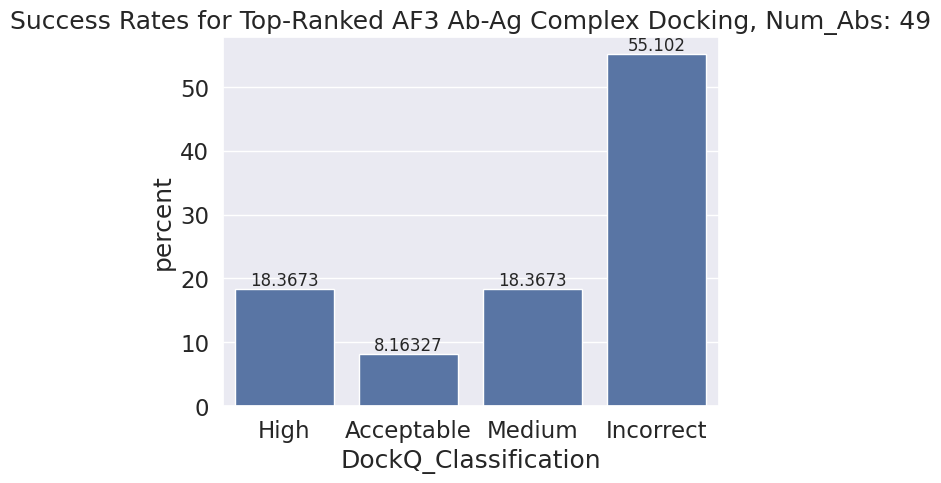

In [22]:
data_df = top_df[(top_df['Bound_Unbound']=='bound')&(top_df['Protein_type']=='antibody')].drop_duplicates(subset=['Native_PDB'])
ax = sns.countplot(data=data_df,x='DockQ_Classification',order=['High','Acceptable','Medium','Incorrect'],stat='percent')
ax.set_title("Success Rates for Top-Ranked AF3 Ab-Ag Complex Docking, Num_Abs: {}".format(data_df.shape[0]))
sns.set(font_scale=1.0)
ax.bar_label(ax.containers[0])
mybenchmark_abs = data_df.PDB_short.unique().tolist()

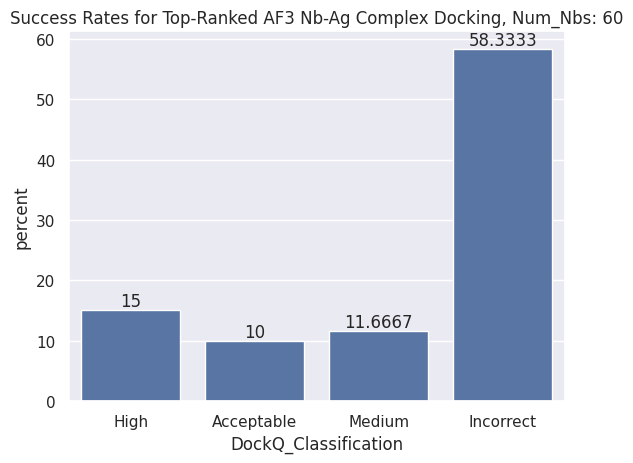

In [23]:
data_df = top_df[(top_df['Bound_Unbound']=='bound')&(top_df['Protein_type']=='nanobody')] #.drop_duplicates(subset=['Native_PDB'])
ax = sns.countplot(data=data_df,x='DockQ_Classification',order=['High','Acceptable','Medium','Incorrect'],stat='percent')
ax.set_title("Success Rates for Top-Ranked AF3 Nb-Ag Complex Docking, Num_Nbs: {}".format(data_df.shape[0]))
sns.set(font_scale=1.0)
ax.bar_label(ax.containers[0])
mybenchmark_abs = data_df.PDB_short.unique().tolist()

[Text(0, 0, '2.39521'),
 Text(0, 0, '14.3713'),
 Text(0, 0, '6.58683'),
 Text(0, 0, '76.6467')]

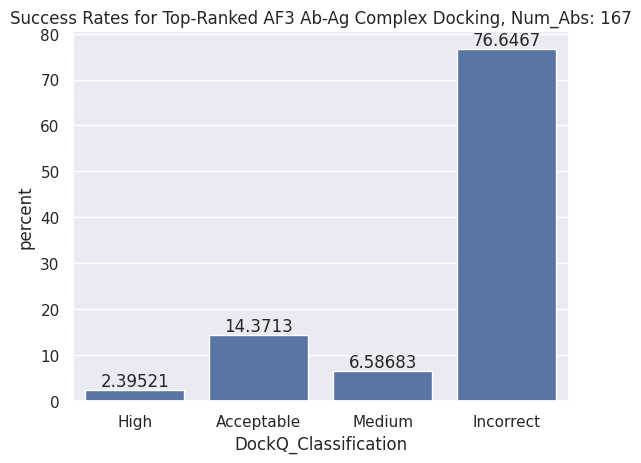

In [24]:
data_df = af2m_dock_scores[af2m_dock_scores['Protein_type']=='antibody']
ax = sns.countplot(data=data_df,x='DockQ_Classification',order=['High','Acceptable','Medium','Incorrect'],stat='percent')
ax.set_title("Success Rates for Top-Ranked AF3 Ab-Ag Complex Docking, Num_Abs: {}".format(data_df.shape[0]))
sns.set(font_scale=1.0)
ax.bar_label(ax.containers[0])
# mybenchmark_abs = data_df.PDB_short.unique().tolist()

[Text(0, 0, '1.38889'),
 Text(0, 0, '5.55556'),
 Text(0, 0, '4.16667'),
 Text(0, 0, '88.8889')]

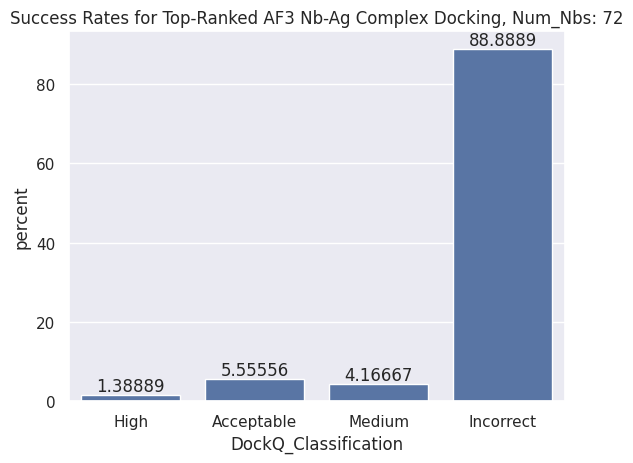

In [25]:
data_df = af2m_dock_scores[af2m_dock_scores['Protein_type']=='nanobody']
ax = sns.countplot(data=data_df,x='DockQ_Classification',order=['High','Acceptable','Medium','Incorrect'],stat='percent')
ax.set_title("Success Rates for Top-Ranked AF3 Nb-Ag Complex Docking, Num_Nbs: {}".format(data_df.shape[0]))
sns.set(font_scale=1.0)
ax.bar_label(ax.containers[0])

[Text(0, 0, '26.8657'),
 Text(0, 0, '4.47761'),
 Text(0, 0, '19.403'),
 Text(0, 0, '49.2537')]

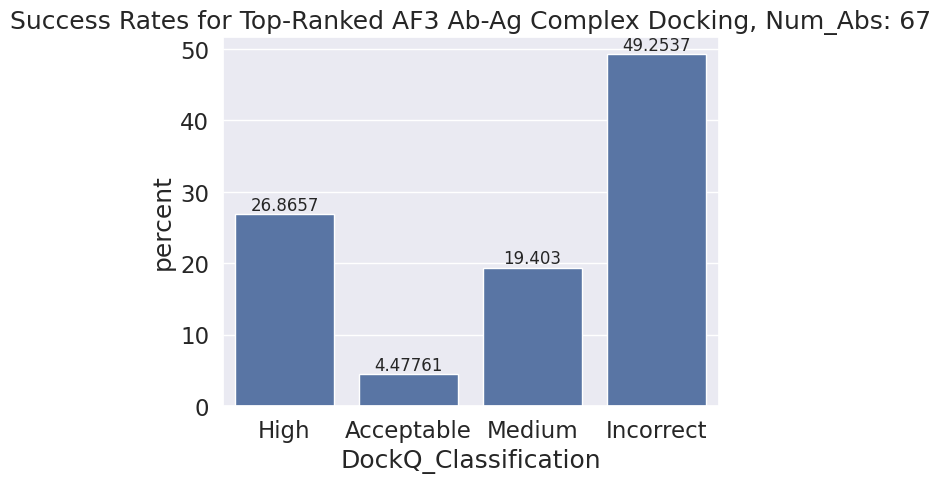

In [10]:
data_df = pd.read_csv("/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchmark/New_AF3_Benchmark/results/round_7/datafiles/ared_af3_dockqs.csv",index_col='Unnamed: 0')
dockqclassifs = []
for i in range(data_df.shape[0]):
    if data_df.iloc[i].DockQ < 0.23:
        dockqclassifs.append('Incorrect')
    elif 0.23<=data_df.iloc[i].DockQ<0.49:
        dockqclassifs.append('Acceptable')
    elif 0.49<=data_df.iloc[i].DockQ<0.8:
        dockqclassifs.append('Medium')
    elif data_df.iloc[i].DockQ>=0.8:
        dockqclassifs.append('High')
data_df['DockQ_Classification'] =dockqclassifs
ax = sns.countplot(data=data_df,x='DockQ_Classification',order=['High','Acceptable','Medium','Incorrect'],stat='percent')
ax.set_title("Success Rates for Top-Ranked AF3 Ab-Ag Complex Docking, Num_Abs: {}".format(data_df.shape[0]))
sns.set(font_scale=1.0)
ax.bar_label(ax.containers[0])
# mybenchmark_abs = data_df.PDB_short.unique().tolist()

In [12]:
data_df[data_df['DockQ_Classification']=='Incorrect'].to_csv("results/round_10/incorrect_af3_db5bench.csv")

In [115]:
# OLD
# AF3_ab_results = pd.DataFrame({"Model":['AF3-Server Abs'],"Incorrect":[52.48],"Acceptable":[8.51],"Medium":[16.31],"High":[8.51]})
# AF3_ab_results = pd.DataFrame({"Model":['AF3-Server Abs'],"Incorrect":[61.86],"Acceptable":[11.02],"Medium":[16.10],"High":[11.02]})
# AF3_nb_results = pd.DataFrame({"Model":['AF3-Server Nbs'],"Incorrect":[68.57],"Acceptable":[8.57],"Medium":[11.43],"High":[11.43]})
# newdockqs_summary = pd.concat([newdockqs_summary,AF3_ab_results,AF3_nb_results],axis=0)
# melted_dockingcomparison = pd.melt(newdockqs_summary,id_vars=['Model'],value_vars=['Incorrect','Acceptable','Medium','High'],var_name="DockQ Classification",value_name='Success Rate')
# newdockqs_summary_cumulative = newdockqs_summary
# newdockqs_summary_cumulative
# newdockqs_summary_cumulative.loc[:,'Medium'] = [11.94 , 17.91 , 27.12 , 22.86]
# newdockqs_summary_cumulative.loc[:,'Acceptable'] = [20.9 , 43.28 , 38.14 , 31.43]
# melted_newdockqs_summary_cumulative = pd.melt(newdockqs_summary_cumulative,id_vars=['Model'],value_vars=['Incorrect','Acceptable','Medium','High'],var_name="DockQ Classification",value_name='Success Rate')
# melted_newdockqs_summary_cumulative

In [21]:
# AF3_ab_results = pd.DataFrame({"Model":['AF3-Server Abs'],"Incorrect":[52.48],"Acceptable":[8.51],"Medium":[16.31],"High":[8.51]})
AF2_ab_results = pd.DataFrame({"Model":['AF2.3-Multimer Abs'],"Incorrect":[76.65],"Acceptable":[14.37],"Medium":[6.59],"High":[2.40]})
AF2_nb_results = pd.DataFrame({"Model":['AF2.3-Multimer Nbs'],"Incorrect":[88.89],"Acceptable":[5.56],"Medium":[4.17],"High":[1.39]})

AF3_ab_results = pd.DataFrame({"Model":['AF3-Server Abs'],"Incorrect":[55.10],"Acceptable":[8.16],"Medium":[18.37],"High":[18.37]})
AF3_nb_results = pd.DataFrame({"Model":['AF3-Server Nbs'],"Incorrect":[58.33],"Acceptable":[10.00],"Medium":[11.67],"High":[15.00]})

newdockqs_summary = pd.concat([AF2_ab_results,AF2_nb_results,AF3_ab_results,AF3_nb_results],axis=0)
melted_dockingcomparison = pd.melt(newdockqs_summary,id_vars=['Model'],value_vars=['Incorrect','Acceptable','Medium','High'],var_name="DockQ Classification",value_name='Success Rate')
newdockqs_summary_cumulative = newdockqs_summary
newdockqs_summary_cumulative
newdockqs_summary_cumulative.loc[:,'Medium'] = [8.99 , 5.56 , 36.74 , 26.67]
newdockqs_summary_cumulative.loc[:,'Acceptable'] = [23.36 , 11.12 , 44.90 , 36.67]
melted_newdockqs_summary_cumulative = pd.melt(newdockqs_summary_cumulative,id_vars=['Model'],value_vars=['Incorrect','Acceptable','Medium','High'],var_name="DockQ Classification",value_name='Success Rate')
melted_newdockqs_summary_cumulative

,Model,DockQ Classification,Success Rate
0,AF2.3-Multimer Abs,Incorrect,76.65
1,AF2.3-Multimer Nbs,Incorrect,88.89
2,AF3-Server Abs,Incorrect,55.10
3,AF3-Server Nbs,Incorrect,58.33
4,AF2.3-Multimer Abs,Acceptable,23.36
5,AF2.3-Multimer Nbs,Acceptable,11.12
6,AF3-Server Abs,Acceptable,44.90
7,AF3-Server Nbs,Acceptable,36.67
8,AF2.3-Multimer Abs,Medium,8.99
9,AF2.3-Multimer Nbs,Medium,5.56


# Panels

## Panel 0: Benchmark Characterization

In [24]:
def readin_align(path_,hitsornot,benchvtrain):
    align_df = pd.read_csv(path_,sep='\t',header=None)
    if hitsornot:
        align_df.columns = ['PDB_1','PDB_2','alnScore','Seq_ID','E-value','PDB_1_start','PDB_1_end','PDB_1_len','PDB_2_start','PDB_2_end','PDB_2_len']
        align_df=align_df[align_df['PDB_1']!=align_df['PDB_2']]
        align_df['Dir_1'] = [x.split('|')[0] for x in align_df.PDB_1]
        align_df['PDB_1_Source'] = [x.split('|')[-1] for x in align_df.PDB_1]
        align_df['PDB_1'] = [x.split('|')[1] for x in align_df.PDB_1]
        align_df['PDB_1_short'] = ['_'.join(x.split('_')[-2:]) for x in align_df.PDB_1]
    else:
        if benchvtrain == 'train':
            align_df.columns = ['PDB_1','PDB_2','Seq_ID','alignment length','num_mismatches','num_gapopenings','query_domainstart','query_domainend','target_domainstart','target_domainend','E-value','Bit Score']
            align_df=align_df[align_df['PDB_1']!=align_df['PDB_2']]
            align_df['Dir_1'] = [x.split('|')[0] for x in align_df.PDB_1]
            align_df['PDB_1_Source'] = [x.split('|')[-1] for x in align_df.PDB_1]
            align_df['PDB_2_Source'] = [x.split('|')[-1] for x in align_df.PDB_2]
            align_df['PDB_1'] = [x.split('|')[1] for x in align_df.PDB_1]
            align_df['PDB_2'] = [x.split('|')[0] for x in align_df.PDB_2]
            align_df['PDB_1_short'] = ['_'.join(x.split('_')[-2:]) for x in align_df.PDB_1]
        else:
            align_df.columns = ['PDB_1','PDB_2','Seq_ID','alignment length','num_mismatches','num_gapopenings','query_domainstart','query_domainend','target_domainstart','target_domainend','E-value','Bit Score']
            align_df=align_df[align_df['PDB_1']!=align_df['PDB_2']]
            align_df['Dir_1'] = [x.split('|')[0] for x in align_df.PDB_1]
            align_df['Dir_2'] = [x.split('|')[0] for x in align_df.PDB_2]
            align_df['PDB_1_Source'] = [x.split('|')[-1] for x in align_df.PDB_1]
            align_df['PDB_2_Source'] = [x.split('|')[-1] for x in align_df.PDB_2]
            align_df['PDB_1'] = [x.split('|')[1] for x in align_df.PDB_1]
            align_df['PDB_2'] = [x.split('|')[1] for x in align_df.PDB_2]
            align_df['PDB_1_short'] = ['_'.join(x.split('_')[-2:]) for x in align_df.PDB_1]
            align_df['PDB_2_short'] = ['_'.join(x.split('_')[-2:]) for x in align_df.PDB_2]
            
    return align_df

In [25]:
abs_list = final_af3_benchmark[final_af3_benchmark['Protein_type']=='antibody'].PDB_short.unique()
nbs_list = final_af3_benchmark[final_af3_benchmark['Protein_type']=='nanobody'].PDB_short.unique()

In [26]:
def maxag(df,x):
    max_seqid = df[df['PDB_1']==x].Seq_ID.max()
    all_rows = df[(df['PDB_1']==x)&(df['Seq_ID']==max_seqid)].iloc[0]
    return all_rows


In [27]:
# Antigen overlap
nb_agseq_bench2train = readin_align('results/round_8/nb_bench2trainag_align.tsv',False,'train')
nb_agseq_bench2train

,PDB_1,PDB_2,Seq_ID,alignment length,num_mismatches,num_gapopenings,query_domainstart,query_domainend,target_domainstart,target_domainend,E-value,Bit Score,Dir_1,PDB_1_Source,PDB_2_Source,PDB_1_short
0,8k3k_0.pdb,7mji_0.pdb,0.963,194,7,0,1,194,2,195,9.069000e-128,395,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8k3k_0.pdb
1,8k3k_0.pdb,7mjh_0.pdb,0.963,194,7,0,1,194,290,483,9.069000e-128,395,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8k3k_0.pdb
2,8k3k_0.pdb,7mjh_1.pdb,0.963,194,7,0,1,194,290,483,9.069000e-128,395,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8k3k_0.pdb
3,8k3k_0.pdb,7mjh_2.pdb,0.963,194,7,0,1,194,290,483,9.069000e-128,395,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8k3k_0.pdb
4,8k3k_0.pdb,7klw_0.pdb,0.955,194,9,0,1,194,1,194,1.551000e-126,392,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8k3k_0.pdb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16673,renum_stitched_7t9i_0.pdb,6ukt_0.pdb,0.434,168,94,0,49,216,119,285,4.594000e-36,132,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7t9i_0.pdb
16674,renum_stitched_7xkd_0.pdb,7rg9_0.pdb,0.857,221,31,0,6,226,4,220,1.053000e-126,394,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7xkd_0.pdb
16675,renum_stitched_7xkd_0.pdb,6ukt_0.pdb,0.439,172,94,0,50,221,118,285,9.451000e-38,137,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7xkd_0.pdb
16676,renum_stitched_8hxr_1.pdb,6j7w_1.pdb,1.000,38,0,0,1,38,2,39,1.027000e-24,89,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8hxr_1.pdb


In [28]:
all_nb_ags = nb_agseq_bench2train.PDB_1.unique().tolist()
max_bench_seqids_nb_ag = pd.concat([pd.DataFrame(maxag(nb_agseq_bench2train,x)).T for x in all_nb_ags])
max_bench_seqids_nb_ag

,PDB_1,PDB_2,Seq_ID,alignment length,num_mismatches,num_gapopenings,query_domainstart,query_domainend,target_domainstart,target_domainend,E-value,Bit Score,Dir_1,PDB_1_Source,PDB_2_Source,PDB_1_short
0,8k3k_0.pdb,7mji_0.pdb,0.963,194,7,0,1,194,2,195,0.0,395,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8k3k_0.pdb
132,renum_stitched_8ftg_0.pdb,6qtl_0.pdb,0.983,117,2,0,1,117,1,117,0.0,245,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8ftg_0.pdb
250,8g74_1.pdb,7d2z_0.pdb,1.0,206,0,0,314,519,3,208,0.0,440,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8g74_1.pdb
305,renum_stitched_8fls_0.pdb,7rg9_0.pdb,0.819,231,39,0,3,233,4,220,0.0,391,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8fls_0.pdb
307,7z1a_0.pdb,7f5h_0.pdb,1.0,196,0,0,1,196,1,196,0.0,428,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7z1a_0.pdb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16485,7z85_0.pdb,7d2z_0.pdb,1.0,206,0,0,234,439,3,208,0.0,440,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7z85_0.pdb
16540,8cyj_0.pdb,7mej_0.pdb,1.0,194,0,0,1,194,1,194,0.0,424,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8cyj_0.pdb
16672,renum_stitched_7t9i_0.pdb,7rg9_0.pdb,0.842,220,34,0,2,221,4,220,0.0,385,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7t9i_0.pdb
16674,renum_stitched_7xkd_0.pdb,7rg9_0.pdb,0.857,221,31,0,6,226,4,220,0.0,394,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7xkd_0.pdb


In [45]:
benchmark_nb_aglist1 = max_bench_seqids_nb_ag[max_bench_seqids_nb_ag['PDB_short'].isin(final_af3_benchmark[(final_af3_benchmark['Protein_type']=='nanobody')&(final_af3_benchmark['Bound_Unbound']=='bound')].PDB_short.unique().tolist())].drop_duplicates(subset=['PDB_short'])
benchmark_nb_aglist2 = final_af3_benchmark[(final_af3_benchmark['Protein_type']=='nanobody')&(final_af3_benchmark['Bound_Unbound']=='bound')&(~final_af3_benchmark['PDB_short'].isin(benchmark_nb_aglist1.PDB_short.unique().tolist()))].loc[:,['AF3_PDB','PDB_short']].rename(columns={"AF3_PDB":"PDB"})
benchmark_nb_aglist2['Seq_ID_train_max'] = [1.0]*benchmark_nb_aglist2.shape[0]
benchmark_nb_aglist = pd.concat([benchmark_nb_aglist2,benchmark_nb_aglist1]).drop_duplicates(subset=['PDB_short'])

KeyError: 'PDB_short'

In [32]:
nb_bound_bench = final_af3_benchmark[(final_af3_benchmark['Protein_type']=='nanobody')&(final_af3_benchmark['Bound_Unbound']=='bound')] #.PDB_short.unique().shape

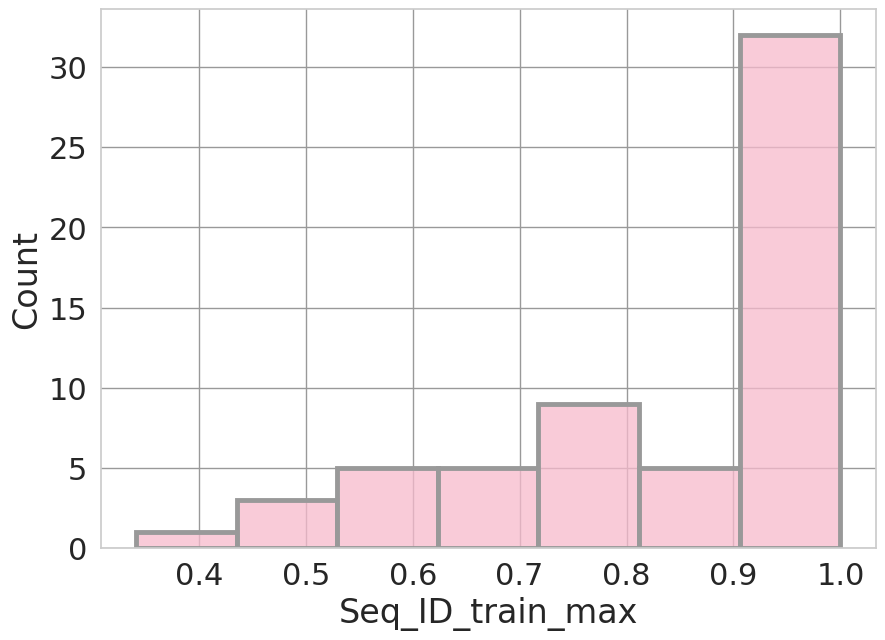

In [25]:
# max_bench_seqids_nb_ag = pd.concat([pd.DataFrame(maxag(nb_agseq_bench2train,x)).T for x in all_nb_ags])
sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
sns.histplot(data=benchmark_nb_aglist.drop_duplicates(subset=['PDB']),x='Seq_ID_train_max',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0])
sns.set(font_scale=2)
plt.savefig("results/round_8/plots/nb_agseqid_histplot.svg",format='svg',dpi=700,transparent=True,bbox_inches='tight')

In [33]:
# unique Nb antigens

nb_sabdab[nb_sabdab['pdb'].isin([x.split('_')[0] for x in nb_bound_bench.PDB_short.unique().tolist()])].drop_duplicates(subset=['pdb']).value_counts(subset=['antigen_name']) #&(nb_sabdab['antigen_name']=='spike glycoprotein')

antigen_name                                                                     
spike glycoprotein                                                                   10
spike protein s1                                                                     10
equilibrative nucleoside/nucleobase transporter                                       2
fragilysin                                                                            2
atp-dependent dna helicase q5                                                         2
cystinosin homolog                                                                    2
cyclin-dependent kinase 7                                                             1
cftr inhibitory factor                                                                1
capsid protein vp1                                                                    1
cysteine-rich small secreted protein css, putative                                    1
dipeptide and tripeptide permease b   

In [34]:
ab_bound_bench = final_af3_benchmark[(final_af3_benchmark['Protein_type']=='antibody')&(final_af3_benchmark['Bound_Unbound']=='bound')]

In [24]:
ab_sabdab[(ab_sabdab['pdb'].isin([x.split('_')[0] for x in ab_bound_bench.PDB_short.unique().tolist()]))].drop_duplicates(subset=['pdb']).value_counts(subset=['antigen_name']) #.antigen_name.unique().shape

antigen_name                                                            
spike protein s1                                                            7
spike glycoprotein                                                          7
gametocyte surface protein p45/48                                           2
long neurotoxin 1                                                           2
neuraminidase                                                               2
b- and t-lymphocyte attenuator                                              1
core protein                                                                1
frizzled-2                                                                  1
gametocyte surface protein p230                                             1
alpha-elapitoxin-dpp2d                                                      1
activin receptor type-1                                                     1
alpha-bungarotoxin                                                   

In [37]:
bench_nb_ags = nb_sabdab[(nb_sabdab['pdb'].isin([x.split('_')[0] for x in nb_bound_bench.PDB_short.unique().tolist()]))].antigen_name.unique().tolist()
train_nb_ags = nb_sabdab_precutoff.antigen_name.unique().tolist()

nb_overlap_ags = [x for x in train_nb_ags if x in bench_nb_ags]
nb_overlap_ags

[nan, 'spike protein s1', 'spike glycoprotein']

In [38]:
bench_ab_ags = ab_sabdab[(ab_sabdab['pdb'].isin([x.split('_')[0] for x in ab_bound_bench.PDB_short.unique().tolist()]))].antigen_name.unique().tolist()
train_ab_ags = ab_sabdab_precutoff.antigen_name.unique().tolist()

ab_overlap_ags = [x for x in train_ab_ags if x in bench_ab_ags]
ab_overlap_ags

['spike glycoprotein',
 nan,
 'programmed cell death 1 ligand 1',
 'fusion glycoprotein f0',
 'spike protein s1',
 'neuraminidase',
 'v-type immunoglobulin domain-containing suppressor of t-cell activation ',
 'core protein',
 'toxin b',
 'programmed cell death protein 1',
 'gametocyte surface protein p230',
 'gametocyte surface protein p45/48',
 't-cell surface glycoprotein cd8 alpha chain',
 'spike protein s2',
 'isoform 2 of basigin']

In [39]:
# Antigen overlap

ab_agseq_bench2train = readin_align('results/round_8/ab_bench2trainag_align.tsv',False,'train')
ab_agseq_bench2train

,PDB_1,PDB_2,Seq_ID,alignment length,num_mismatches,num_gapopenings,query_domainstart,query_domainend,target_domainstart,target_domainend,E-value,Bit Score,Dir_1,PDB_1_Source,PDB_2_Source,PDB_1_short
0,renum_stitched_7wbz_0.pdb,6xc4_1.pdb,1.000,194,0,0,1,194,1,194,1.959000e-137,425,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7wbz_0.pdb
1,renum_stitched_7wbz_0.pdb,7lop_0.pdb,1.000,194,0,0,1,194,1,194,1.959000e-137,425,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7wbz_0.pdb
2,renum_stitched_7wbz_0.pdb,7l7e_0.pdb,1.000,194,0,0,1,194,1,194,1.959000e-137,425,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7wbz_0.pdb
3,renum_stitched_7wbz_0.pdb,7l7e_1.pdb,1.000,194,0,0,1,194,1,194,1.959000e-137,425,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7wbz_0.pdb
4,renum_stitched_7wbz_0.pdb,7lop_2.pdb,1.000,194,0,0,1,194,1,194,1.959000e-137,425,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7wbz_0.pdb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307089,fv_unbound_renum_stitched_8dua_1.pdb,6cm3_3.pdb,0.544,81,35,0,1,77,37,117,5.438000e-22,87,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8dua_1.pdb
307090,fv_unbound_renum_stitched_8dua_1.pdb,6cm3_4.pdb,0.544,81,35,0,1,77,37,117,5.438000e-22,87,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8dua_1.pdb
307091,fv_unbound_renum_stitched_8dua_1.pdb,6cm3_5.pdb,0.544,81,35,0,1,77,37,117,5.438000e-22,87,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8dua_1.pdb
307092,fv_unbound_renum_stitched_8dua_1.pdb,3mac_0.pdb,0.495,37,18,0,51,87,116,152,8.859000e-05,37,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8dua_1.pdb


In [40]:
all_ab_ags = ab_agseq_bench2train.PDB_1.unique().tolist()
max_bench_seqids_ab_ag = pd.concat([pd.DataFrame(maxag(ab_agseq_bench2train,x)).T for x in all_ab_ags])
max_bench_seqids_ab_ag

,PDB_1,PDB_2,Seq_ID,alignment length,num_mismatches,num_gapopenings,query_domainstart,query_domainend,target_domainstart,target_domainend,E-value,Bit Score,Dir_1,PDB_1_Source,PDB_2_Source,PDB_1_short
0,renum_stitched_7wbz_0.pdb,6xc4_1.pdb,1.0,194,0,0,1,194,1,194,0.0,425,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7wbz_0.pdb
1133,renum_stitched_8dlw_0.pdb,7m3i_0.pdb,1.0,217,0,0,265,481,1,217,0.0,467,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8dlw_0.pdb
1505,renum_stitched_8dpl_4.pdb,7kfh_0.pdb,0.974,177,4,0,1,174,2,178,0.0,365,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8dpl_4.pdb
1555,renum_stitched_8ek1_1.pdb,6o2b_2.pdb,0.942,12,1,0,5,16,1,12,0.03481,26,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8ek1_1.pdb
1558,renum_stitched_7qt0_4.pdb,1ngp_0.pdb,0.841,214,34,0,1,213,1,214,0.0,374,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7qt0_4.pdb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
305417,renum_stitched_8euu_0.pdb,5drz_0.pdb,1.0,15,0,0,62,76,1,15,0.00175,35,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8euu_0.pdb
305881,renum_stitched_7uz8_2.pdb,7f6z_0.pdb,0.966,194,7,0,279,472,1,194,0.0,397,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7uz8_2.pdb
306209,renum_stitched_7ujk_1.pdb,3t3p_0.pdb,0.994,453,3,0,1,453,1,453,0.0,953,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7ujk_1.pdb
306696,7wpe_0.pdb,7f6z_0.pdb,0.966,194,7,0,269,462,1,194,0.0,397,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7wpe_0.pdb


In [41]:
benchmark_ab_aglist1 = pd.concat([max_bench_seqids_ab_ag[max_bench_seqids_ab_ag['PDB_1_short'].str.contains(x)] for x in [x.split('.')[0] for x in abs_list.tolist()]])
benchmark_ab_aglist2 = final_af3_benchmark[(final_af3_benchmark['Protein_type']=='antibody')&(final_af3_benchmark['Bound_Unbound']=='bound')&(~final_af3_benchmark['PDB_short'].isin([x+'.pdb' for x in benchmark_ab_aglist1.PDB_1_short.unique().tolist()]))].loc[:,['AF3_PDB','PDB_short']].rename(columns={"AF3_PDB":"PDB_1","PDB_short":'PDB_1_short'}).drop_duplicates(subset=['PDB_1_short'])
benchmark_ab_aglist2['Seq_ID'] = [1.0]*benchmark_ab_aglist2.shape[0]
benchmark_ab_aglist = pd.concat([benchmark_ab_aglist2,benchmark_ab_aglist1]).drop_duplicates(subset=['PDB_1_short'])
# benchmark_ab_aglist1.shape

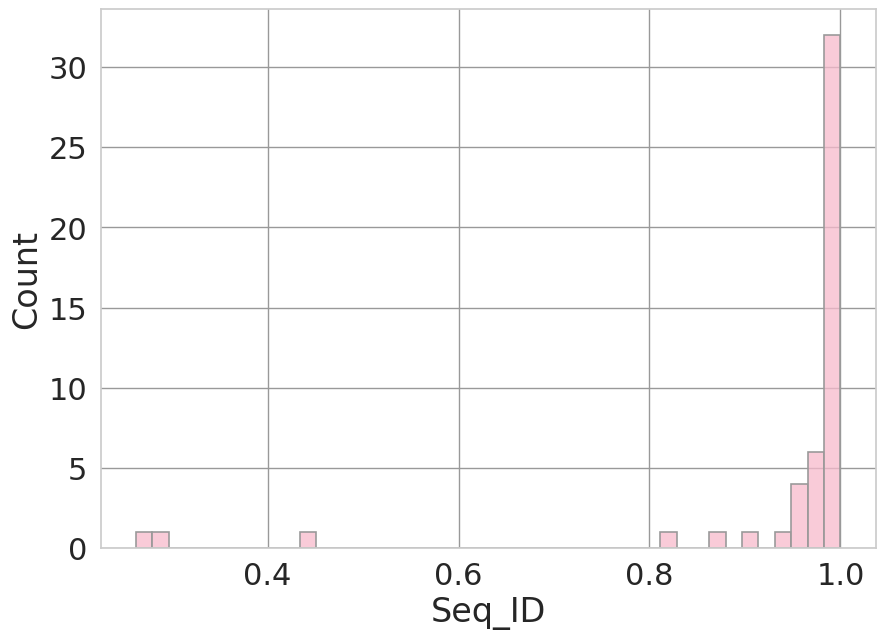

In [ ]:
sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
sns.histplot(data=benchmark_ab_aglist.drop_duplicates(subset=['PDB_1']),x='Seq_ID',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0])
sns.set(font_scale=2)


In [9]:
ab_sabdab_path = "../sabdab_summary_all_240531.tsv"
ab_sabdab = pd.read_csv(ab_sabdab_path,delimiter='\t')
final_absabdab = pd.concat([pd.DataFrame(ab_sabdab[ab_sabdab['pdb']==x.split('_')[0]].iloc[int(x.split('_')[-1].split('.')[0])]).T for x in abs_list])
final_absabdab.loc[final_absabdab[final_absabdab['pdb']=='7q6c'].index.values[:],'light_ctype'] ='Kappa'

trainvbench_ab_ag = pd.concat([final_absabdab,ab_sabdab_precutoff],keys=['Benchmark','Training']).reset_index().drop(columns=['level_1']).rename(columns={"level_0":"Structure Set"})
trainvbench_ab_ag.head()

/tmp/ipykernel_137928/1301031484.py:6: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  trainvbench_ab_ag = pd.concat([final_absabdab,ab_sabdab_precutoff],keys=['Benchmark','Training']).reset_index().drop(columns=['level_1']).rename(columns={"level_0":"Structure Set"})


,Structure Set,pdb,Hchain,Lchain,model,antigen_chain,antigen_type,antigen_het_name,antigen_name,short_header,...,scfv,engineered,heavy_subclass,light_subclass,light_ctype,affinity,delta_g,affinity_method,temperature,pmid
0,Benchmark,8gkk,H,L,0,NaN,NaN,NaN,NaN,IMMUNE SYSTEM,...,False,True,IGHV3,IGKV3,Kappa,NaN,NaN,NaN,NaN,NaN
1,Benchmark,8eqa,H,L,0,NaN,NaN,NaN,NaN,IMMUNE SYSTEM,...,False,True,IGHV4,IGKV1,Kappa,NaN,NaN,NaN,NaN,NaN
2,Benchmark,7rpt,A,B,0,NaN,NaN,NaN,NaN,ANTIVIRAL PROTEIN,...,False,True,IGHV3,IGKV2,Kappa,NaN,NaN,NaN,NaN,NaN
3,Benchmark,8dkf,A,B,0,NaN,NaN,NaN,NaN,IMMUNE SYSTEM,...,False,True,IGHV3,IGKV2,Kappa,NaN,NaN,NaN,NaN,NaN
4,Benchmark,8t0o,H,L,0,NaN,NaN,NaN,NaN,IMMUNE SYSTEM,...,False,True,IGHV1,IGKV1,Kappa,NaN,NaN,NaN,NaN,NaN


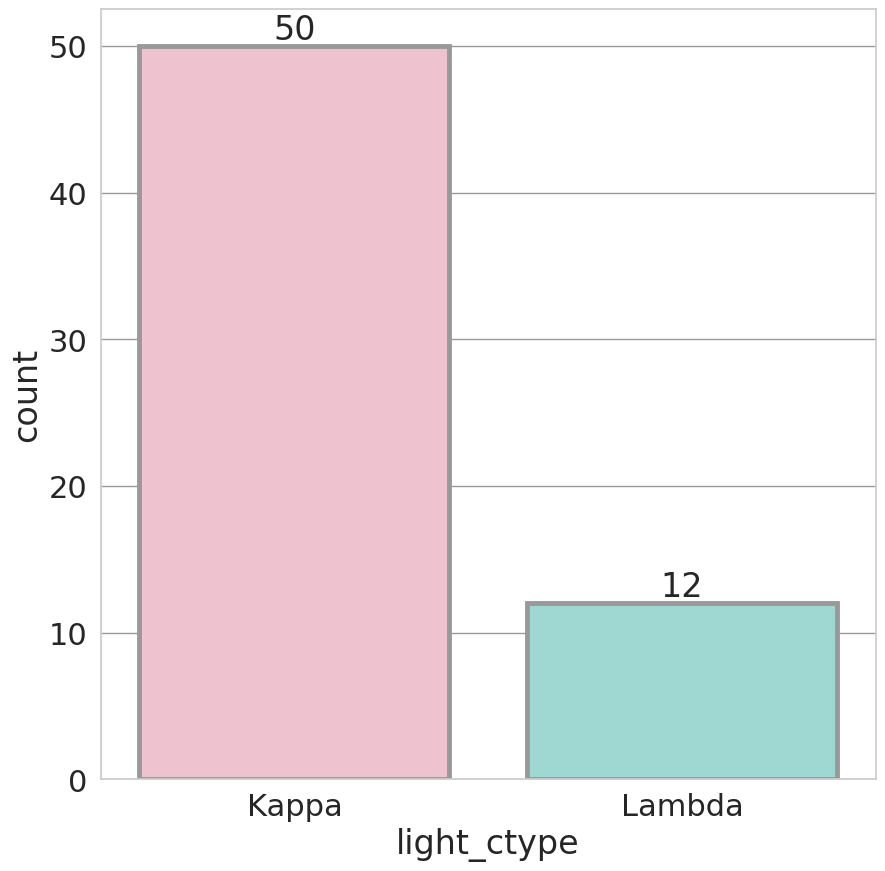

In [ ]:
# lambda/kappa breakdown for abs


sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,10))
ax=sns.countplot(data=final_absabdab,x='light_ctype',hue='light_ctype',palette=pastel_palette[:2],edgecolor=".6",\
                    lw=3.5)
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
sns.set(font_scale=2)


In [ ]:
trainvbench_ab_ag_limited = trainvbench_ab_ag.loc[:,['Structure Set','light_ctype']]
trainvbench_ab_ag_ratiodf = pd.DataFrame(trainvbench_ab_ag_limited[trainvbench_ab_ag_limited['light_ctype']!='unknown'].value_counts(subset=['Structure Set','light_ctype'])).reset_index()
trainvbench_ab_ag = pd.pivot_table(trainvbench_ab_ag_ratiodf, values='count', columns=['light_ctype'],
                       index=['Structure Set'], aggfunc="sum")

,Structure Set,light_ctype,count
0,Training,Kappa,6802
1,Training,Lambda,1850
2,Benchmark,Kappa,50
3,Benchmark,Lambda,12


In [ ]:
trainvbench_ab_ag['Kappa Ratio'] = 100 * trainvbench_ab_ag['Kappa'] / (trainvbench_ab_ag['Kappa'] + trainvbench_ab_ag['Lambda'])
trainvbench_ab_ag['Lambda Ratio'] = 100 * trainvbench_ab_ag['Lambda'] / (trainvbench_ab_ag['Kappa'] + trainvbench_ab_ag['Lambda'])
trainvbench_ab_ag = trainvbench_ab_ag.rename(columns={"Lambda":"Lambda counts",'Kappa':"Kappa counts",'Kappa Ratio':'Kappa','Lambda Ratio':'Lambda'})

light_ctype,Kappa,Lambda
Structure Set,,
Benchmark,50,12
Training,6802,1850


/tmp/ipykernel_137928/3507078993.py:4: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  ax = sns.barplot(df1.melt(id_vars=['Structure Set'],value_vars=['Kappa','Lambda'],var_name='Light Chain Type',value_name='Percent'),x='Light Chain Type',y='Percent',\


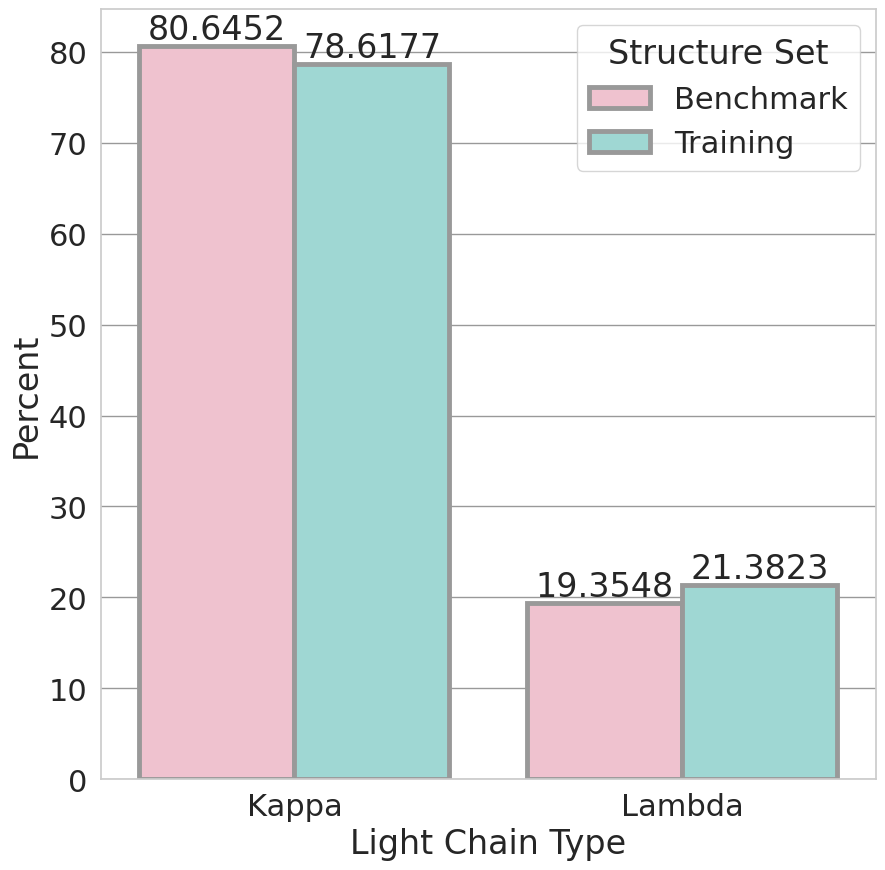

In [ ]:
# PERCENT VERSION USING PIVOT TABLES
# lambda/kappa breakdown for abs ( AF3 training vs bench set...)
sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,10))
ax = sns.barplot(df1.melt(id_vars=['Structure Set'],value_vars=['Kappa','Lambda'],var_name='Light Chain Type',value_name='Percent'),x='Light Chain Type',y='Percent',\
    hue='Structure Set',\
    palette=pastel_palette,\
        edgecolor=".6", lw=3.5)
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
sns.set(font_scale=2)

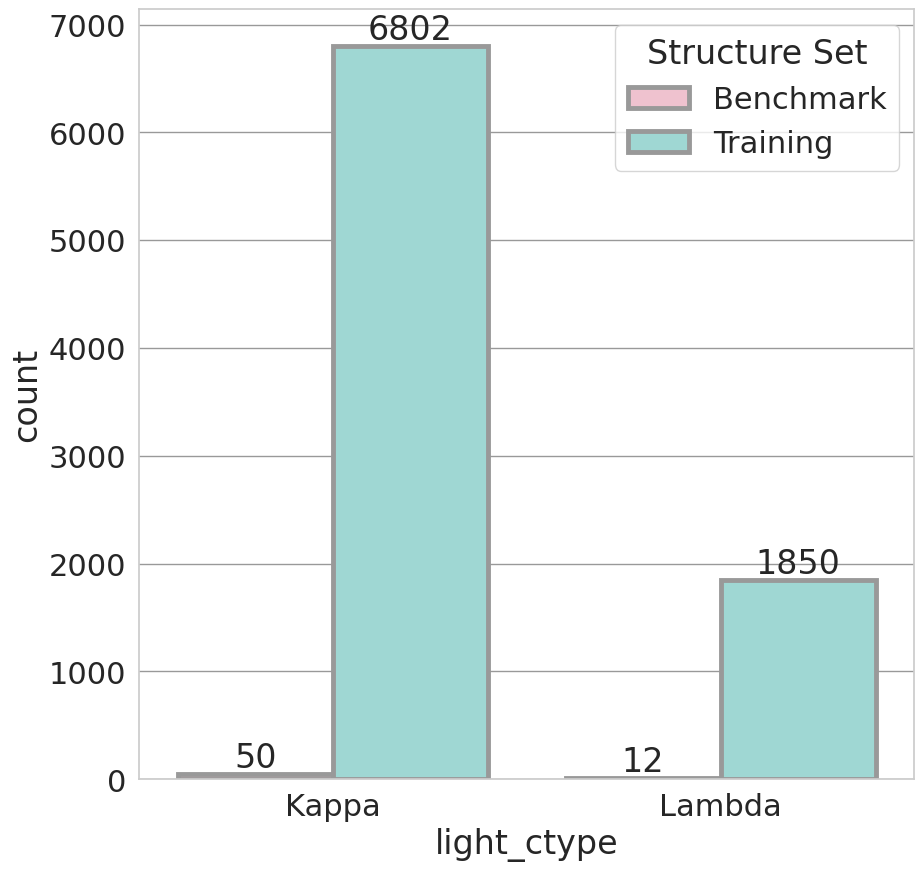

In [ ]:
# lambda/kappa breakdown for abs (in AF3 training set...)
# COUNT VERSION 
ab_sabdab_path = "../sabdab_summary_all_240531.tsv"
ab_sabdab = pd.read_csv(ab_sabdab_path,delimiter='\t')
final_absabdab = trainvbench_ab_ag #pd.concat([pd.DataFrame(ab_sabdab[ab_sabdab['pdb']==x.split('_')[0]].iloc[int(x.split('_')[-1].split('.')[0])]).T for x not in abs_list])
sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,10))
ax=sns.countplot(data=final_absabdab,x='light_ctype',hue='Structure Set',order=['Kappa','Lambda'],palette=pastel_palette[:2],stat='count',edgecolor=".6",\
                    lw=3.5)
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
# ax.bar_label(ax.containers[2])
sns.set(font_scale=2)

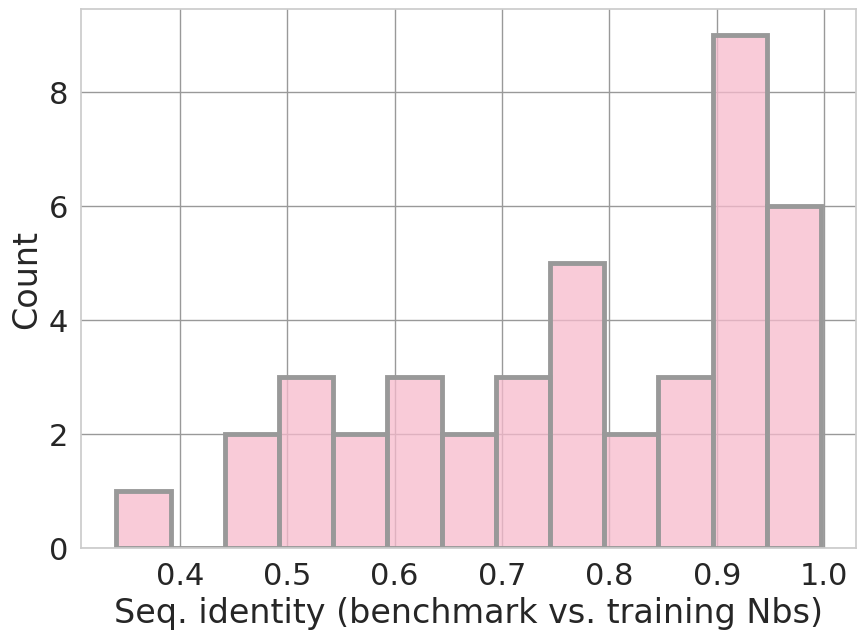

In [ ]:
# Nb concatenated seq ID histogram against training set

nb_max_train_seqids = pd.read_csv("results/round_8/nb_max_train_seqids.csv")
sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
ax=sns.histplot(data=nb_max_train_seqids[nb_max_train_seqids['PDB'].isin(final_af3_benchmark[final_af3_benchmark['Protein_type']=='nanobody'].PDB_short.unique().tolist())],x='Seq_ID_train_max',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0],binwidth=0.05)
sns.set(font_scale=2)
ax.set_xlabel('Seq. identity (benchmark vs. training Nbs)')

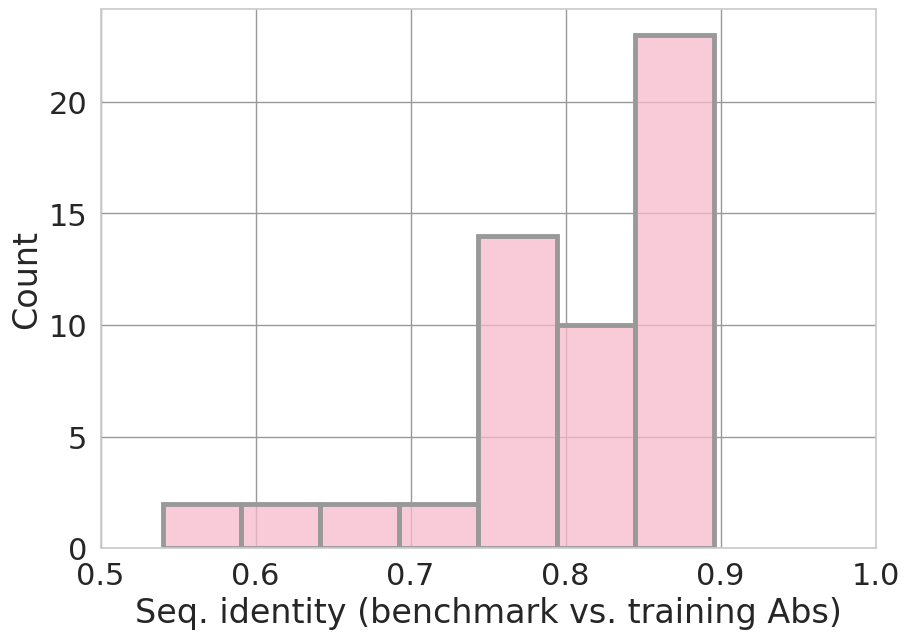

In [ ]:
# Ab concatenated CDR seq ID histogram against training set

ab_max_train_seqids = pd.read_csv("results/round_8/ab_max_train_seqids.csv")
sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
ax=sns.histplot(data=ab_max_train_seqids[ab_max_train_seqids['PDB_short'].isin([x.split('_')[-2] for x in final_af3_benchmark[(final_af3_benchmark['Protein_type']=='antibody')].PDB_short.unique().tolist()])].drop_duplicates(subset=['PDB_short']),x='Seq_ID_train_max',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0],binwidth=0.05)
sns.set(font_scale=2)
plt.xlim(0.5, 1)
ax.set_xlabel('Seq. identity (benchmark vs. training Abs)')

In [42]:
# filtering determined nbs using train2bench seqID
nb_h3_seq_bench2train = pd.read_csv('results/round_8/nb_bench2train_h3_align.tsv',sep='\t',header=None)
nb_h3_seq_bench2train.columns = ['PDB_1','PDB_2','Seq_ID','alignment length','num_mismatches','num_gapopenings','query_domainstart','query_domainend','target_domainstart','target_domainend','E-value','Bit Score']
nb_h3_seq_bench2train=nb_h3_seq_bench2train[nb_h3_seq_bench2train['PDB_1']!=nb_h3_seq_bench2train['PDB_2']]
nb_h3_seq_bench2train['Dir_1'] = [x.split('|')[0] for x in nb_h3_seq_bench2train.PDB_1]
nb_h3_seq_bench2train['PDB_1_Source'] = [x.split('|')[-1] for x in nb_h3_seq_bench2train.PDB_1]
nb_h3_seq_bench2train['PDB_2_Source'] = [x.split('|')[-1] for x in nb_h3_seq_bench2train.PDB_2]
nb_h3_seq_bench2train['PDB_1'] = [x.split('|')[1] for x in nb_h3_seq_bench2train.PDB_1]
nb_h3_seq_bench2train['PDB_2'] = [x.split('|')[0] for x in nb_h3_seq_bench2train.PDB_2]
nb_h3_seq_bench2train

,PDB_1,PDB_2,Seq_ID,alignment length,num_mismatches,num_gapopenings,query_domainstart,query_domainend,target_domainstart,target_domainend,E-value,Bit Score,Dir_1,PDB_1_Source,PDB_2_Source
0,renum_stitched_8haf_0.pdb,7cx4_0.pdb,1.000,19,0,0,1,19,1,19,2.393000e-11,46,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train
1,renum_stitched_8haf_0.pdb,7evw_0.pdb,1.000,19,0,0,1,19,1,19,2.393000e-11,46,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train
2,renum_stitched_8haf_0.pdb,7vab_0.pdb,1.000,19,0,0,1,19,1,19,2.393000e-11,46,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train
3,renum_stitched_8haf_0.pdb,7d7m_0.pdb,1.000,19,0,0,1,19,1,19,2.393000e-11,46,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train
4,renum_stitched_8haf_0.pdb,7v35_0.pdb,1.000,19,0,0,1,19,1,19,2.393000e-11,46,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7189,renum_stitched_8e3z_0.pdb,7rmi_0.pdb,0.868,19,2,0,1,19,1,17,5.111000e-08,37,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train
7190,7zxu_0.pdb,5hvf_0.pdb,0.743,11,3,0,5,15,2,12,5.084000e-02,19,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train
7191,7zxu_0.pdb,5hvh_1.pdb,0.743,11,3,0,5,15,2,12,5.084000e-02,19,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train
7192,7zxu_0.pdb,6b73_1.pdb,0.594,11,4,0,5,15,5,15,8.837000e-01,16,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train


In [44]:
max_train_h3seqids_nb = pd.DataFrame({"PDB":nb_h3_seq_bench2train.PDB_1.unique(),\
                                    "Seq_ID_train_max":[nb_h3_seq_bench2train[nb_h3_seq_bench2train['PDB_1']==x].Seq_ID.max() \
                                                        for x in nb_h3_seq_bench2train.PDB_1.unique().tolist()]})
max_train_h3seqids_nb['PDB_short'] = ['_'.join(x.split('_')[-2:]) for x in max_train_h3seqids_nb.PDB]
max_train_h3seqids_nb

,PDB,Seq_ID_train_max,PDB_short
0,renum_stitched_8haf_0.pdb,1.000,8haf_0.pdb
1,7zk1_1.pdb,0.671,7zk1_1.pdb
2,7th2_1.pdb,0.693,7th2_1.pdb
3,renum_stitched_7tyn_0.pdb,1.000,7tyn_0.pdb
4,renum_stitched_7xkd_0.pdb,1.000,7xkd_0.pdb
...,...,...,...
153,8cwu_0.pdb,0.647,8cwu_0.pdb
154,renum_stitched_8hmp_0.pdb,1.000,8hmp_0.pdb
155,renum_stitched_8e3z_0.pdb,1.000,8e3z_0.pdb
156,7zxu_0.pdb,0.743,7zxu_0.pdb


In [49]:
max_train_h3seqids_nb[max_train_h3seqids_nb['PDB_short'].isin([x for x in final_af3_benchmark[(final_af3_benchmark['Protein_type']=='nanobody')].PDB_short.unique().tolist()])]

,PDB,Seq_ID_train_max,PDB_short
1,7zk1_1.pdb,0.671,7zk1_1.pdb
18,7zml_0.pdb,0.746,7zml_0.pdb
19,8sk5_0.pdb,0.776,8sk5_0.pdb
22,7q6c_0.pdb,1.000,7q6c_0.pdb
27,8cxn_2.pdb,0.817,8cxn_2.pdb
35,7sp8_0.pdb,0.794,7sp8_0.pdb
47,8emz_0.pdb,0.472,8emz_0.pdb
105,7zmm_0.pdb,0.746,7zmm_0.pdb
114,7z1c_0.pdb,0.712,7z1c_0.pdb
122,8cxn_1.pdb,0.817,8cxn_1.pdb


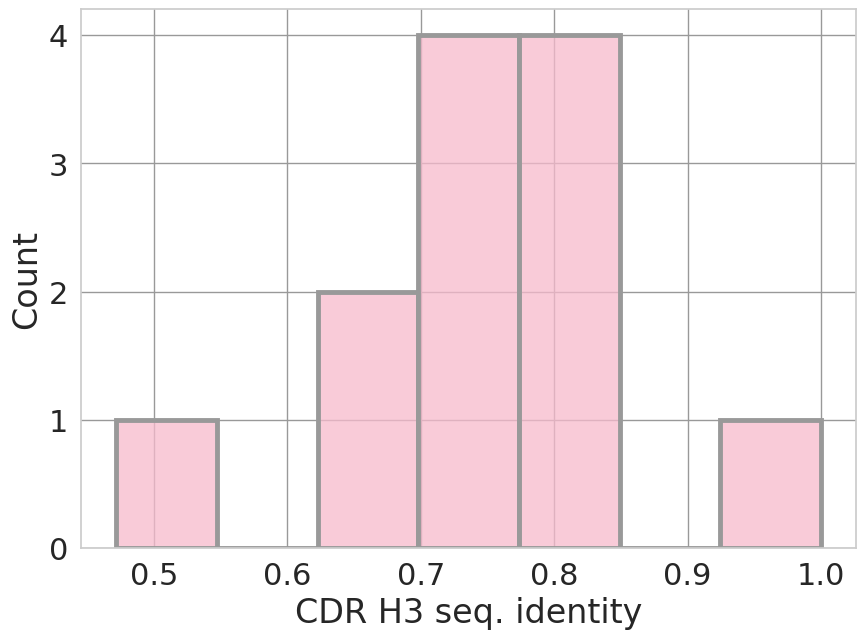

In [ ]:
# Nb CDR H3 seq ID histogram against training set

sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
ax=sns.histplot(data=max_train_h3seqids_nb[max_train_h3seqids_nb['PDB_short'].isin([x for x in final_af3_benchmark[(final_af3_benchmark['Protein_type']=='nanobody')].PDB_short.unique().tolist()])].drop_duplicates(subset=['PDB_short']),x='Seq_ID_train_max',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0])
sns.set(font_scale=2)
ax.set_xlabel('CDR H3 seq. identity')


In [17]:
ab_h3_seq_bench2train = readin_align('results/round_10/ab_bench2train_h3_align.tsv',False,'train')
ab_h3_seq_bench2train

,PDB_1,PDB_2,Seq_ID,alignment length,num_mismatches,num_gapopenings,query_domainstart,query_domainend,target_domainstart,target_domainend,E-value,Bit Score,Dir_1,PDB_1_Source,PDB_2_Source,PDB_1_short
0,renum_stitched_8sdg_1.pdb,6dl8_0.pdb,1.000,9,0,0,5,13,9,17,0.01432,23,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8sdg_1.pdb
1,renum_stitched_8sdg_1.pdb,6dl8_1.pdb,1.000,9,0,0,5,13,9,17,0.01432,23,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8sdg_1.pdb
2,renum_stitched_8sdg_1.pdb,6dlb_0.pdb,1.000,9,0,0,5,13,9,17,0.01432,23,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8sdg_1.pdb
3,renum_stitched_8sdg_1.pdb,6dfh_0.pdb,1.000,9,0,0,5,13,13,21,0.01432,23,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8sdg_1.pdb
4,renum_stitched_8sdg_1.pdb,6dfh_1.pdb,1.000,9,0,0,5,13,13,21,0.01432,23,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8sdg_1.pdb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
458,8da0_0.pdb,7r6x_2.pdb,0.638,13,4,0,6,18,2,14,0.27840,19,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8da0_0.pdb
459,8da0_0.pdb,4ydk_0.pdb,0.743,11,3,0,2,12,2,12,0.27840,19,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8da0_0.pdb
460,8da0_0.pdb,6gg0_0.pdb,0.859,9,1,0,9,17,4,12,0.53100,19,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8da0_0.pdb
461,8da0_0.pdb,1opg_0.pdb,0.758,10,2,0,4,13,4,13,0.73340,18,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,8da0_0.pdb


In [40]:
max_train_h3seqids_ab = pd.DataFrame({"PDB":ab_h3_seq_bench2train.PDB_1.unique(),\
                                    "Seq_ID_train_max":[ab_h3_seq_bench2train[ab_h3_seq_bench2train['PDB_1']==x].Seq_ID.max() \
                                                        for x in ab_h3_seq_bench2train.PDB_1.unique().tolist()]})
max_train_h3seqids_ab['PDB_short'] = ['_'.join(x.split('_')[-2:]) for x in max_train_h3seqids_ab.PDB]
max_train_h3seqids_ab

,PDB,Seq_ID_train_max,PDB_short
0,renum_stitched_8sdg_1.pdb,1.000,8sdg_1.pdb
1,renum_stitched_8e6j_0.pdb,0.989,8e6j_0.pdb
2,renum_8dkf_1.pdb,0.826,8dkf_1.pdb
3,8da1_0.pdb,0.923,8da1_0.pdb
4,8cii_1.pdb,0.942,8cii_1.pdb
5,renum_stitched_7zwi_1.pdb,0.942,7zwi_1.pdb
6,renum_stitched_7yru_0.pdb,0.997,7yru_0.pdb
7,8da0_1.pdb,0.923,8da0_1.pdb
8,8d9y_0.pdb,0.923,8d9y_0.pdb
9,renum_stitched_7t7b_0.pdb,0.921,7t7b_0.pdb


In [15]:
ab_h3_seq_bench2train_hits = readin_align('results/round_10/ab_bench2train_h3_hits.tsv',True,'train')
ab_h3_seq_bench2train_hits

,PDB_1,PDB_2,alnScore,Seq_ID,E-value,PDB_1_start,PDB_1_end,PDB_1_len,PDB_2_start,PDB_2_end,PDB_2_len,Dir_1,PDB_1_Source,PDB_1_short
0,8c3v_1.pdb,1168,22,0.646,0.02311,0,14,15,0,14,15,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,8c3v_1.pdb
1,8c3v_1.pdb,1426,22,0.646,0.02311,0,14,15,0,14,15,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,8c3v_1.pdb
2,7u5b_1.pdb,3916,17,0.776,0.98040,0,8,11,0,8,15,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,7u5b_1.pdb
3,7u5b_1.pdb,6859,17,0.776,0.98040,0,8,11,0,8,15,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,7u5b_1.pdb
4,7u5b_1.pdb,7116,17,0.776,0.98040,0,8,11,0,8,15,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,7u5b_1.pdb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
458,renum_stitched_8dad_0.pdb,4315,22,0.674,0.02937,0,13,14,0,13,14,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,8dad_0.pdb
459,renum_stitched_8dad_0.pdb,4573,22,0.674,0.02937,0,13,14,0,13,14,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,8dad_0.pdb
460,renum_stitched_8dad_0.pdb,4831,22,0.674,0.02937,0,13,14,0,13,14,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,8dad_0.pdb
461,8cii_1.pdb,3021,22,0.942,0.02700,2,11,17,3,12,17,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,8cii_1.pdb


In [48]:
max_train_h3seqids_hits_ab = pd.DataFrame({"PDB":ab_h3_seq_bench2train_hits.PDB_1.unique(),\
                                    "Seq_ID_train_max":[ab_h3_seq_bench2train_hits[ab_h3_seq_bench2train_hits['PDB_1']==x].Seq_ID.max() \
                                                        for x in ab_h3_seq_bench2train_hits.PDB_1.unique().tolist()]})
max_train_h3seqids_hits_ab['PDB_short'] = ['_'.join(x.split('_')[-2:]) for x in max_train_h3seqids_hits_ab.PDB]
max_train_h3seqids_hits_ab

,PDB,Seq_ID_train_max,PDB_short
0,8c3v_1.pdb,0.646,8c3v_1.pdb
1,7u5b_1.pdb,0.776,7u5b_1.pdb
2,renum_8gkk_0.pdb,0.972,8gkk_0.pdb
3,renum_stitched_7zwi_1.pdb,0.942,7zwi_1.pdb
4,renum_stitched_8r1d_0.pdb,1.000,8r1d_0.pdb
5,renum_stitched_7x6a_0.pdb,0.997,7x6a_0.pdb
6,renum_stitched_7tp3_0.pdb,0.623,7tp3_0.pdb
7,8d9z_0.pdb,0.923,8d9z_0.pdb
8,8da0_0.pdb,0.923,8da0_0.pdb
9,renum_stitched_8sdg_1.pdb,1.000,8sdg_1.pdb


In [16]:
all_max_ab_b2t_h3 = pd.concat([max_train_h3seqids_ab,max_train_h3seqids_hits_ab],ignore_index=True)
all_max_ab_b2t_h3

NameError: name 'max_train_h3seqids_ab' is not defined

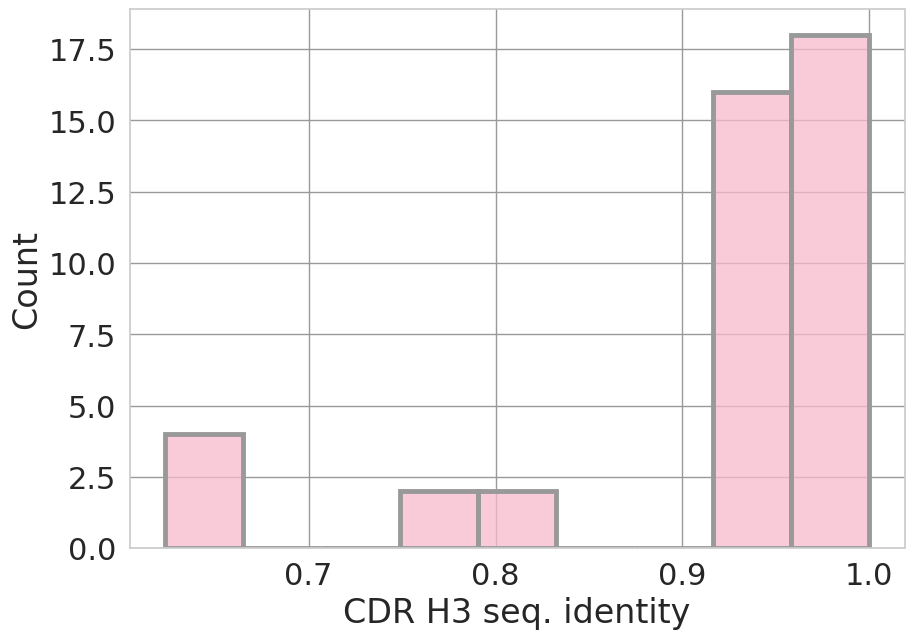

In [ ]:
# Ab CDR H3 seq ID histogram against training set
# Nb CDR H3 seq ID histogram against training set

sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
ax=sns.histplot(data=all_max_ab_b2t_h3[all_max_ab_b2t_h3['PDB_short'].isin([x for x in final_af3_benchmark[(final_af3_benchmark['Protein_type']=='antibody')].PDB_short.unique().tolist()])],x='Seq_ID_train_max',edgecolor=".6",\
# ax=sns.histplot(data=max_train_h3seqids_ab.drop_duplicates(subset=['PDB_short']),x='Seq_ID_train_max',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0])
sns.set(font_scale=2)
ax.set_xlabel('CDR H3 seq. identity')

In [14]:
ab_benchh3s = fasta_to_df('results/round_10/ab_bench_h3_seqs.fa').rename(columns={"PDB":"Bench Dir","Dir":"PDB"})
pdb1s = []
pdb2s = []
seqids = []
for i in range(ab_benchh3s.shape[0]):
    pdb1 = ab_benchh3s.iloc[i]
    for j in range(1,ab_benchh3s.shape[0]):
        pdb2 = ab_benchh3s.iloc[j]
        if pdb1.PDB == pdb2.PDB:
            pass
        else:
            seqids.append(ratio(pdb1.sequence,pdb2.sequence))
            pdb1s.append(pdb1.PDB)
            pdb2s.append(pdb2.PDB)

ab_benchh3_seqid_df = pd.DataFrame({"PDB_1":pdb1s,"PDB_2":pdb2s,"Seq_ID":seqids})
ab_benchh3_seqid_df

,PDB_1,PDB_2,Seq_ID
0,renum_8d01_0.pdb,renum_8dkf_1.pdb,0.400000
1,renum_8d01_0.pdb,renum_8eqa_0.pdb,0.322581
2,renum_8d01_0.pdb,renum_8awl_0.pdb,0.400000
3,renum_8d01_0.pdb,renum_8g1b_1.pdb,0.375000
4,renum_8d01_0.pdb,renum_7rpt_0.pdb,0.240000
...,...,...,...
3716,renum_7s0j_0.pdb,8hc3_1.pdb,0.384615
3717,renum_7s0j_0.pdb,8g3p_0.pdb,0.378378
3718,renum_7s0j_0.pdb,8c3v_1.pdb,0.363636
3719,renum_7s0j_0.pdb,8da0_0.pdb,0.444444


In [16]:
max_bench_h3seqids_ab_df = pd.DataFrame({"PDB_1":ab_benchh3_seqid_df.PDB_1.unique(),\
                                    "Seq_ID_train_max":[ab_benchh3_seqid_df[ab_benchh3_seqid_df['PDB_1']==x].Seq_ID.max() \
                                                        for x in ab_benchh3_seqid_df.PDB_1.unique().tolist()]})
max_bench_h3seqids_ab_df

,PDB_1,Seq_ID_train_max
0,renum_8d01_0.pdb,0.533333
1,renum_8dkf_1.pdb,0.529412
2,renum_8eqa_0.pdb,0.480000
3,renum_8awl_0.pdb,0.666667
4,renum_8g1b_1.pdb,0.545455
...,...,...
57,8g3p_0.pdb,0.437500
58,8c3v_1.pdb,0.500000
59,8da0_0.pdb,1.000000
60,7q6c.pdb,0.500000


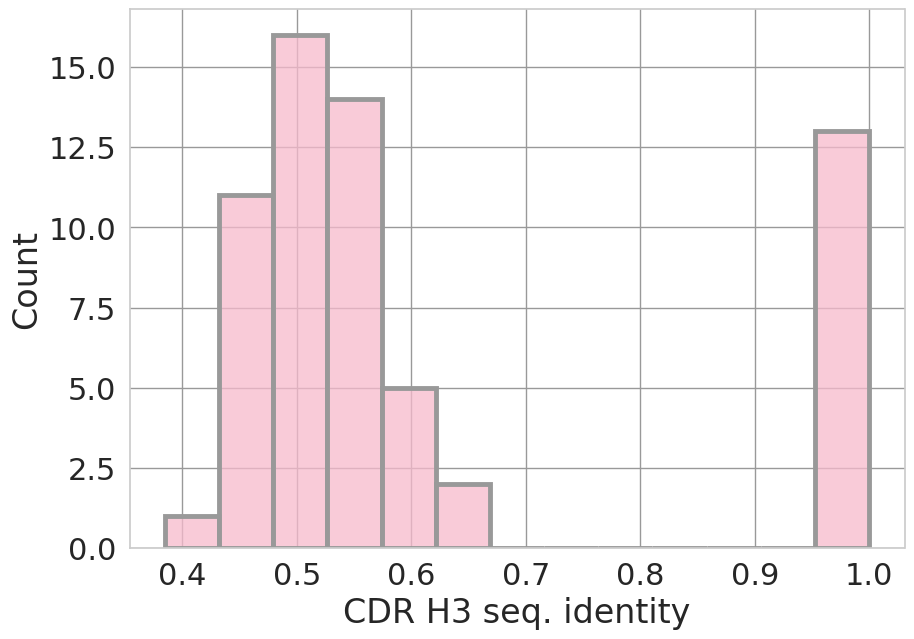

In [ ]:
# Ab CDR H3 seq ID histogram against bench set

sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
ax=sns.histplot(data=max_bench_h3seqids_ab_df,x='Seq_ID_train_max',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0])
sns.set(font_scale=2)
ax.set_xlabel('CDR H3 seq. identity')

In [ ]:
nb_benchh3s = fasta_to_df('results/round_10/nb_bench_h3_seqs.fa').rename(columns={"PDB":"Bench Dir","Dir":"PDB"})
pdb1s = []
pdb2s = []
seqids = []
for i in range(nb_benchh3s.shape[0]):
    pdb1 = nb_benchh3s.iloc[i]
    for j in range(1,nb_benchh3s.shape[0]):
        pdb2 = nb_benchh3s.iloc[j]
        if pdb1.PDB == pdb2.PDB:
            pass
        else:
            seqids.append(ratio(pdb1.sequence,pdb2.sequence))
            pdb1s.append(pdb1.PDB)
            pdb2s.append(pdb2.PDB)

nb_benchh3_seqid_df = pd.DataFrame({"PDB_1":pdb1s,"PDB_2":pdb2s,"Seq_ID":seqids})


max_bench_h3seqids_nb_df = pd.DataFrame({"PDB_1":nb_benchh3_seqid_df.PDB_1.unique(),\
                                    "Seq_ID_train_max":[nb_benchh3_seqid_df[nb_benchh3_seqid_df['PDB_1']==x].Seq_ID.max() \
                                                        for x in nb_benchh3_seqid_df.PDB_1.unique().tolist()]})
max_bench_h3seqids_nb_df

,PDB_1,Seq_ID_train_max
0,renum_7xl0_0.pdb,0.461538
1,renum_8coh_0.pdb,0.625000
2,renum_8e2n_1.pdb,0.444444
3,renum_8gz6_1.pdb,0.500000
4,renum_7r20_0.pdb,1.000000
...,...,...
64,8en3_0.pdb,0.625000
65,7zxu_0.pdb,0.562500
66,8c3l_0.pdb,1.000000
67,7q6c_0.pdb,0.551724


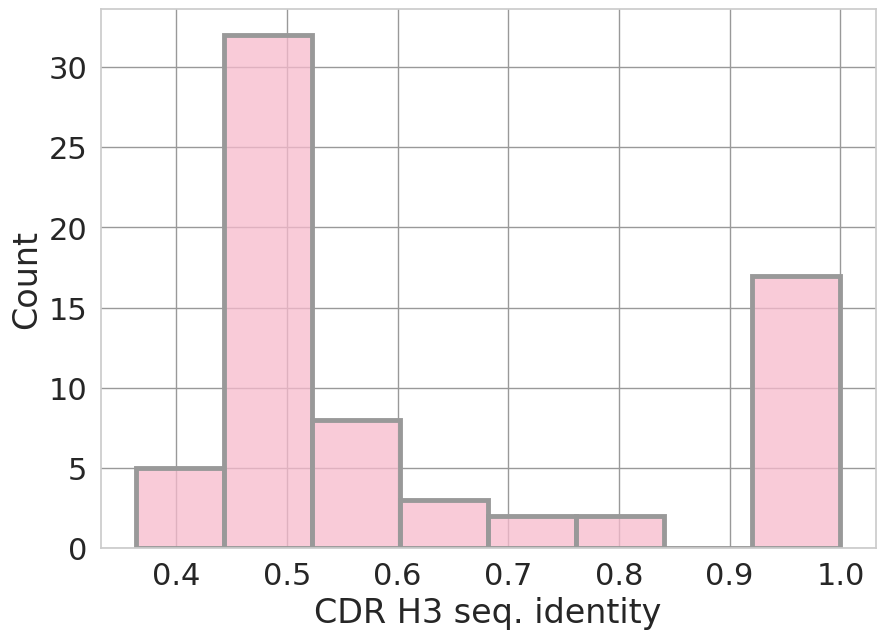

In [ ]:
# Ab CDR H3 seq ID histogram against bench set

sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
ax=sns.histplot(data=max_bench_h3seqids_nb_df,x='Seq_ID_train_max',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0])
sns.set(font_scale=2)
ax.set_xlabel('CDR H3 seq. identity')

In [ ]:
# checking hits of all bench2train queries
abs_list = final_af3_benchmark[(final_af3_benchmark['Protein_type']=='antibody')].PDB_short.unique().tolist()
ab_h3_seq_bench2train = pd.read_csv('results/round_9/ab_bench2train_h3_align.tsv',sep='\t',header=None)
ab_h3_seq_bench2train.columns = ['PDB_1','PDB_2','Seq_ID','alignment length','num_mismatches','num_gapopenings','query_domainstart','query_domainend','target_domainstart','target_domainend','E-value','Bit Score']
ab_h3_seq_bench2train=ab_h3_seq_bench2train[ab_h3_seq_bench2train['PDB_1']!=ab_h3_seq_bench2train['PDB_2']]
ab_h3_seq_bench2train['Dir_1'] = [x.split('|')[0] for x in ab_h3_seq_bench2train.PDB_1]
# ab_h3_seq_bench2train['Dir_2'] = [x.split('|')[0] for x in ab_h3_seq_bench2train.PDB_2]
ab_h3_seq_bench2train['PDB_1_Source'] = [x.split('|')[-1] for x in ab_h3_seq_bench2train.PDB_1]
ab_h3_seq_bench2train['PDB_2_Source'] = [x.split('|')[-1] for x in ab_h3_seq_bench2train.PDB_2]
ab_h3_seq_bench2train['PDB_1'] = [x.split('|')[1] for x in ab_h3_seq_bench2train.PDB_1]
ab_h3_seq_bench2train['PDB_2'] = [x.split('|')[0] for x in ab_h3_seq_bench2train.PDB_2]
ab_h3_seq_bench2train['PDB_1_short'] = ['_'.join(x.split('_')[-2:]) for x in ab_h3_seq_bench2train.PDB_1]
ab_h3_seq_bench2train['PDB_2_short'] = ['_'.join(x.split('_')[-2:]) for x in ab_h3_seq_bench2train.PDB_2]
ab_h3_seq_bench2train = ab_h3_seq_bench2train[(ab_h3_seq_bench2train['PDB_1_short'].isin(abs_list))]
ab_h3_seq_bench2train

In [61]:
max_bench2train_h3seqids_ab = pd.DataFrame({"PDB":ab_h3_seq_bench2train.PDB_1.unique(),\
                                    "Seq_ID_train_max":[ab_h3_seq_bench2train[ab_h3_seq_bench2train['PDB_1']==x].Seq_ID.max() \
                                                        for x in ab_h3_seq_bench2train.PDB_1.unique().tolist()]})
max_bench2train_h3seqids_ab['PDB_short'] = ['_'.join(x.split('_')[-2:]) for x in max_bench2train_h3seqids_ab.PDB]
max_bench2train_h3seqids_ab

,PDB,Seq_ID_train_max,PDB_short
0,7u5b_1.pdb,0.776,7u5b_1.pdb
1,renum_stitched_8e6j_0.pdb,0.989,8e6j_0.pdb
2,renum_stitched_8sdg_1.pdb,1.000,8sdg_1.pdb
3,renum_stitched_8r1d_0.pdb,1.000,8r1d_0.pdb
4,renum_stitched_7yru_0.pdb,0.997,7yru_0.pdb
5,renum_stitched_8dad_0.pdb,0.993,8dad_0.pdb
6,8d9z_0.pdb,0.923,8d9z_0.pdb
7,renum_stitched_7t7b_0.pdb,0.921,7t7b_0.pdb
8,8cii_1.pdb,0.942,8cii_1.pdb
9,renum_stitched_7x6a_0.pdb,0.997,7x6a_0.pdb


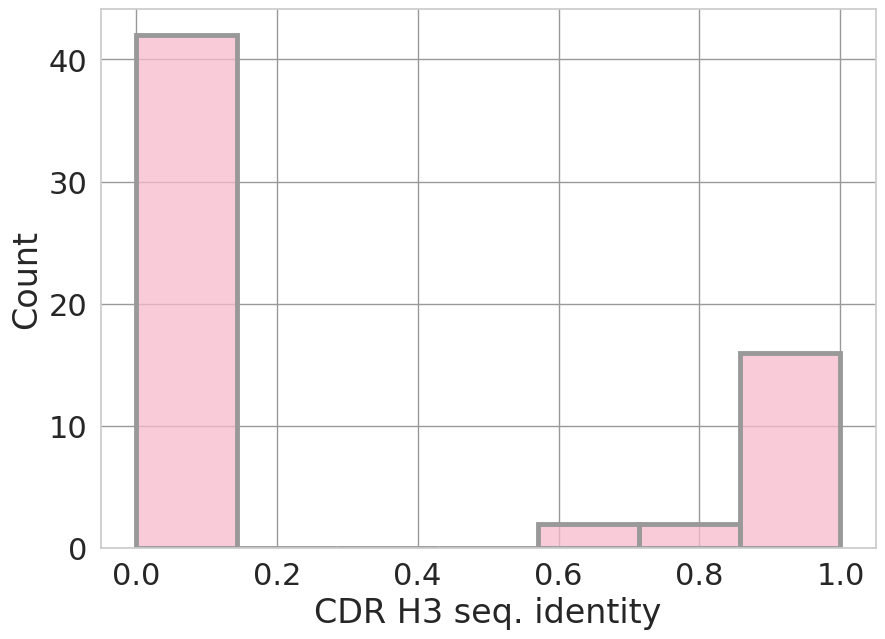

In [ ]:
# Nb CDR H3 seq ID histogram against bench set

sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
ax=sns.histplot(data=pd.concat([max_bench2train_h3seqids_ab,pd.DataFrame({'PDB':[x for x in abs_list if x not in max_bench2train_h3seqids_ab.PDB_short.tolist()],'Seq_ID_train_max':[0]*(len(abs_list)-max_bench2train_h3seqids_ab.shape[0]),\
                                                                    'PDB_short':[x for x in abs_list if x not in max_bench2train_h3seqids_ab.PDB_short.tolist()]})]),x='Seq_ID_train_max',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0])
sns.set(font_scale=2)
ax.set_xlabel('CDR H3 seq. identity')

In [68]:
# Nb bench2bench h3 seq ID
nbs_list = final_af3_benchmark[(final_af3_benchmark['Protein_type']=='nanobody')].PDB_short.unique().tolist()
nb_h3_seq_bench2bench = pd.read_csv('results/round_9/nb_bench2bench_h3_align.tsv',sep='\t',header=None)
nb_h3_seq_bench2bench.columns = ['PDB_1','PDB_2','Seq_ID','alignment length','num_mismatches','num_gapopenings','query_domainstart','query_domainend','target_domainstart','target_domainend','E-value','Bit Score']
nb_h3_seq_bench2bench=nb_h3_seq_bench2bench[nb_h3_seq_bench2bench['PDB_1']!=nb_h3_seq_bench2bench['PDB_2']]
nb_h3_seq_bench2bench['Dir_1'] = [x.split('|')[0] for x in nb_h3_seq_bench2bench.PDB_1]
nb_h3_seq_bench2bench['Dir_2'] = [x.split('|')[0] for x in nb_h3_seq_bench2bench.PDB_2]
nb_h3_seq_bench2bench['PDB_1_Source'] = [x.split('|')[-1] for x in nb_h3_seq_bench2bench.PDB_1]
nb_h3_seq_bench2bench['PDB_2_Source'] = [x.split('|')[-1] for x in nb_h3_seq_bench2bench.PDB_2]
nb_h3_seq_bench2bench['PDB_1'] = [x.split('|')[1] for x in nb_h3_seq_bench2bench.PDB_1]
nb_h3_seq_bench2bench['PDB_2'] = [x.split('|')[1] for x in nb_h3_seq_bench2bench.PDB_2]
nb_h3_seq_bench2bench['PDB_1_short'] = ['_'.join(x.split('_')[-2:]) for x in nb_h3_seq_bench2bench.PDB_1]
nb_h3_seq_bench2bench['PDB_2_short'] = ['_'.join(x.split('_')[-2:]) for x in nb_h3_seq_bench2bench.PDB_2]
nb_h3_seq_bench2bench = nb_h3_seq_bench2bench[(nb_h3_seq_bench2bench['PDB_1_short'].isin(nbs_list))&(nb_h3_seq_bench2bench['PDB_1_short'].isin(nbs_list))]
nb_h3_seq_bench2bench


,PDB_1,PDB_2,Seq_ID,alignment length,num_mismatches,num_gapopenings,query_domainstart,query_domainend,target_domainstart,target_domainend,E-value,Bit Score,Dir_1,Dir_2,PDB_1_Source,PDB_2_Source,PDB_1_short,PDB_2_short
66,renum_stitched_8hxq_0.pdb,renum_stitched_8hxq_1.pdb,1.000,10,0,0,1,10,1,10,0.000218,24,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark,8hxq_0.pdb,8hxq_1.pdb
205,8qf5_0.pdb,8qf5_1.pdb,1.000,10,0,0,1,10,1,10,0.000012,28,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark,8qf5_0.pdb,8qf5_1.pdb
206,8qf5_0.pdb,renum_7r20_0.pdb,1.000,10,0,0,1,10,1,10,0.000012,28,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark,8qf5_0.pdb,7r20_0.pdb
366,8cy6_0.pdb,8cy6_1.pdb,1.000,12,0,0,1,12,1,12,0.000006,29,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark,8cy6_0.pdb,8cy6_1.pdb
367,8cy6_0.pdb,8cy6_2.pdb,1.000,12,0,0,1,12,1,12,0.000006,29,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark,8cy6_0.pdb,8cy6_2.pdb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5666,8cy9_0.pdb,8cy9_2.pdb,1.000,12,0,0,1,12,1,12,0.000014,28,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark,8cy9_0.pdb,8cy9_2.pdb
5668,8cy9_0.pdb,8cy9_1.pdb,1.000,12,0,0,1,12,1,12,0.000014,28,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark,8cy9_0.pdb,8cy9_1.pdb
5669,8cy9_0.pdb,8cxq_2.pdb,0.866,12,1,0,1,12,1,12,0.000255,24,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark,8cy9_0.pdb,8cxq_2.pdb
5670,8cy9_0.pdb,8cxq_0.pdb,0.866,12,1,0,1,12,1,12,0.000255,24,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark,8cy9_0.pdb,8cxq_0.pdb


In [69]:
max_bench_h3seqids_nb = pd.DataFrame({"PDB":nb_h3_seq_bench2bench.PDB_1.unique(),\
                                    "Seq_ID_train_max":[nb_h3_seq_bench2bench[nb_h3_seq_bench2bench['PDB_1']==x].Seq_ID.max() \
                                                        for x in nb_h3_seq_bench2bench.PDB_1.unique().tolist()]})
max_bench_h3seqids_nb['PDB_short'] = ['_'.join(x.split('_')[-2:]) for x in max_bench_h3seqids_nb.PDB]
max_bench_h3seqids_nb

,PDB,Seq_ID_train_max,PDB_short
0,renum_stitched_8hxq_0.pdb,1.000,8hxq_0.pdb
1,8qf5_0.pdb,1.000,8qf5_0.pdb
2,8cy6_0.pdb,1.000,8cy6_0.pdb
3,8dqu_0.pdb,1.000,8dqu_0.pdb
4,8cy7_2.pdb,1.000,8cy7_2.pdb
5,8cxq_0.pdb,1.000,8cxq_0.pdb
6,renum_8e2n_1.pdb,0.989,8e2n_1.pdb
7,7z1x_1.pdb,1.000,7z1x_1.pdb
8,7x7e_0.pdb,1.000,7x7e_0.pdb
9,8ce4_0.pdb,1.000,8ce4_0.pdb


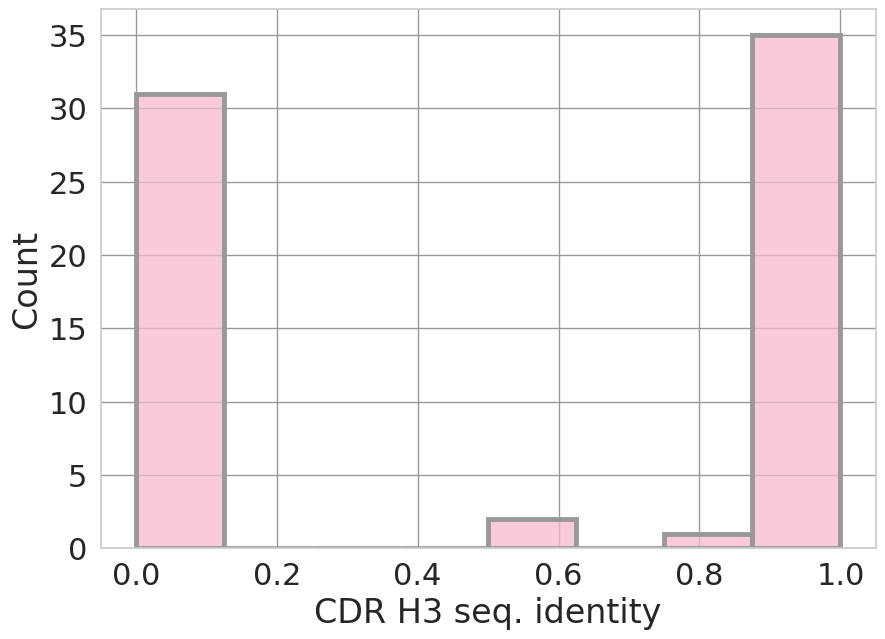

In [ ]:
# Nb CDR H3 seq ID histogram against bench set

sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
ax=sns.histplot(data=pd.concat([max_bench_h3seqids_nb,pd.DataFrame({'PDB':[x for x in nbs_list if x not in max_bench_h3seqids_nb.PDB_short.tolist()],'Seq_ID_train_max':[0]*(len(nbs_list)-max_bench_h3seqids_nb.shape[0]),\
                                                                    'PDB_short':[x for x in nbs_list if x not in max_bench_h3seqids_nb.PDB_short.tolist()]})]),x='Seq_ID_train_max',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0])
sns.set(font_scale=2)
ax.set_xlabel('CDR H3 seq. identity')

In [ ]:
# checking hits of all bench2train queries
nbs_list = final_af3_benchmark[(final_af3_benchmark['Protein_type']=='nanobody')].PDB_short.unique().tolist()
nb_h3_seq_bench2train = pd.read_csv('results/round_9/nb_bench2train_h3_align.tsv',sep='\t',header=None)
nb_h3_seq_bench2train.columns = ['PDB_1','PDB_2','Seq_ID','alignment length','num_mismatches','num_gapopenings','query_domainstart','query_domainend','target_domainstart','target_domainend','E-value','Bit Score']
nb_h3_seq_bench2train=nb_h3_seq_bench2train[nb_h3_seq_bench2train['PDB_1']!=nb_h3_seq_bench2train['PDB_2']]
nb_h3_seq_bench2train['Dir_1'] = [x.split('|')[0] for x in nb_h3_seq_bench2train.PDB_1]
# ab_h3_seq_bench2train['Dir_2'] = [x.split('|')[0] for x in ab_h3_seq_bench2train.PDB_2]
nb_h3_seq_bench2train['PDB_1_Source'] = [x.split('|')[-1] for x in nb_h3_seq_bench2train.PDB_1]
nb_h3_seq_bench2train['PDB_2_Source'] = [x.split('|')[-1] for x in nb_h3_seq_bench2train.PDB_2]
nb_h3_seq_bench2train['PDB_1'] = [x.split('|')[1] for x in nb_h3_seq_bench2train.PDB_1]
nb_h3_seq_bench2train['PDB_2'] = [x.split('|')[0] for x in nb_h3_seq_bench2train.PDB_2]
nb_h3_seq_bench2train['PDB_1_short'] = ['_'.join(x.split('_')[-2:]) for x in nb_h3_seq_bench2train.PDB_1]
nb_h3_seq_bench2train['PDB_2_short'] = ['_'.join(x.split('_')[-2:]) for x in nb_h3_seq_bench2train.PDB_2]
nb_h3_seq_bench2train = nb_h3_seq_bench2train[(nb_h3_seq_bench2train['PDB_1_short'].isin(nbs_list))]
nb_h3_seq_bench2train

,PDB_1,PDB_2,Seq_ID,alignment length,num_mismatches,num_gapopenings,query_domainstart,query_domainend,target_domainstart,target_domainend,E-value,Bit Score,Dir_1,PDB_1_Source,PDB_2_Source,PDB_1_short,PDB_2_short
40,7x2j_0.pdb,6h15_0.pdb,0.466,17,7,0,2,18,2,16,0.23770,18,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7x2j_0.pdb,6h15_0.pdb
41,7x2j_0.pdb,6h15_1.pdb,0.466,17,7,0,2,18,2,16,0.23770,18,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7x2j_0.pdb,6h15_1.pdb
633,7zmm_0.pdb,6xvi_1.pdb,0.761,12,3,0,4,15,5,16,0.01205,21,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7zmm_0.pdb,6xvi_1.pdb
634,7zmm_0.pdb,6qd6_3.pdb,0.761,12,3,0,4,15,5,16,0.01205,21,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7zmm_0.pdb,6qd6_3.pdb
635,7zmm_0.pdb,6xvi_2.pdb,0.761,12,3,0,4,15,5,16,0.01205,21,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7zmm_0.pdb,6xvi_2.pdb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6916,7zw1_0.pdb,4hem_1.pdb,0.739,10,2,0,8,17,5,14,0.21780,18,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7zw1_0.pdb,4hem_1.pdb
6917,7zw1_0.pdb,4hem_2.pdb,0.739,10,2,0,8,17,5,14,0.21780,18,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7zw1_0.pdb,4hem_2.pdb
7254,7zxu_0.pdb,5hvf_0.pdb,0.759,11,2,0,5,15,2,12,0.03694,20,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7zxu_0.pdb,5hvf_0.pdb
7255,7zxu_0.pdb,5hvh_1.pdb,0.759,11,2,0,5,15,2,12,0.03694,20,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Train,7zxu_0.pdb,5hvh_1.pdb


In [74]:
max_bench2train_h3seqids_nb = pd.DataFrame({"PDB":nb_h3_seq_bench2train.PDB_1.unique(),\
                                    "Seq_ID_train_max":[nb_h3_seq_bench2train[nb_h3_seq_bench2train['PDB_1']==x].Seq_ID.max() \
                                                        for x in nb_h3_seq_bench2train.PDB_1.unique().tolist()]})
max_bench2train_h3seqids_nb['PDB_short'] = ['_'.join(x.split('_')[-2:]) for x in max_bench2train_h3seqids_nb.PDB]
max_bench2train_h3seqids_nb

,PDB,Seq_ID_train_max,PDB_short
0,7x2j_0.pdb,0.466,7x2j_0.pdb
1,7zmm_0.pdb,0.761,7zmm_0.pdb
2,8cyb_0.pdb,0.821,8cyb_0.pdb
3,8cxn_2.pdb,0.921,8cxn_2.pdb
4,7zk1_1.pdb,0.761,7zk1_1.pdb
5,7z1c_0.pdb,0.801,7z1c_0.pdb
6,7sp8_0.pdb,0.661,7sp8_0.pdb
7,7tpr_0.pdb,0.666,7tpr_0.pdb
8,8cxn_1.pdb,0.921,8cxn_1.pdb
9,8emz_0.pdb,0.794,8emz_0.pdb


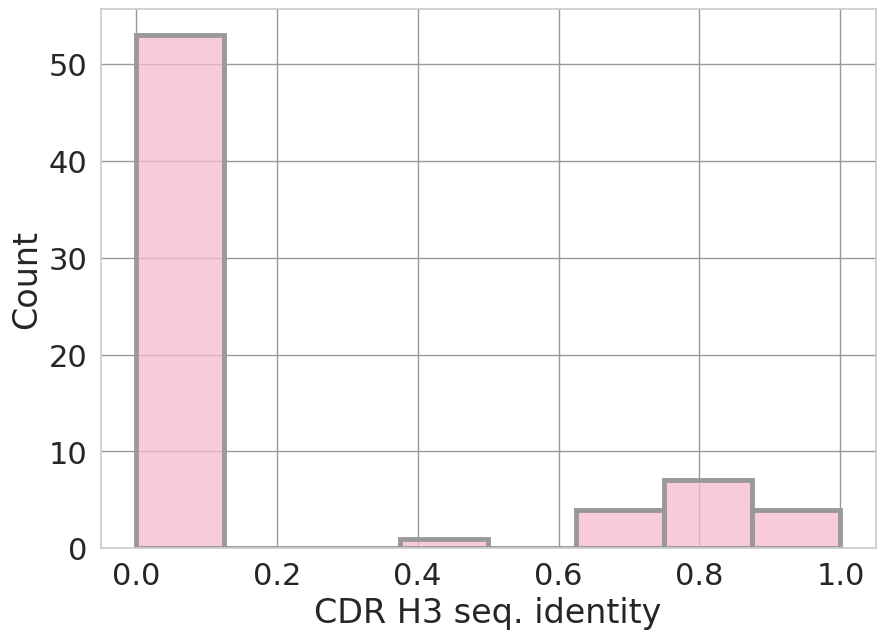

In [ ]:
# Nb CDR H3 seq ID histogram against bench set

sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
ax=sns.histplot(data=pd.concat([max_bench2train_h3seqids_nb,pd.DataFrame({'PDB':[x for x in nbs_list if x not in max_bench2train_h3seqids_nb.PDB_short.tolist()],'Seq_ID_train_max':[0]*(len(nbs_list)-max_bench2train_h3seqids_nb.shape[0]),\
                                                                    'PDB_short':[x for x in nbs_list if x not in max_bench2train_h3seqids_nb.PDB_short.tolist()]})]),x='Seq_ID_train_max',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0])
sns.set(font_scale=2)
ax.set_xlabel('CDR H3 seq. identity')

In [67]:
# Ab bench2bench h3 seq ID
# filtering determined nbs using train2bench seqID
ab_h3_seq_bench2bench = pd.read_csv('results/round_8/ab_bench2bench_h3_align.tsv',sep='\t',header=None)
ab_h3_seq_bench2bench.columns = ['PDB_1','PDB_2','Seq_ID','alignment length','num_mismatches','num_gapopenings','query_domainstart','query_domainend','target_domainstart','target_domainend','E-value','Bit Score']
ab_h3_seq_bench2bench=ab_h3_seq_bench2bench[ab_h3_seq_bench2bench['PDB_1']!=ab_h3_seq_bench2bench['PDB_2']]
ab_h3_seq_bench2bench['Dir_1'] = [x.split('|')[0] for x in ab_h3_seq_bench2bench.PDB_1]
ab_h3_seq_bench2bench['PDB_1_Source'] = [x.split('|')[-1] for x in ab_h3_seq_bench2bench.PDB_1]
ab_h3_seq_bench2bench['PDB_2_Source'] = [x.split('|')[-1] for x in ab_h3_seq_bench2bench.PDB_2]
ab_h3_seq_bench2bench['PDB_1'] = [x.split('|')[1] for x in ab_h3_seq_bench2bench.PDB_1]
ab_h3_seq_bench2bench['PDB_2'] = [x.split('|')[0] for x in ab_h3_seq_bench2bench.PDB_2]
ab_h3_seq_bench2bench


,PDB_1,PDB_2,Seq_ID,alignment length,num_mismatches,num_gapopenings,query_domainstart,query_domainend,target_domainstart,target_domainend,E-value,Bit Score,Dir_1,PDB_1_Source,PDB_2_Source
0,renum_stitched_7ru5_0.pdb,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,1.000,16,0,0,1,16,1,16,8.329000e-11,44,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark
2,renum_stitched_7ru5_0.pdb,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,1.000,16,0,0,1,16,1,16,8.329000e-11,44,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark
3,renum_stitched_7ru5_0.pdb,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,0.821,12,2,0,4,15,2,13,1.911000e-03,23,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark
5,renum_7myt_1.pdb,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,1.000,18,0,0,1,18,1,18,1.787000e-10,43,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark
6,renum_stitched_7um3_1.pdb,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,1.000,12,0,0,1,12,1,12,4.842000e-07,33,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10561,7uja_0.pdb,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,0.962,9,0,0,6,14,4,12,1.110000e-02,21,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark
10562,7uja_0.pdb,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,1.000,8,0,0,7,14,11,18,1.110000e-02,21,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark
10563,7uja_0.pdb,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,1.000,8,0,0,7,14,11,18,1.110000e-02,21,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark
10564,7uja_0.pdb,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,0.660,11,3,0,3,13,3,13,1.407000e-01,18,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,Benchmark,Benchmark


In [68]:
max_bench_h3seqids_ab = pd.DataFrame({"PDB":ab_h3_seq_bench2bench.PDB_1.unique(),\
                                    "Seq_ID_train_max":[ab_h3_seq_bench2bench[ab_h3_seq_bench2bench['PDB_1']==x].Seq_ID.max() \
                                                        for x in ab_h3_seq_bench2bench.PDB_1.unique().tolist()]})
max_bench_h3seqids_ab['PDB_short'] = ['_'.join(x.split('_')[-2:]) for x in max_bench_h3seqids_ab.PDB]
max_bench_h3seqids_ab

,PDB,Seq_ID_train_max,PDB_short
0,renum_stitched_7ru5_0.pdb,1.000,7ru5_0.pdb
1,renum_7myt_1.pdb,1.000,7myt_1.pdb
2,renum_stitched_7um3_1.pdb,1.000,7um3_1.pdb
3,renum_stitched_7xdb_1.pdb,1.000,7xdb_1.pdb
4,fv_unbound_renum_stitched_8dmh_2.pdb,1.000,8dmh_2.pdb
...,...,...,...
844,renum_stitched_renum_stitched_8gas_1.pdb,1.000,8gas_1.pdb
845,renum_stitched_8jen_1.pdb,1.000,8jen_1.pdb
846,renum_stitched_7wtk_2.pdb,1.000,7wtk_2.pdb
847,7uja_0.pdb,1.000,7uja_0.pdb


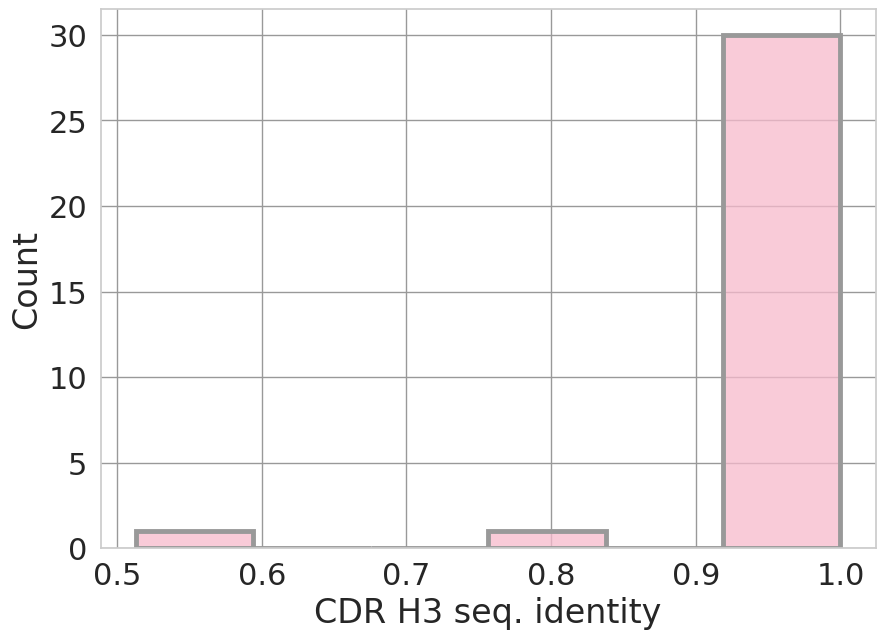

In [ ]:
# Ab CDR H3 seq ID histogram against bench set

sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(10,7))
ax=sns.histplot(data=max_bench_h3seqids_ab[max_bench_h3seqids_ab['PDB_short'].isin([x for x in final_af3_benchmark[(final_af3_benchmark['Protein_type']=='antibody')].PDB_short.unique().tolist()])],x='Seq_ID_train_max',edgecolor=".6",\
                    lw=3.5,color=pastel_palette[0])
sns.set(font_scale=2)
ax.set_xlabel('CDR H3 seq. identity')

## Panel 1: DockQ

/tmp/ipykernel_3683213/1864522495.py:7: UserWarning: The palette list has more values (5) than needed (3), which may not be intended.
  ax =sns.barplot(data=melted_newdockqs_summary_cumulative[(melted_newdockqs_summary_cumulative['DockQ Classification']!='Incorrect')],\
/tmp/ipykernel_3683213/1864522495.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xticklabels=['AF2.3-M \nAbs \nN=49','AF3-Server \nAbs \nN=49','AF2.3-M \nNbs \nN=60','AF3-Server \nNbs \nN=60'])


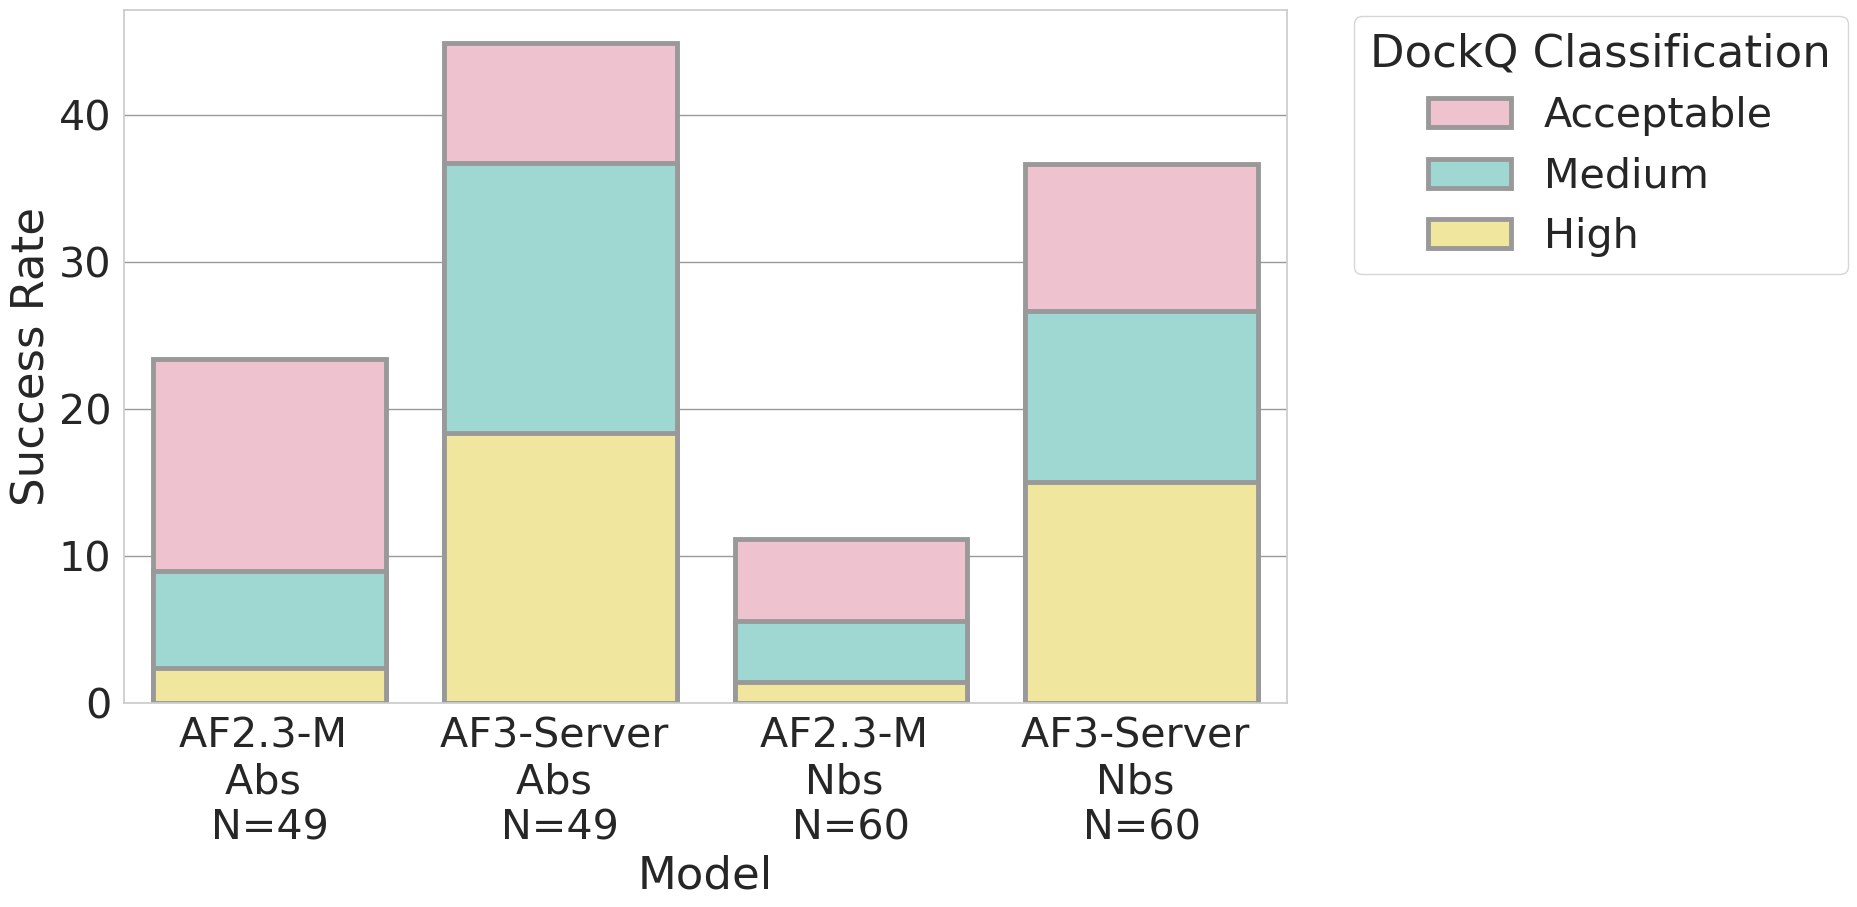

In [ ]:
plt.figure(figsize=(15,9))

sns.set_style("whitegrid",{"grid.color":"0.6"})
# custom_params = {"axes.spines.right": False, "axes.spines.top": False}
# sns.set_theme(style="ticks", rc=custom_params,font_scale=2)
# melted_newdockqs_summary_cumulative=melted_newdockqs_summary_cumulative.replace({"Model":{"AF3":"AF3-Server"}})
ax =sns.barplot(data=melted_newdockqs_summary_cumulative[(melted_newdockqs_summary_cumulative['DockQ Classification']!='Incorrect')],\
                x='Model',y='Success Rate',hue='DockQ Classification',\
                    # ,facecolor=(0, 0, 0, 0),\
                    # linewidth=5,
                #    edgecolor=palette,\
                    edgecolor=".6",\
                    lw=3.5,
                    order=['AF2.3-Multimer Abs','AF3-Server Abs','AF2.3-Multimer Nbs','AF3-Server Nbs']\
                    ,dodge=False,palette=pastel_palette[:-1])
# ax.set_title("Ab Docking Success Rate Comparison Between Models")
sns.move_legend(ax, "upper right", bbox_to_anchor=(1.5, 1.021))
sns.set(font_scale=2.7)
ax.set(xticklabels=['AF2.3-M \nAbs \nN=49','AF3-Server \nAbs \nN=49','AF2.3-M \nNbs \nN=60','AF3-Server \nNbs \nN=60']) 

In [133]:
new_dockqs = pd.read_csv("Revised_DockQ_DB5.csv")
new_dockqs = new_dockqs[new_dockqs['Antibody']==1]
af2_rank_incorrect = []
af2_rank_acceptable = []
af2_rank_medium = []
af2_rank_high = []

afred_rank_incorrect = []
afred_rank_acceptable = []
afred_rank_medium = []
afred_rank_high = []

for i in trange(new_dockqs.shape[0]):
    af2_rank = new_dockqs.iloc[i].AF2_CAPRI_rank
    afred_rank = new_dockqs.iloc[i].CAPRI_rank
    if af2_rank == 0:
        af2_rank_incorrect.append(1)
    elif af2_rank == 1:
        af2_rank_acceptable.append(1)
    elif af2_rank == 2:
        af2_rank_medium.append(1)
    elif af2_rank == 3:
        af2_rank_high.append(1)

    if afred_rank == 0:
        afred_rank_incorrect.append(1)
    elif afred_rank == 1:
        afred_rank_acceptable.append(1)
    elif afred_rank == 2:
        afred_rank_medium.append(1)
    elif afred_rank == 3:
        afred_rank_high.append(1)

newdockqs_summary = pd.DataFrame({"Model":['AlphaFold-M','AlphaRED'],"Incorrect":[round(len(af2_rank_incorrect)/67,4)*100,round(len(afred_rank_incorrect)/67,4)*100],\
              "Acceptable":[round(len(af2_rank_acceptable)/67,4)*100,round(len(afred_rank_acceptable)/67,4)*100],"Medium":[round(len(af2_rank_medium)/67,4)*100,round(len(afred_rank_medium)/67,4)*100],\
                "High":[round(len(af2_rank_high)/67,4)*100,round(len(afred_rank_high)/67,4)*100]})
AF3_ab_results = pd.DataFrame({"Model":['AF3-Server Abs'],"Incorrect":[49.25],"Acceptable":[4.48],"Medium":[19.40],"High":[26.87]})
# AF3_ab_results = pd.DataFrame({"Model":['AF3-Server Abs'],"Incorrect":[61.86],"Acceptable":[11.02],"Medium":[16.10],"High":[11.02]})
# AF3_nb_results = pd.DataFrame({"Model":['AF3-Server Nbs'],"Incorrect":[68.57],"Acceptable":[8.57],"Medium":[11.43],"High":[11.43]})
newdockqs_summary = pd.concat([newdockqs_summary,AF3_ab_results],axis=0)
melted_dockingcomparison = pd.melt(newdockqs_summary,id_vars=['Model'],value_vars=['Incorrect','Acceptable','Medium','High'],var_name="DockQ Classification",value_name='Success Rate')
newdockqs_summary_cumulative = newdockqs_summary
newdockqs_summary_cumulative
newdockqs_summary_cumulative.loc[:,'Medium'] = [11.94 , 17.91 , 46.27]
newdockqs_summary_cumulative.loc[:,'Acceptable'] = [20.9 , 43.28,50.75 ]
melted_newdockqs_summary_cumulative = pd.melt(newdockqs_summary_cumulative,id_vars=['Model'],value_vars=['Incorrect','Acceptable','Medium','High'],var_name="DockQ Classification",value_name='Success Rate')
melted_newdockqs_summary_cumulative


100%|██████████| 67/67 [00:00<00:00, 11405.43it/s]


,Model,DockQ Classification,Success Rate
0,AlphaFold-M,Incorrect,79.10
1,AlphaRED,Incorrect,56.72
2,AF3-Server Abs,Incorrect,49.25
3,AlphaFold-M,Acceptable,20.90
4,AlphaRED,Acceptable,43.28
5,AF3-Server Abs,Acceptable,50.75
6,AlphaFold-M,Medium,11.94
7,AlphaRED,Medium,17.91
8,AF3-Server Abs,Medium,46.27
9,AlphaFold-M,High,0.00


/tmp/ipykernel_3026123/3508633195.py:7: UserWarning: The palette list has more values (5) than needed (3), which may not be intended.
  ax =sns.barplot(data=melted_newdockqs_summary_cumulative[(melted_newdockqs_summary_cumulative['DockQ Classification']!='Incorrect')],\
/tmp/ipykernel_3026123/3508633195.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xticklabels=['AlphaFold-M \n Abs \n N=67','AlphaRED \n Abs \n N=67','AF3-Server \n Abs \n N=67'])


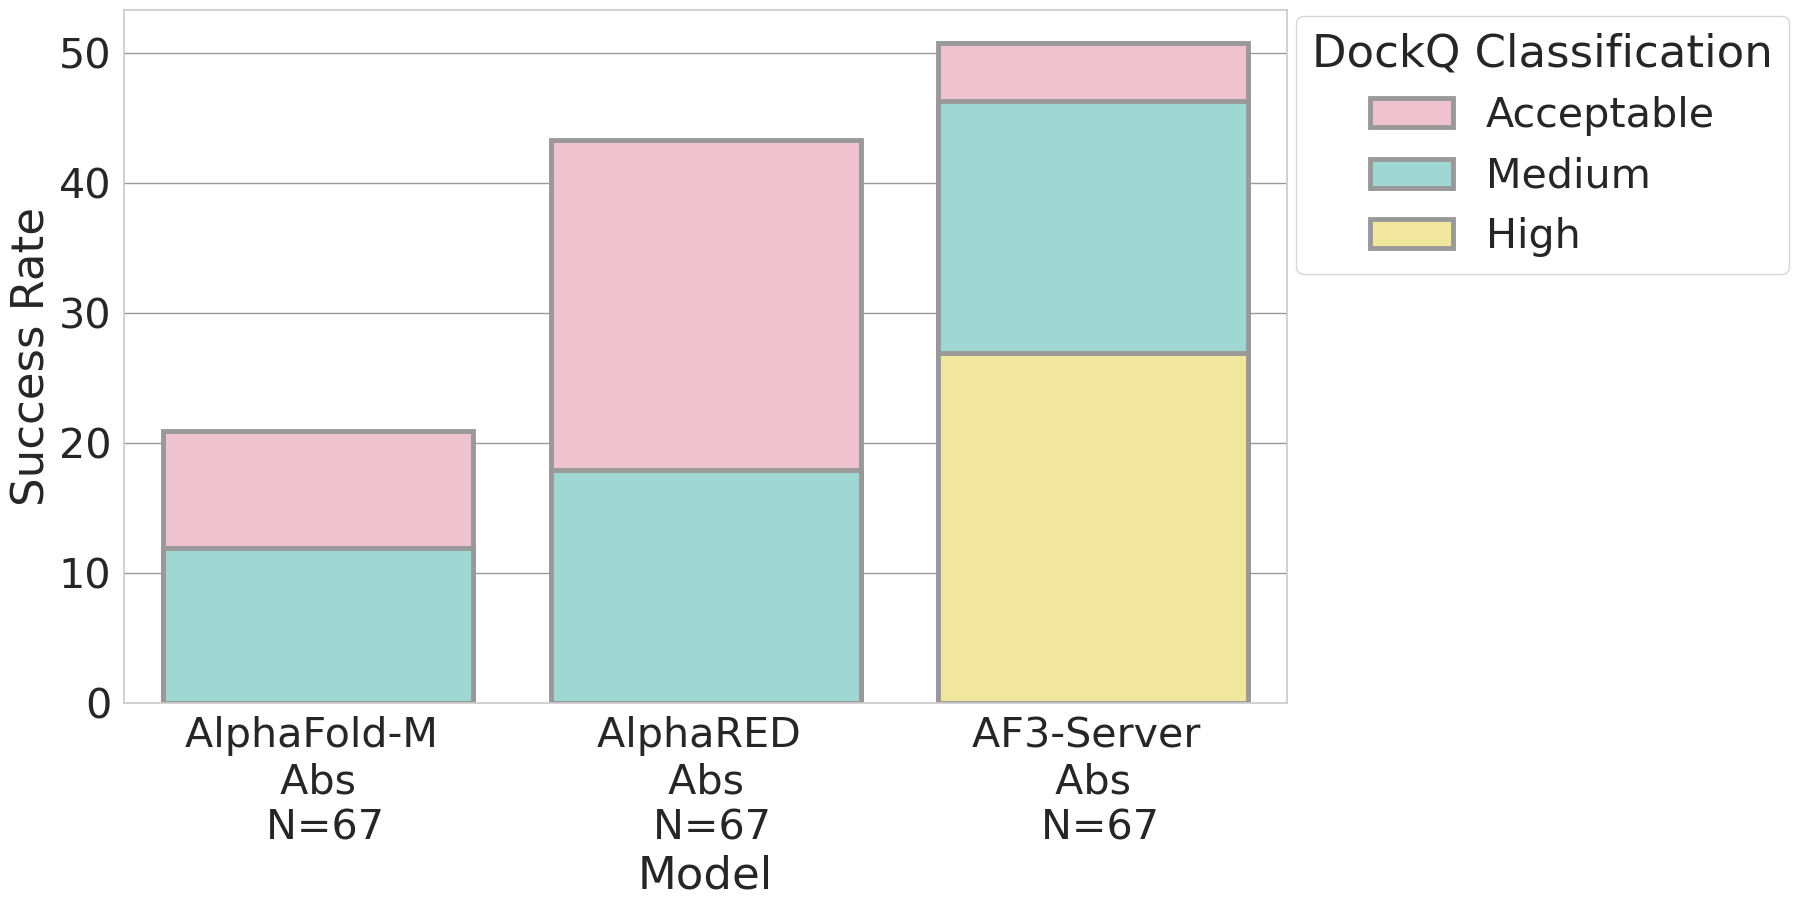

In [134]:
plt.figure(figsize=(15,9))

sns.set_style("whitegrid",{"grid.color":"0.6"})
# custom_params = {"axes.spines.right": False, "axes.spines.top": False}
# sns.set_theme(style="ticks", rc=custom_params,font_scale=2)
# melted_newdockqs_summary_cumulative=melted_newdockqs_summary_cumulative.replace({"Model":{"AF3":"AF3-Server"}})
ax =sns.barplot(data=melted_newdockqs_summary_cumulative[(melted_newdockqs_summary_cumulative['DockQ Classification']!='Incorrect')],\
                x='Model',y='Success Rate',hue='DockQ Classification',\
                    # ,facecolor=(0, 0, 0, 0),\
                    # linewidth=5,
                #    edgecolor=palette,\
                    edgecolor=".6",\
                    lw=3.5,
                    order=['AlphaFold-M','AlphaRED','AF3-Server Abs']\
                    ,dodge=False,palette=pastel_palette[:-1])
# ax.set_title("Ab Docking Success Rate Comparison Between Models")
sns.move_legend(ax, "upper right", bbox_to_anchor=(1.45, 1.021))
sns.set(font_scale=2.7)
ax.set(xticklabels=['AlphaFold-M \n Abs \n N=67','AlphaRED \n Abs \n N=67','AF3-Server \n Abs \n N=67']) 
plt.savefig("results/round_8/plots/stacked_top_rankedproper_DockQ_DB5bench.svg",format='svg',dpi=500,transparent=True,bbox_inches='tight')

## Panel 2: P(X)

In [13]:
def ph3(data_df,lowhigh,ptype,h3_thres):
    if lowhigh == 'low':
        p_h3 = data_df[(data_df['Protein_type']==ptype) & (data_df['h3_rms']<=h3_thres)].shape[0]/data_df[data_df['Protein_type']==ptype].shape[0]
    else:
        p_h3 = data_df[(data_df['Protein_type']==ptype) & (data_df['h3_rms']>h3_thres)].shape[0]/data_df[data_df['Protein_type']==ptype].shape[0]
    return p_h3

def pdock(data_df,dockclasses,ptype):
    p_dock = data_df[(data_df['Protein_type']==ptype) & data_df['DockQ_Classification'].isin(dockclasses)].shape[0]/data_df[data_df['Protein_type']==ptype].shape[0]
    return p_dock

def pdock_withthresh(data_df,dockthres,ptype):
    p_dock = data_df[(data_df['Protein_type']==ptype) & (data_df['DockQ']>=dockthres)].shape[0]/data_df[data_df['Protein_type']==ptype].shape[0]
    return p_dock

def p_jointh3dock(data_df,lowhigh,h3_thres,dockclasses,ptype):
    if lowhigh == 'low':
        p_joint = data_df[(data_df['Protein_type']==ptype) & (data_df['h3_rms']<=h3_thres) & (data_df['DockQ_Classification'].isin(dockclasses))].shape[0]/ data_df[data_df['Protein_type']==ptype].shape[0]
    else:
        p_joint = data_df[(data_df['Protein_type']==ptype) & (data_df['h3_rms']>h3_thres) & (data_df['DockQ_Classification'].isin(dockclasses))].shape[0]/ data_df[data_df['Protein_type']==ptype].shape[0]
    return p_joint


def p_jointh3dock_thres(data_df,lowhigh,h3_thres,dockthres,ptype):
    if lowhigh == 'low':
        p_joint = data_df[(data_df['Protein_type']==ptype) & (data_df['h3_rms']<=h3_thres) & (data_df['DockQ']>=dockthres)].shape[0]/ data_df[data_df['Protein_type']==ptype].shape[0]
    else:
        p_joint = data_df[(data_df['Protein_type']==ptype) & (data_df['h3_rms']>h3_thres) & (data_df['DockQ']>=dockthres)].shape[0]/ data_df[data_df['Protein_type']==ptype].shape[0]
    return p_joint

def pcond(data_df,lowhigh,h3_thres,dockclasses,ptype):
    p_joint = p_jointh3dock(data_df,lowhigh,h3_thres,dockclasses,ptype)
    p_h3 = ph3(data_df,lowhigh,ptype,h3_thres)
    p_dock = pdock(data_df,dockclasses,ptype)
    p_H_D = p_joint/p_dock
    p_D_H = p_joint/p_h3
    return p_H_D, p_D_H

def pcond_thres(data_df,lowhigh,h3_thres,dockthres,ptype):
    p_joint = p_jointh3dock_thres(data_df,lowhigh,h3_thres,dockthres,ptype)
    # print(f'p_joint: {p_joint}')
    p_h3 = ph3(data_df,lowhigh,ptype,h3_thres)
    p_dock = pdock_withthresh(data_df,dockthres,ptype)
    # print(f'p_dock: {p_dock}')
    p_H_D = p_joint/p_dock
    p_D_H = p_joint/p_h3
    return p_H_D, p_D_H

### Abs

/home/ftalib1/miniconda3/lib/python3.13/site-packages/seaborn/axisgrid.py:1832: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  func(x=self.x, y=self.y, **kwargs)
/home/ftalib1/miniconda3/lib/python3.13/site-packages/seaborn/axisgrid.py:1883: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  func(x=self.x, ax=self.ax_marg_x, **kwargs)
/home/ftalib1/miniconda3/lib/python3.13/site-packages/seaborn/axisgrid.py:1889: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  func(y=self.y, ax=self.ax_marg_y, **kwargs)


<Figure size 2000x2000 with 0 Axes>

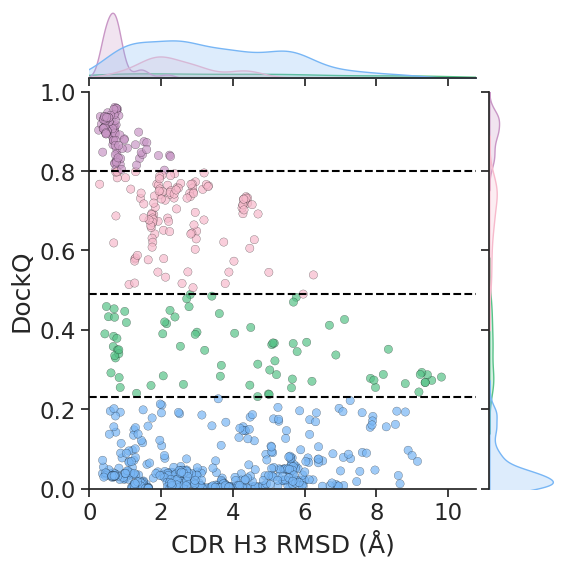

In [20]:
plt.figure(figsize=(20,20))
# sns.set_style('whitegrid',{"grid.color":"0.6"})
data_df = final_af3_benchmark[final_af3_benchmark['Protein_type']=='antibody']
# sns.set_style('whitegrid',{"grid.color":"0.6"})
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params,font_scale=1.5)
#data_df[(data_df['Seed']==2)&(data_df['Model']==0)&(data_df['l3_rms']<3)]
# ax = sns.scatterplot(data=data_df[data_df['Protein_type']=='antibody'],x='h3_rms',y='DockQ',\
ax = sns.jointplot(data=data_df,x='h3_rms',y='DockQ',\
                     alpha=0.7,edgecolor=edgecolor,linewidth=0.2,kind='scatter',hue='DockQ_Classification', palette=extended_pastel_palette[3:],legend=False)
ax.ax_marg_x.set_xlim(0, max(data_df.h3_rms.tolist()))
ax.ax_marg_y.set_ylim(0, 1)
# ax = sns.kdeplot(data=full_benchmark_withdockq[full_benchmark_withdockq['Protein_type']=='nanobody'],x='h3_rms',y='DockQ',hue='h3_len') #,size='h3_len')
# ax.set_title("Correlation of DockQ to Antibody H3 Accuracy")
# plt.legend(loc='upper right')
sns.set(font_scale=1.0)
# ax.axvline(x=1,ls='--',color='black')
plt.axhline(y=0.23,ls='--',color='black')
plt.axhline(y=0.49,ls='--',color='black')
plt.axhline(y=0.80,ls='--',color='black')
plt.xlabel('CDR H3 RMSD (Å)')
# sns.move_legend(ax, "upper right", bbox_to_anchor=(1.6, 1.05))
# sns.lmplot(data=full_benchmark_withdockq[full_benchmark_withdockq['Protein_type']=='nanobody'],x='h3_rms',y='DockQ') #.set_title("Correlation of DockQ to H3 Accuracy")
plt.savefig("results/round_8/plots/DockQ_v_H3RMSD_Abs_marginals.svg",format='svg',dpi=700,transparent=True,bbox_inches='tight')

In [21]:
alldockclasses = ['High','Medium','Acceptable']
inc_class = ['Incorrect']
inc_dockclass = ['Incorrect']
h3_thresholds = np.array(list(range(10,101)))/10 #[1,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0]

per_thresh_pHDs = []
per_thresh_pDHs = []
DOCKQclasses = []
for i in h3_thresholds:
    print(f'for h3 thres {i}')
    phds_list = []
    pdhs_list = []
    for j in range(1,1+len(alldockclasses)):
        p_lowh3_given_highdockq,p_highdockq_given_lowh3 = pcond(data_df,'low',i,alldockclasses[:j],'antibody')
        # print(f"p(low h3 rmsd | {alldockclasses[:j]} DockQ score) is {p_lowh3_given_highdockq} \np({alldockclasses[:j]} DockQ score | low h3 rmsd) is {p_highdockq_given_lowh3}")
        # print('-----')
        DOCKQclasses.append(alldockclasses[:j])
        phds_list.append(p_lowh3_given_highdockq)
        pdhs_list.append(p_highdockq_given_lowh3)
    p_lowh3_given_highdockq,p_highdockq_given_lowh3 = pcond(data_df,'low',i,inc_dockclass,'antibody')
    DOCKQclasses.append(inc_dockclass)
    phds_list.append(p_lowh3_given_highdockq)
    pdhs_list.append(p_highdockq_given_lowh3)
    per_thresh_pHDs.append(pd.DataFrame({i:phds_list},index=list(range(4))))
    per_thresh_pDHs.append(pd.DataFrame({i:pdhs_list},index=list(range(4))))
phds = pd.concat(per_thresh_pHDs,axis=1)
phds['DockQ Class'] = ['High','High+Med','High+Med+Accept','Incorrect']
pdhs = pd.concat(per_thresh_pDHs,axis=1)
pdhs['DockQ Class'] = ['High','High+Med','High+Med+Accept','Incorrect']

for h3 thres 1.0
for h3 thres 1.1
for h3 thres 1.2
for h3 thres 1.3
for h3 thres 1.4
for h3 thres 1.5
for h3 thres 1.6
for h3 thres 1.7
for h3 thres 1.8
for h3 thres 1.9
for h3 thres 2.0
for h3 thres 2.1
for h3 thres 2.2
for h3 thres 2.3
for h3 thres 2.4
for h3 thres 2.5
for h3 thres 2.6
for h3 thres 2.7
for h3 thres 2.8
for h3 thres 2.9
for h3 thres 3.0
for h3 thres 3.1
for h3 thres 3.2
for h3 thres 3.3
for h3 thres 3.4
for h3 thres 3.5
for h3 thres 3.6
for h3 thres 3.7
for h3 thres 3.8
for h3 thres 3.9
for h3 thres 4.0
for h3 thres 4.1
for h3 thres 4.2
for h3 thres 4.3
for h3 thres 4.4
for h3 thres 4.5
for h3 thres 4.6
for h3 thres 4.7
for h3 thres 4.8
for h3 thres 4.9
for h3 thres 5.0
for h3 thres 5.1
for h3 thres 5.2
for h3 thres 5.3
for h3 thres 5.4
for h3 thres 5.5
for h3 thres 5.6
for h3 thres 5.7
for h3 thres 5.8
for h3 thres 5.9
for h3 thres 6.0
for h3 thres 6.1
for h3 thres 6.2
for h3 thres 6.3
for h3 thres 6.4
for h3 thres 6.5
for h3 thres 6.6
for h3 thres 6.7
for h3 thres 6

In [22]:
melted_phds = phds.melt(id_vars=['DockQ Class'],var_name='CDR H3 RMSD Threshold (Å)',value_name='p(H3 RMSD | DockQ)')

In [23]:
melted_pdhs = pdhs.melt(id_vars=['DockQ Class'],var_name='CDR H3 RMSD Threshold (Å)',value_name='p(DockQ | H3 RMSD)')
melted_pdhs

,DockQ Class,CDR H3 RMSD Threshold (Å),p(DockQ | H3 RMSD)
0,High,1.0,0.477778
1,High+Med,1.0,0.516667
2,High+Med+Accept,1.0,0.611111
3,Incorrect,1.0,0.244444
4,High,1.1,0.430693
...,...,...,...
359,Incorrect,9.9,0.481953
360,High,10.0,0.106157
361,High+Med,10.0,0.233546
362,High+Med+Accept,10.0,0.314225


/tmp/ipykernel_1544644/410223443.py:4: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  g = sns.lineplot(data=melted_phds,x='CDR H3 RMSD Threshold (Å)',y='p(H3 RMSD | DockQ)',hue='DockQ Class',palette=extended_pastel_palette[3:],lw=4)


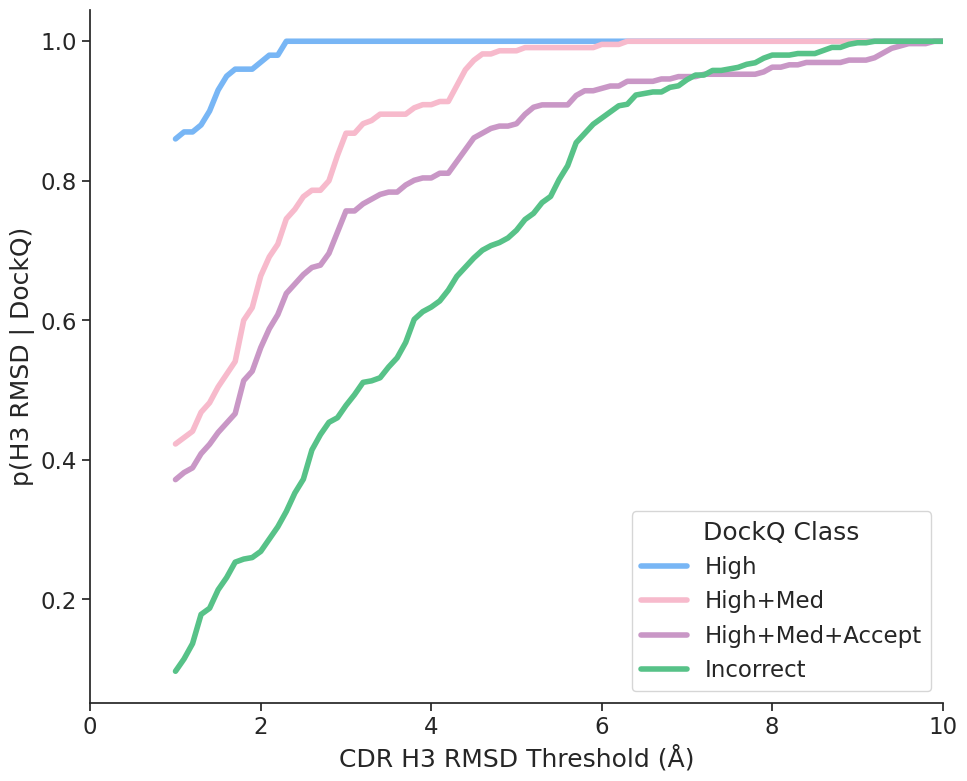

In [ ]:
plt.figure(figsize=(11,9))
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params,font_scale=1.5)
g = sns.lineplot(data=melted_phds,x='CDR H3 RMSD Threshold (Å)',y='p(H3 RMSD | DockQ)',hue='DockQ Class',palette=extended_pastel_palette[3:],lw=4)
plt.xlim(0,10)

/tmp/ipykernel_1544644/2172140296.py:4: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  g = sns.lineplot(data=melted_pdhs,x='CDR H3 RMSD Threshold (Å)',y='p(DockQ | H3 RMSD)',hue='DockQ Class',palette=extended_pastel_palette[3:],lw=4)


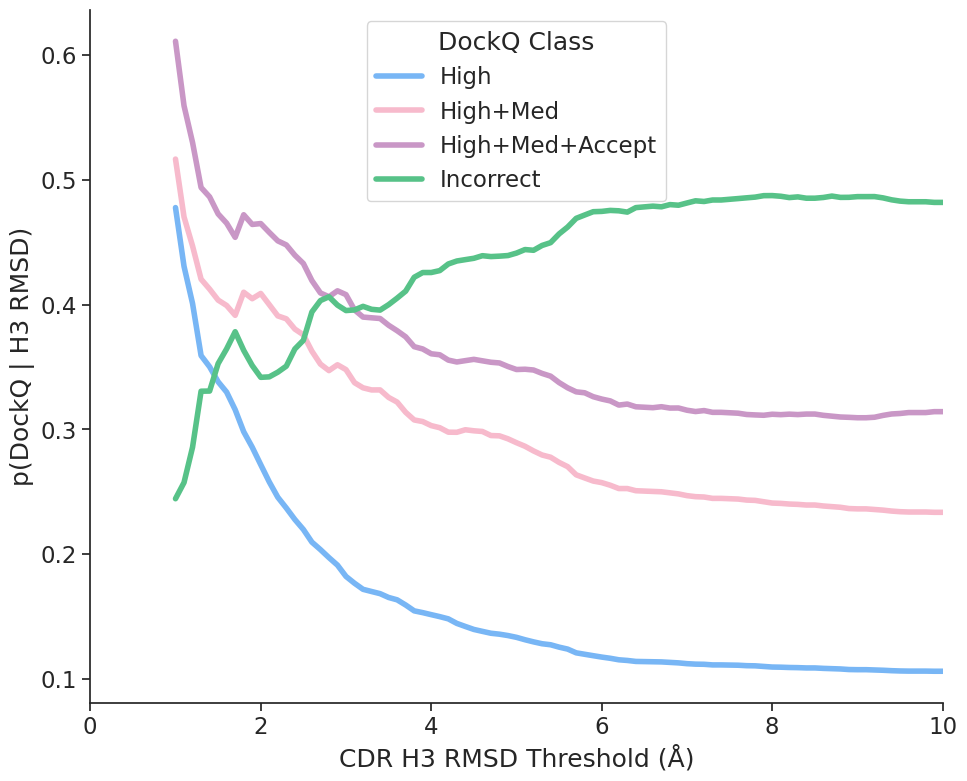

In [ ]:
plt.figure(figsize=(11,9))
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params,font_scale=1.5)
g = sns.lineplot(data=melted_pdhs,x='CDR H3 RMSD Threshold (Å)',y='p(DockQ | H3 RMSD)',hue='DockQ Class',palette=extended_pastel_palette[3:],lw=4)
plt.xlim(0,10)

In [82]:
alldockclasses = list(np.array(list(range(0,100,10)))/100) #['High','Medium','Acceptable']
alldockclasses.reverse()
# inc_class = ['Incorrect']
# inc_dockclass = ['Incorrect']
h3_thresholds = np.array(list(range(10,101)))/10 #[1,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0]

per_thresh_pHDs = []
per_thresh_pDHs = []

for i in h3_thresholds:
    print(f'for h3 thres {i}')
    DOCKQclasses = []
    phds_list = []
    pdhs_list = []
    for j in alldockclasses: # range(1,1+len(alldockclasses)):
        p_lowh3_given_highdockq,p_highdockq_given_lowh3 = pcond_thres(data_df,'low',i,j,'antibody')
        # print(f"p(H3 rmsd < {i} Å | DockQ score>={j}) is {p_lowh3_given_highdockq} \np(DockQ score>={j} | H3 rmsd < {i} Å ) is {p_highdockq_given_lowh3}")
        # print('-----')
        DOCKQclasses.append(j)
        phds_list.append(p_lowh3_given_highdockq)
        pdhs_list.append(p_highdockq_given_lowh3)
    # p_lowh3_given_highdockq,p_highdockq_given_lowh3 = pcond(data_df,'low',i,inc_dockclass,'antibody')
    # DOCKQclasses.append(inc_dockclass)
    # phds_list.append(p_lowh3_given_highdockq)
    # pdhs_list.append(p_highdockq_given_lowh3)
    per_thresh_pHDs.append(pd.DataFrame({i:phds_list},index=list(range(10))))
    per_thresh_pDHs.append(pd.DataFrame({i:pdhs_list},index=list(range(10))))
phds = pd.concat(per_thresh_pHDs,axis=1)
phds['DockQ >= X'] = DOCKQclasses #['High','High+Med','High+Med+Accept','Incorrect']
pdhs = pd.concat(per_thresh_pDHs,axis=1)
pdhs['DockQ >= X'] = DOCKQclasses #['High','High+Med','High+Med+Accept','Incorrect']

for h3 thres 1.0
for h3 thres 1.1
for h3 thres 1.2
for h3 thres 1.3
for h3 thres 1.4
for h3 thres 1.5
for h3 thres 1.6
for h3 thres 1.7
for h3 thres 1.8
for h3 thres 1.9
for h3 thres 2.0
for h3 thres 2.1
for h3 thres 2.2
for h3 thres 2.3
for h3 thres 2.4
for h3 thres 2.5
for h3 thres 2.6
for h3 thres 2.7
for h3 thres 2.8
for h3 thres 2.9
for h3 thres 3.0
for h3 thres 3.1
for h3 thres 3.2
for h3 thres 3.3
for h3 thres 3.4
for h3 thres 3.5
for h3 thres 3.6
for h3 thres 3.7
for h3 thres 3.8
for h3 thres 3.9
for h3 thres 4.0
for h3 thres 4.1
for h3 thres 4.2
for h3 thres 4.3
for h3 thres 4.4
for h3 thres 4.5
for h3 thres 4.6
for h3 thres 4.7
for h3 thres 4.8
for h3 thres 4.9
for h3 thres 5.0
for h3 thres 5.1
for h3 thres 5.2
for h3 thres 5.3
for h3 thres 5.4
for h3 thres 5.5
for h3 thres 5.6
for h3 thres 5.7
for h3 thres 5.8
for h3 thres 5.9
for h3 thres 6.0
for h3 thres 6.1
for h3 thres 6.2
for h3 thres 6.3
for h3 thres 6.4
for h3 thres 6.5
for h3 thres 6.6
for h3 thres 6.7
for h3 thres 6

In [115]:
melted_phds = phds.melt(id_vars=['DockQ >= X'],var_name='CDR H3 RMSD Threshold (Å)',value_name='p(H3 RMSD | DockQ)')
melted_pdhs = pdhs.melt(id_vars=['DockQ >= X'],var_name='CDR H3 RMSD Threshold (Å)',value_name='p(DockQ | H3 RMSD)')


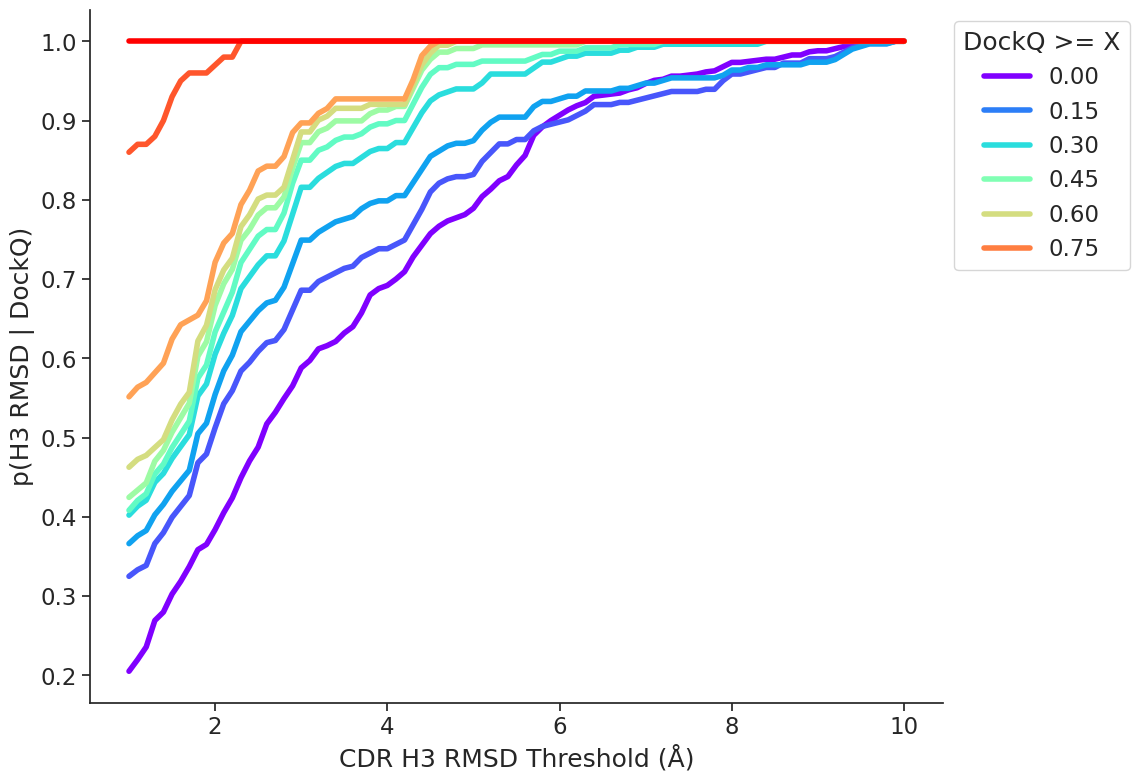

In [ ]:
plt.figure(figsize=(11,9))
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params,font_scale=1.5)
g = sns.lineplot(data=melted_phds,x='CDR H3 RMSD Threshold (Å)',y='p(H3 RMSD | DockQ)',hue='DockQ >= X',hue_order=[0.9,0.8,0.7,0.6,0.5,0.4,0.3,0.2,0.1,0.0],palette='rainbow',lw=4)
sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))

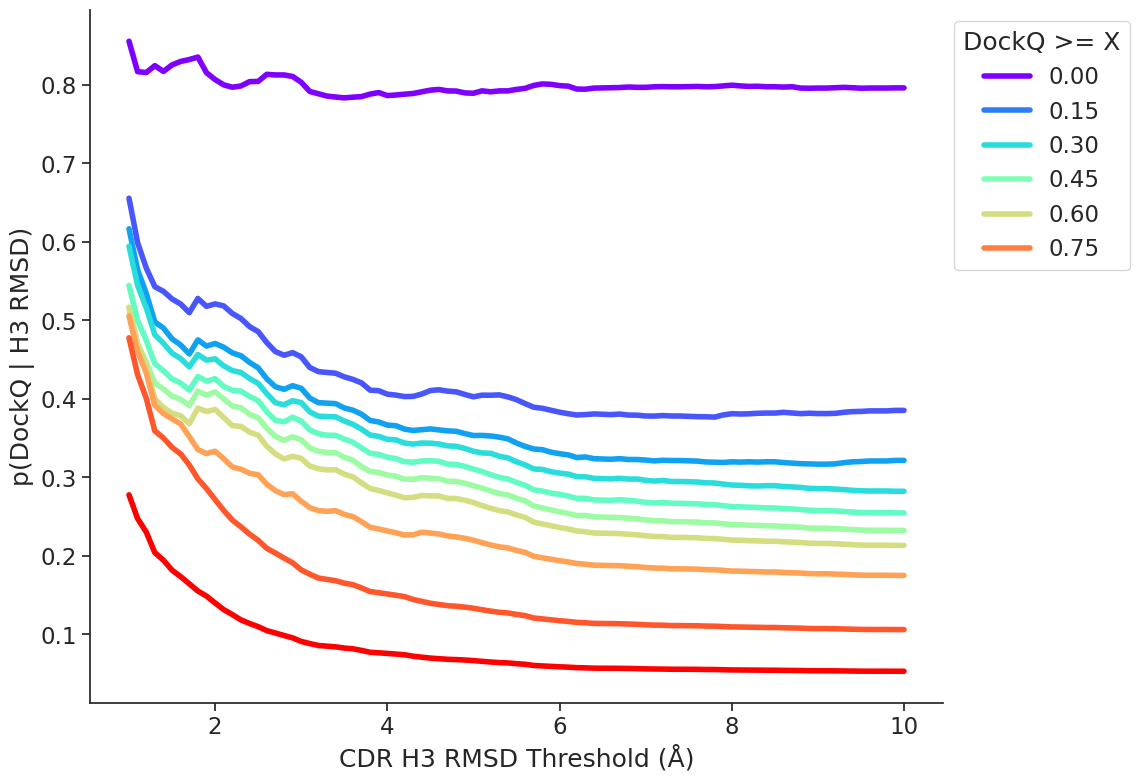

In [ ]:
plt.figure(figsize=(11,9))
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params,font_scale=1.5)
g = sns.lineplot(data=melted_pdhs,x='CDR H3 RMSD Threshold (Å)',y='p(DockQ | H3 RMSD)',hue='DockQ >= X',palette='rainbow',lw=4)
sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))

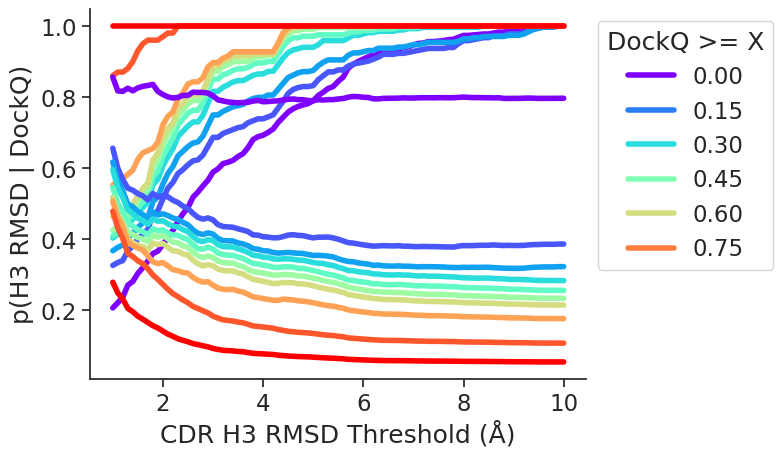

In [95]:
g = sns.lineplot(data=melted_phds,x='CDR H3 RMSD Threshold (Å)',y='p(H3 RMSD | DockQ)',hue='DockQ >= X',palette='rainbow',lw=4)
g = sns.lineplot(data=melted_pdhs,x='CDR H3 RMSD Threshold (Å)',y='p(DockQ | H3 RMSD)',hue='DockQ >= X',palette='rainbow',lw=4,legend=False)

sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))

### Nbs

<Figure size 2000x2000 with 0 Axes>

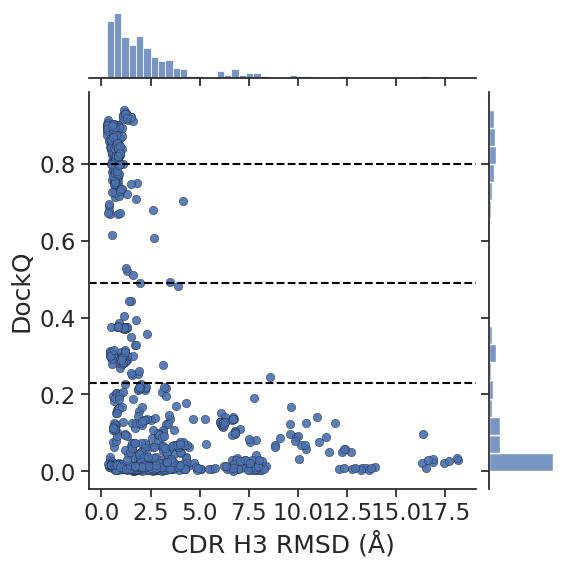

In [ ]:
plt.figure(figsize=(20,20))
# sns.set_style('whitegrid',{"grid.color":"0.6"})
data_df = final_af3_benchmark[final_af3_benchmark['Protein_type']=='nanobody']
# sns.set_style('whitegrid',{"grid.color":"0.6"})
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params,font_scale=1.5)
#data_df[(data_df['Seed']==2)&(data_df['Model']==0)&(data_df['l3_rms']<3)]
# ax = sns.scatterplot(data=data_df[data_df['Protein_type']=='antibody'],x='h3_rms',y='DockQ',\
ax = sns.jointplot(data=data_df,x='h3_rms',y='DockQ',\
                     alpha=0.7,edgecolor=edgecolor,linewidth=0.2,kind='scatter')
# ax = sns.kdeplot(data=full_benchmark_withdockq[full_benchmark_withdockq['Protein_type']=='nanobody'],x='h3_rms',y='DockQ',hue='h3_len') #,size='h3_len')
# ax.set_title("Correlation of DockQ to Antibody H3 Accuracy")
# plt.legend(loc='upper right')
sns.set(font_scale=1.0)
# ax.axvline(x=1,ls='--',color='black')
plt.axhline(y=0.23,ls='--',color='black')
plt.axhline(y=0.49,ls='--',color='black')
plt.axhline(y=0.80,ls='--',color='black')
plt.xlabel('CDR H3 RMSD (Å)')
# sns.move_legend(ax, "upper right", bbox_to_anchor=(1.6, 1.05))
# sns.lmplot(data=full_benchmark_withdockq[full_benchmark_withdockq['Protein_type']=='nanobody'],x='h3_rms',y='DockQ') #.set_title("Correlation of DockQ to H3 Accuracy")

/home/ftalib1/miniconda3/lib/python3.13/site-packages/seaborn/axisgrid.py:1832: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  func(x=self.x, y=self.y, **kwargs)
/home/ftalib1/miniconda3/lib/python3.13/site-packages/seaborn/axisgrid.py:1883: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  func(x=self.x, ax=self.ax_marg_x, **kwargs)
/home/ftalib1/miniconda3/lib/python3.13/site-packages/seaborn/axisgrid.py:1889: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  func(y=self.y, ax=self.ax_marg_y, **kwargs)


<Figure size 2000x2000 with 0 Axes>

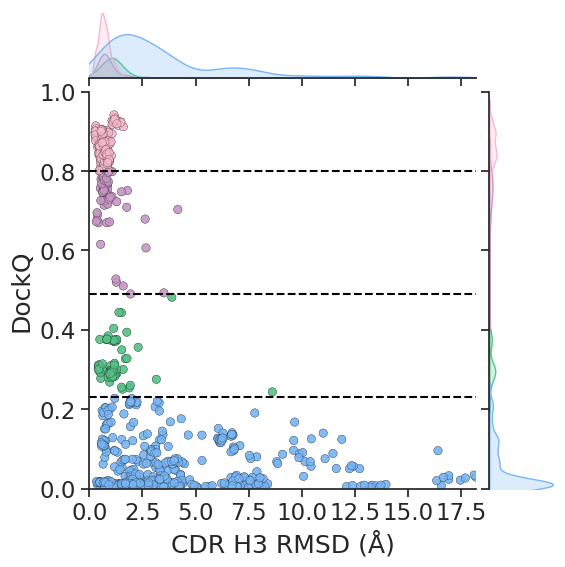

In [ ]:
plt.figure(figsize=(20,20))
# sns.set_style('whitegrid',{"grid.color":"0.6"})
data_df = final_af3_benchmark[final_af3_benchmark['Protein_type']=='nanobody']
# sns.set_style('whitegrid',{"grid.color":"0.6"})
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params,font_scale=1.5)
#data_df[(data_df['Seed']==2)&(data_df['Model']==0)&(data_df['l3_rms']<3)]
# ax = sns.scatterplot(data=data_df[data_df['Protein_type']=='antibody'],x='h3_rms',y='DockQ',\
ax = sns.jointplot(data=data_df,x='h3_rms',y='DockQ',\
                     alpha=0.7,edgecolor=edgecolor,linewidth=0.2,kind='scatter',hue='DockQ_Classification', palette=extended_pastel_palette[3:],legend=False)
ax.ax_marg_x.set_xlim(0, max(data_df.h3_rms.tolist()))
ax.ax_marg_y.set_ylim(0, 1)
# ax = sns.kdeplot(data=full_benchmark_withdockq[full_benchmark_withdockq['Protein_type']=='nanobody'],x='h3_rms',y='DockQ',hue='h3_len') #,size='h3_len')
# ax.set_title("Correlation of DockQ to Antibody H3 Accuracy")
# plt.legend(loc='upper right')
sns.set(font_scale=1.0)
# ax.axvline(x=1,ls='--',color='black')
plt.axhline(y=0.23,ls='--',color='black')
plt.axhline(y=0.49,ls='--',color='black')
plt.axhline(y=0.80,ls='--',color='black')
plt.xlabel('CDR H3 RMSD (Å)')
# sns.move_legend(ax, "upper right", bbox_to_anchor=(1.6, 1.05))
# sns.lmplot(data=full_benchmark_withdockq[full_benchmark_withdockq['Protein_type']=='nanobody'],x='h3_rms',y='DockQ') #.set_title("Correlation of DockQ to H3 Accuracy")

In [23]:
alldockclasses = list(np.array(list(range(0,100,10)))/100) #['High','Medium','Acceptable']
alldockclasses.reverse()
# inc_class = ['Incorrect']
# inc_dockclass = ['Incorrect']
h3_thresholds = np.array(list(range(10,178)))/10 #[1,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0]

per_thresh_pHDs = []
per_thresh_pDHs = []

for i in h3_thresholds:
    print(f'for h3 thres {i}')
    DOCKQclasses = []
    phds_list = []
    pdhs_list = []
    for j in alldockclasses: # range(1,1+len(alldockclasses)):
        p_lowh3_given_highdockq,p_highdockq_given_lowh3 = pcond_thres(data_df,'low',i,j,'nanobody')
        # print(f"p(H3 rmsd < {i} Å | DockQ score>={j}) is {p_lowh3_given_highdockq} \np(DockQ score>={j} | H3 rmsd < {i} Å ) is {p_highdockq_given_lowh3}")
        # print('-----')
        DOCKQclasses.append(j)
        phds_list.append(p_lowh3_given_highdockq)
        pdhs_list.append(p_highdockq_given_lowh3)
    # p_lowh3_given_highdockq,p_highdockq_given_lowh3 = pcond(data_df,'low',i,inc_dockclass,'antibody')
    # DOCKQclasses.append(inc_dockclass)
    # phds_list.append(p_lowh3_given_highdockq)
    # pdhs_list.append(p_highdockq_given_lowh3)
    per_thresh_pHDs.append(pd.DataFrame({i:phds_list},index=list(range(10))))
    per_thresh_pDHs.append(pd.DataFrame({i:pdhs_list},index=list(range(10))))
phds = pd.concat(per_thresh_pHDs,axis=1)
phds['DockQ >= X'] = DOCKQclasses #['High','High+Med','High+Med+Accept','Incorrect']
pdhs = pd.concat(per_thresh_pDHs,axis=1)
pdhs['DockQ >= X'] = DOCKQclasses #['High','High+Med','High+Med+Accept','Incorrect']

for h3 thres 1.0
for h3 thres 1.1


for h3 thres 1.2
for h3 thres 1.3
for h3 thres 1.4
for h3 thres 1.5
for h3 thres 1.6
for h3 thres 1.7
for h3 thres 1.8
for h3 thres 1.9
for h3 thres 2.0
for h3 thres 2.1
for h3 thres 2.2
for h3 thres 2.3
for h3 thres 2.4
for h3 thres 2.5
for h3 thres 2.6
for h3 thres 2.7
for h3 thres 2.8
for h3 thres 2.9
for h3 thres 3.0
for h3 thres 3.1
for h3 thres 3.2
for h3 thres 3.3
for h3 thres 3.4
for h3 thres 3.5
for h3 thres 3.6
for h3 thres 3.7
for h3 thres 3.8
for h3 thres 3.9
for h3 thres 4.0
for h3 thres 4.1
for h3 thres 4.2
for h3 thres 4.3
for h3 thres 4.4
for h3 thres 4.5
for h3 thres 4.6
for h3 thres 4.7
for h3 thres 4.8
for h3 thres 4.9
for h3 thres 5.0
for h3 thres 5.1
for h3 thres 5.2
for h3 thres 5.3
for h3 thres 5.4
for h3 thres 5.5
for h3 thres 5.6
for h3 thres 5.7
for h3 thres 5.8
for h3 thres 5.9
for h3 thres 6.0
for h3 thres 6.1
for h3 thres 6.2
for h3 thres 6.3
for h3 thres 6.4
for h3 thres 6.5
for h3 thres 6.6
for h3 thres 6.7
for h3 thres 6.8
for h3 thres 6.9
for h3 thres 7

/tmp/ipykernel_3227160/1728094522.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  phds['DockQ >= X'] = DOCKQclasses #['High','High+Med','High+Med+Accept','Incorrect']
/tmp/ipykernel_3227160/1728094522.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  pdhs['DockQ >= X'] = DOCKQclasses #['High','High+Med','High+Med+Accept','Incorrect']


In [24]:
alldockclasses = ['High','Medium','Acceptable']
inc_dockclass = ['Incorrect']
h3_thresholds = np.array(list(range(10,178)))/10 #[1,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0]

per_thresh_pHDs = []
per_thresh_pDHs = []
DOCKQclasses = []
for i in h3_thresholds:
    print(f'for h3 thres {i}')
    phds_list = []
    pdhs_list = []
    for j in range(1,1+len(alldockclasses)):
        p_lowh3_given_highdockq,p_highdockq_given_lowh3 = pcond(data_df,'low',i,alldockclasses[:j],'nanobody')
        # print(f"p(low h3 rmsd | {alldockclasses[:j]} DockQ score) is {p_lowh3_given_highdockq} \np({alldockclasses[:j]} DockQ score | low h3 rmsd) is {p_highdockq_given_lowh3}")
        # print('-----')
        DOCKQclasses.append(alldockclasses[:j])
        phds_list.append(p_lowh3_given_highdockq)
        pdhs_list.append(p_highdockq_given_lowh3)
    p_lowh3_given_highdockq,p_highdockq_given_lowh3 = pcond(data_df,'low',i,inc_dockclass,'nanobody')
    DOCKQclasses.append(inc_dockclass)
    phds_list.append(p_lowh3_given_highdockq)
    pdhs_list.append(p_highdockq_given_lowh3)
    per_thresh_pHDs.append(pd.DataFrame({i:phds_list},index=list(range(4))))
    per_thresh_pDHs.append(pd.DataFrame({i:pdhs_list},index=list(range(4))))
phds = pd.concat(per_thresh_pHDs,axis=1)
phds['DockQ Class'] = ['High','High+Med','High+Med+Accept','Incorrect']
pdhs = pd.concat(per_thresh_pDHs,axis=1)
pdhs['DockQ Class'] = ['High','High+Med','High+Med+Accept','Incorrect']

for h3 thres 1.0
for h3 thres 1.1
for h3 thres 1.2
for h3 thres 1.3
for h3 thres 1.4
for h3 thres 1.5
for h3 thres 1.6
for h3 thres 1.7
for h3 thres 1.8
for h3 thres 1.9
for h3 thres 2.0
for h3 thres 2.1
for h3 thres 2.2
for h3 thres 2.3
for h3 thres 2.4
for h3 thres 2.5
for h3 thres 2.6
for h3 thres 2.7
for h3 thres 2.8
for h3 thres 2.9
for h3 thres 3.0
for h3 thres 3.1
for h3 thres 3.2
for h3 thres 3.3
for h3 thres 3.4
for h3 thres 3.5
for h3 thres 3.6
for h3 thres 3.7
for h3 thres 3.8
for h3 thres 3.9
for h3 thres 4.0
for h3 thres 4.1
for h3 thres 4.2
for h3 thres 4.3
for h3 thres 4.4
for h3 thres 4.5
for h3 thres 4.6
for h3 thres 4.7
for h3 thres 4.8
for h3 thres 4.9
for h3 thres 5.0
for h3 thres 5.1
for h3 thres 5.2
for h3 thres 5.3
for h3 thres 5.4
for h3 thres 5.5
for h3 thres 5.6
for h3 thres 5.7
for h3 thres 5.8
for h3 thres 5.9
for h3 thres 6.0
for h3 thres 6.1
for h3 thres 6.2
for h3 thres 6.3
for h3 thres 6.4
for h3 thres 6.5
for h3 thres 6.6
for h3 thres 6.7
for h3 thres 6

/tmp/ipykernel_3227160/3602903343.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  phds['DockQ Class'] = ['High','High+Med','High+Med+Accept','Incorrect']
/tmp/ipykernel_3227160/3602903343.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  pdhs['DockQ Class'] = ['High','High+Med','High+Med+Accept','Incorrect']


In [27]:
melted_phds = phds.melt(id_vars=['DockQ Class'],var_name='CDR H3 RMSD Threshold (Å)',value_name='p(H3 RMSD | DockQ)')
melted_pdhs = pdhs.melt(id_vars=['DockQ Class'],var_name='CDR H3 RMSD Threshold (Å)',value_name='p(DockQ | H3 RMSD)')


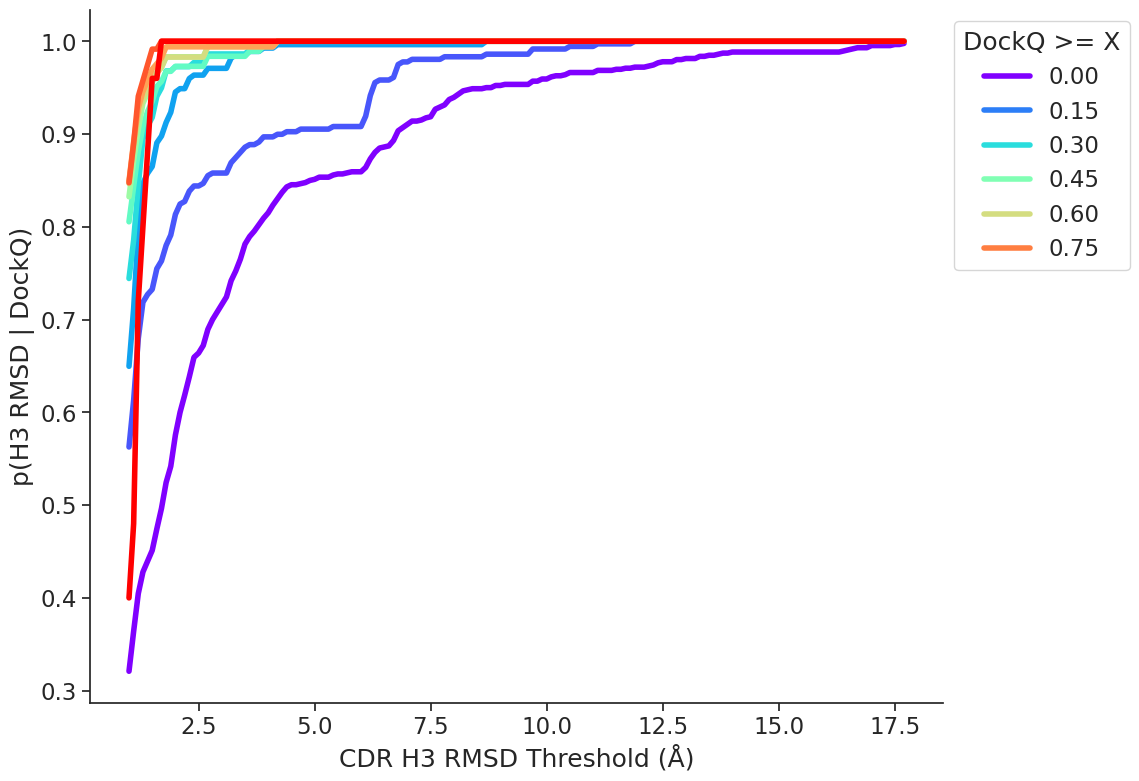

In [ ]:
plt.figure(figsize=(11,9))
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params,font_scale=1.5)
g = sns.lineplot(data=melted_phds,x='CDR H3 RMSD Threshold (Å)',y='p(H3 RMSD | DockQ)',hue='DockQ >= X',hue_order=[0.9,0.8,0.7,0.6,0.5,0.4,0.3,0.2,0.1,0.0],palette='rainbow',lw=4)
sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))

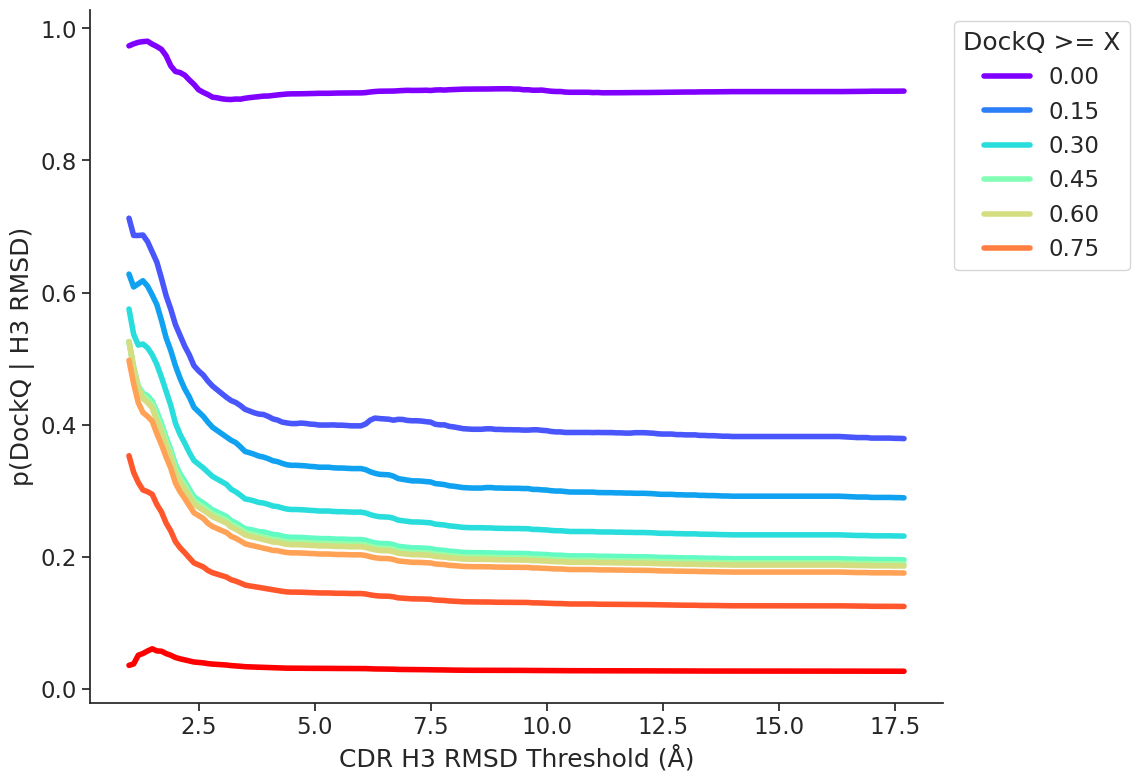

In [ ]:
plt.figure(figsize=(11,9))
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params,font_scale=1.5)
g = sns.lineplot(data=melted_pdhs,x='CDR H3 RMSD Threshold (Å)',y='p(DockQ | H3 RMSD)',hue='DockQ >= X',palette='rainbow',lw=4)
sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))

/tmp/ipykernel_3227160/3360434844.py:4: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  g = sns.lineplot(data=melted_phds,x='CDR H3 RMSD Threshold (Å)',y='p(H3 RMSD | DockQ)',hue='DockQ Class',palette=extended_pastel_palette[3:],lw=4)


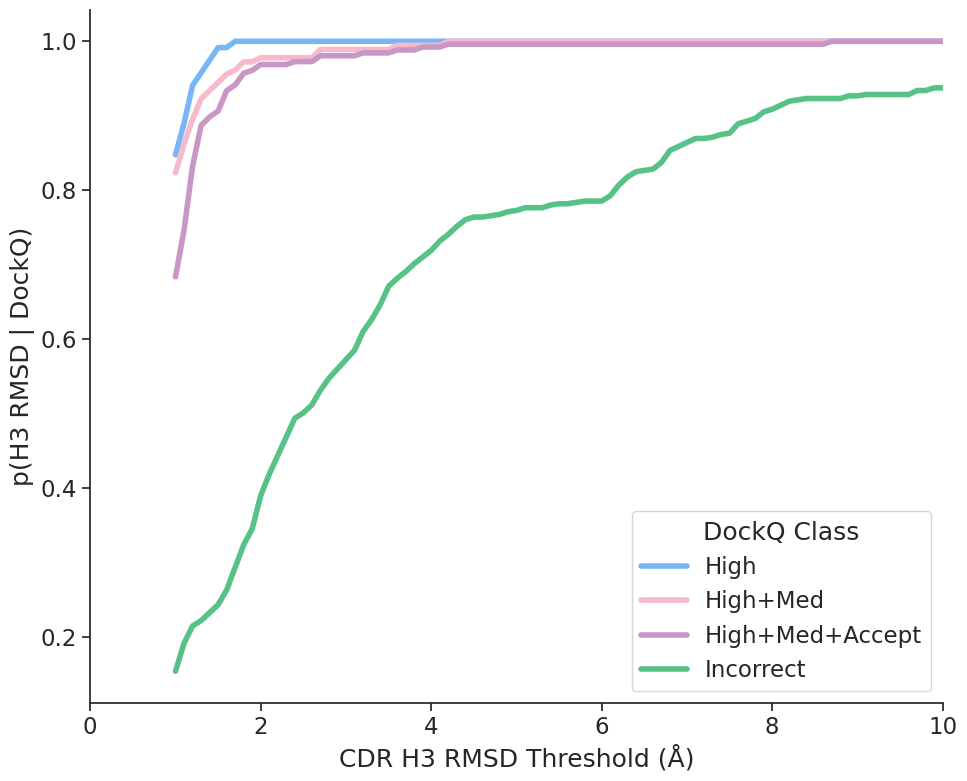

In [ ]:
plt.figure(figsize=(11,9))
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params,font_scale=1.5)
g = sns.lineplot(data=melted_phds,x='CDR H3 RMSD Threshold (Å)',y='p(H3 RMSD | DockQ)',hue='DockQ Class',palette=extended_pastel_palette[3:],lw=4)
plt.xlim(0,10)

/tmp/ipykernel_3227160/2818464499.py:4: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  g = sns.lineplot(data=melted_pdhs,x='CDR H3 RMSD Threshold (Å)',y='p(DockQ | H3 RMSD)',hue='DockQ Class',palette=extended_pastel_palette[3:],lw=4)


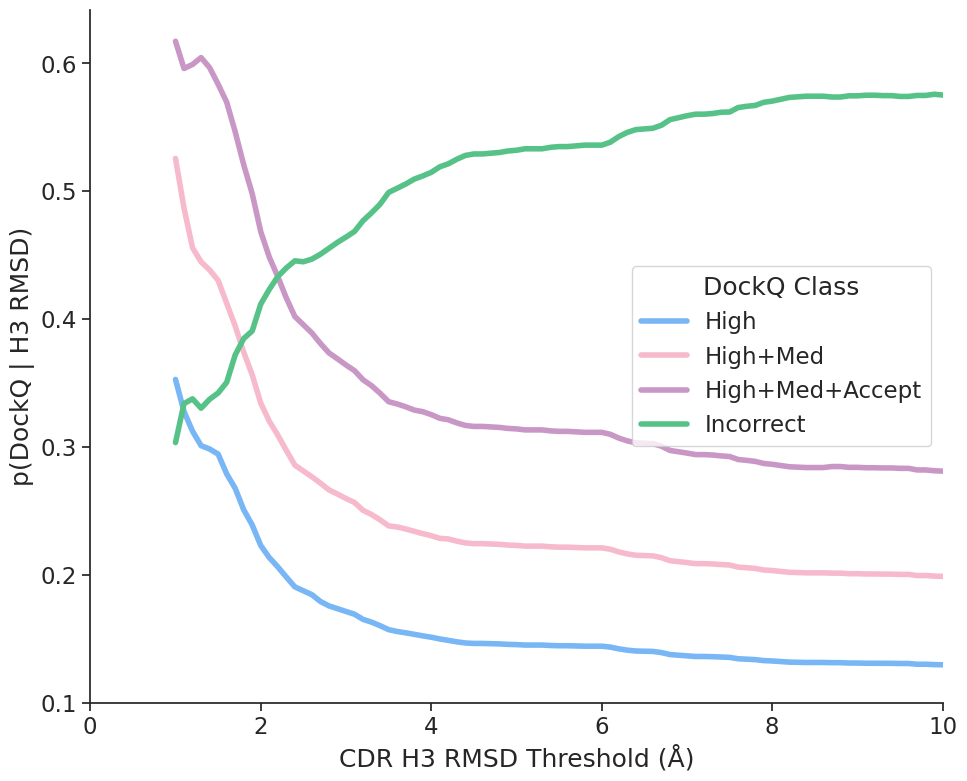

In [ ]:
plt.figure(figsize=(11,9))
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params,font_scale=1.5)
g = sns.lineplot(data=melted_pdhs,x='CDR H3 RMSD Threshold (Å)',y='p(DockQ | H3 RMSD)',hue='DockQ Class',palette=extended_pastel_palette[3:],lw=4)
plt.xlim(0,10)

## Panel 3: Unbound IgFold

In [3]:
def melt_igfold_benchmark_old(df):
    melted_df = pd.melt(df, id_vars=['PDB','Runtime','PDB_short','Model','h3_len','Protein_type'], \
                        value_vars=['ocd','frh_rms','h1_rms','h2_rms','h3_rms',\
                            'frl_rms','l1_rms','l2_rms','l3_rms'],\
                            var_name='Fv_Region', value_name='RMSD')
    return melted_df

def melt_igfold_benchmark(df):
    melted_df = pd.melt(df,id_vars=['Protein_type', 'Model', 'PDB','Runtime', 'Pred_Dir',
       'Pred_PDB', 'Bound_Unbound', 'Native_Dir', 'Native_PDB'],value_vars=['OCD', 'H Fr', 'CDRH1', 'CDRH2',
       'CDRH3', 'L Fr', 'CDRL1', 'CDRL2', 'CDRL3'],var_name = 'Fv_Region',value_name='RMSD (Å)')
    return melted_df
def melt_nb_igfold_benchmark(df):
    melted_df = pd.melt(df, id_vars=['PDB','Runtime','PDB_short','Model'], \
                        value_vars=['frh_rms','h1_rms','h2_rms','h3_rms'],\
                            var_name='Fv_Region', value_name='RMSD')
    return melted_df


In [4]:
melted_ig_benchmark = melt_igfold_benchmark(igfold_benchmark)
melted_ig_benchmark = melted_ig_benchmark.rename(columns={"Fv_Region":"CDR"})

### checking diff pre vs post-validation cutoff

In [36]:
# meta files import
# antibodies
ab_sabdab_path = "../sabdab_summary_all_240531.tsv"
ab_sabdab = pd.read_csv(ab_sabdab_path,delimiter='\t')

# nanobodies
nb_sabdab_path = "../20240604_0067950_summary_nanobodies.tsv"
nb_sabdab = pd.read_csv(nb_sabdab_path,delimiter='\t')

#antibodies
# ab_sabdab[pd.to_datetime(ab_sabdab['date'])>pd.to_datetime('September 30, 2021')]
ab_sabdab_postcutoff = ab_sabdab[pd.to_datetime(ab_sabdab['date'])>pd.to_datetime('September 30, 2021')].reset_index().drop(columns=['index'])
ab_sabdab_postcutoff = ab_sabdab_postcutoff.drop(list(np.where(ab_sabdab_postcutoff['Hchain'].isnull())[0])).reset_index().drop(columns=['index'])
ab_sabdab_postcutoff = ab_sabdab_postcutoff.drop(list(np.where(ab_sabdab_postcutoff['Lchain'].isnull())[0])).reset_index().drop(columns=['index'])

ab_sabdab_precutoff = ab_sabdab[pd.to_datetime(ab_sabdab['date'])<=pd.to_datetime('September 30, 2021')].reset_index().drop(columns=['index'])
ab_sabdab_precutoff = ab_sabdab_precutoff.drop(list(np.where(ab_sabdab_precutoff['Hchain'].isnull())[0])).reset_index().drop(columns=['index'])
ab_sabdab_precutoff = ab_sabdab_precutoff.drop(list(np.where(ab_sabdab_precutoff['Lchain'].isnull())[0])).reset_index().drop(columns=['index'])
# ab_sabdab_postcutoff

# nanobodies
nb_sabdab_postcutoff = nb_sabdab[pd.to_datetime(nb_sabdab['date'])>pd.to_datetime('September 30, 2021')].reset_index().drop(columns=['index'])
nb_sabdab_postcutoff = nb_sabdab_postcutoff.drop(list(np.where(nb_sabdab_postcutoff['Hchain'].isnull())[0])).reset_index().drop(columns=['index'])
nb_sabdab_postcutoff = nb_sabdab_postcutoff.drop(list(np.where(nb_sabdab_postcutoff['Lchain'].isnull()==False)[0])).reset_index().drop(columns=['index'])

nb_sabdab_precutoff = nb_sabdab[pd.to_datetime(nb_sabdab['date'])<=pd.to_datetime('September 30, 2021')].reset_index().drop(columns=['index'])
nb_sabdab_precutoff = nb_sabdab_precutoff.drop(list(np.where(nb_sabdab_precutoff['Hchain'].isnull())[0])).reset_index().drop(columns=['index'])
nb_sabdab_precutoff = nb_sabdab_precutoff.drop(list(np.where(nb_sabdab_precutoff['Lchain'].isnull())[0])).reset_index().drop(columns=['index'])
# nb_sabdab_postcutoff

# updated_sabdab_summaryab_sabdab[pd.to_datetime(updated_sabdab_summary['date'])>pd.to_datetime('January 12, 2023')] #.pdb.unique().shape
# updated_sabdab_summary[pd.to_datetime(updated_sabdab_summary['date'])>pd.to_datetime('January 12, 2023')].pdb.unique().shape

/tmp/ipykernel_3683213/2551961377.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ab_sabdab_postcutoff = ab_sabdab[pd.to_datetime(ab_sabdab['date'])>pd.to_datetime('September 30, 2021')].reset_index().drop(columns=['index'])
/tmp/ipykernel_3683213/2551961377.py:16: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ab_sabdab_precutoff = ab_sabdab[pd.to_datetime(ab_sabdab['date'])<=pd.to_datetime('September 30, 2021')].reset_index().drop(columns=['index'])
/tmp/ipykernel_3683213/2551961377.py:22: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  nb_sabdab_postcutoff = nb_sabdab[

In [8]:
igfold_post_all = pd.concat([melted_ig_benchmark[(melted_ig_benchmark['PDB'].isin(ab_postvalid))&(melted_ig_benchmark['Protein_type']=='antibody')],\
                                melted_ig_benchmark[(melted_ig_benchmark['PDB'].isin(nb_postvalid))&(melted_ig_benchmark['Protein_type']=='nanobody')]])
igfold_post_all

,Protein_type,Model,PDB,Runtime,Pred_Dir,Pred_PDB,Bound_Unbound,Native_Dir,Native_PDB,CDR,RMSD (Å)
0,antibody,AF3,7u0b,NaN,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_renamed_fold_7u0b_model_2.pdb,unbound,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_7u0b.pdb,OCD,3.047098
2,antibody,AF3,7qez,NaN,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_renamed_fold_7qez_model_4.pdb,unbound,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_7qez.pdb,OCD,3.204187
3,antibody,AF3,7t0k,NaN,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_renamed_fold_7t0k_model_3.pdb,unbound,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_7t0k.pdb,OCD,1.632921
4,antibody,AF3,7s5q,NaN,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_renamed_fold_7s5q_model_1.pdb,unbound,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_7s5q.pdb,OCD,2.825927
5,antibody,AF3,7u2d,NaN,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_renamed_fold_7u2d_model_4.pdb,unbound,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_7u2d.pdb,OCD,0.849407
...,...,...,...,...,...,...,...,...,...,...,...
9616,nanobody,AF2-M,7zmq,382.495446,NaN,NaN,NaN,NaN,NaN,CDRL3,NaN
9617,nanobody,AF2-M,7zms,398.114132,NaN,NaN,NaN,NaN,NaN,CDRL3,NaN
9618,nanobody,AF2-M,7zmv,350.135145,NaN,NaN,NaN,NaN,NaN,CDRL3,NaN
9619,nanobody,AF2-M,7zxu,327.644053,NaN,NaN,NaN,NaN,NaN,CDRL3,NaN


In [10]:
models = ['IgFold','AF2-M','AF2.3-M','AF3']
ptypes = ['nanobody','antibody']
for i in models:
    for j in ptypes:
        print(f'{i}, {j}')
        print(igfold_post_all[(igfold_post_all['Model']==i)&(igfold_post_all['Protein_type']==j)&(igfold_post_all['CDR']=='CDRH3')].describe())

IgFold, nanobody
         Runtime   RMSD (Å)
count  23.000000  23.000000
mean   14.981771   4.935002
std     0.561187   2.677364
min    13.251214   1.582235
25%    14.870925   2.777602
50%    15.115586   3.850400
75%    15.283210   7.535224
max    15.907202   9.917106
IgFold, antibody
         Runtime   RMSD (Å)
count  63.000000  63.000000
mean   23.239616   3.387707
std     0.597843   1.964037
min    22.044374   0.678250
25%    22.849563   2.032760
50%    23.237151   3.007752
75%    23.558749   4.206106
max    25.755559  11.320186
AF2-M, nanobody
          Runtime   RMSD (Å)
count   23.000000  23.000000
mean   346.509097   4.395738
std     24.359911   2.807877
min    298.970617   1.052518
25%    331.849940   1.892312
50%    342.309550   3.047197
75%    349.885334   7.194650
max    409.057924   8.846954
AF2-M, antibody
          Runtime   RMSD (Å)
count   63.000000  63.000000
mean   425.776525   4.008751
std     53.131034   2.865531
min    347.599225   0.367189
25%    382.282302   1.70

In [68]:
igfold_prepost_ab = pd.concat([melted_ig_benchmark[(melted_ig_benchmark['PDB'].isin(ab_prevalid))&(melted_ig_benchmark['Protein_type']=='antibody')]\
                               ,melted_ig_benchmark[(melted_ig_benchmark['PDB'].isin(ab_postvalid))&(melted_ig_benchmark['Protein_type']=='antibody')]],keys=['Pre-training','Post-training']).reset_index().drop(columns=['level_1']).rename(columns={"level_0":"Training Cutoff"})

In [71]:
igfold_prepost_nb = pd.concat([melted_ig_benchmark[(melted_ig_benchmark['PDB'].isin(nb_prevalid))&(melted_ig_benchmark['Protein_type']=='nanobody')],melted_ig_benchmark[(melted_ig_benchmark['PDB'].isin(nb_postvalid))&(melted_ig_benchmark['Protein_type']=='nanobody')]],keys=['Pre-training','Post-training']).reset_index().drop(columns=['level_1']).rename(columns={"level_0":"Training Cutoff"})
igfold_prepost = pd.concat([igfold_prepost_ab,igfold_prepost_nb])

/tmp/ipykernel_4051368/1155446341.py:5: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax = sns.catplot(data=dataset_df,\


<Figure size 900x900 with 0 Axes>

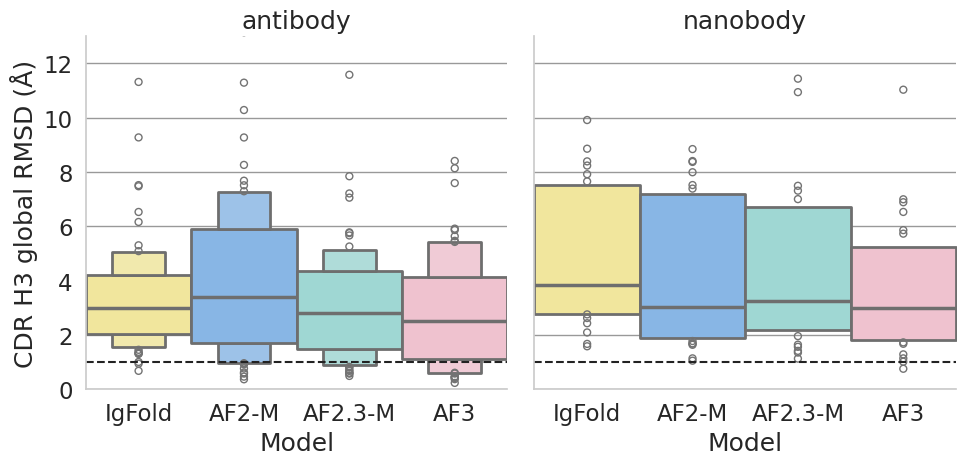

In [73]:
filepath = 'results/round_7/plots/'
sns.set_style("whitegrid", {"grid.color": ".6"}) 
plt.figure(figsize = (9,9))
dataset_df = igfold_post_all[(igfold_post_all['CDR'].str.contains('H3'))]
ax = sns.catplot(data=dataset_df,\
                 x='Model',y="RMSD (Å)",hue='Model',\
                 palette=pastel_palette,col='Protein_type',order=['IgFold','AF2-M','AF2.3-M','AF3'],linewidth=linewidth,kind='boxen',width=1.0)
sns.set(font_scale=1.5)
ax.set(ylim=(0, 13),ylabel='CDR H3 global RMSD (Å)')
ax.set_titles(col_template="{col_name}")
ax.refline(y=1.0,ls='--',color='#222222')
plt.savefig(f"{filepath}top_ranked_unbound_igfold_benchmark_posttrain.svg",format='svg',dpi=700,transparent=True,bbox_inches='tight')

In [75]:
#mannwhitney between models for ab
ptype1 = 'antibody'
ptype2 = 'nanobody'
cdr = 'CDRH3'
models = ['IgFold','AF2-M','AF2.3-M','AF3']

for i in range(len(models)):
    model1 = models[i]
    for j in range(i+1,len(models)):
        model2 = models[j]
        rmsds1 = igfold_benchmark[(igfold_benchmark['Model']==model1)&(igfold_benchmark['Protein_type']==ptype1)][cdr].tolist()
        rmsds2 = igfold_benchmark[(igfold_benchmark['Model']==model2)&(igfold_benchmark['Protein_type']==ptype1)][cdr].tolist()
        print(f"for {ptype1} comparing {model1} and {model2} p-val: {mannwhitneyu(rmsds1,rmsds2)[1]}")
        rmsds1 = igfold_benchmark[(igfold_benchmark['Model']==model1)&(igfold_benchmark['Protein_type']==ptype2)][cdr].tolist()
        rmsds2 = igfold_benchmark[(igfold_benchmark['Model']==model2)&(igfold_benchmark['Protein_type']==ptype2)][cdr].tolist()
        print(f"for {ptype2} comparing {model1} and {model2} p-val: {mannwhitneyu(rmsds1,rmsds2)[1]}")

for antibody comparing IgFold and AF2-M p-val: 0.8769528709373866
for nanobody comparing IgFold and AF2-M p-val: 0.2209478764399495
for antibody comparing IgFold and AF2.3-M p-val: 0.08889944842082133
for nanobody comparing IgFold and AF2.3-M p-val: 0.3719951436430958
for antibody comparing IgFold and AF3 p-val: 7.699868273711536e-05
for nanobody comparing IgFold and AF3 p-val: 0.0009926875768618815
for antibody comparing AF2-M and AF2.3-M p-val: 0.17320972625052922
for nanobody comparing AF2-M and AF2.3-M p-val: 0.7461678719100774
for antibody comparing AF2-M and AF3 p-val: 0.001504740165744371
for nanobody comparing AF2-M and AF3 p-val: 0.08147757924932812
for antibody comparing AF2.3-M and AF3 p-val: 0.03557139708144339
for nanobody comparing AF2.3-M and AF3 p-val: 0.03318822606111728


## Panel 4: Ag context

### Nbs

In [27]:
nb_bench =  pd.read_csv("results/round_8/datafiles/bound_nb_multiseed_rmsds.csv",index_col='Unnamed: 0')#final_af3_benchmark[final_af3_benchmark['Protein_type']=='nanobody']

seenag_pdbs = nb_sabdab[(nb_sabdab['pdb'].isin([x.split('_')[0] for x in nb_bound_bench.PDB_short.unique().tolist()]))\
                        & (nb_sabdab['antigen_name'].isin(nb_overlap_ags))].pdb.unique().tolist()

unseenag_pdbs = nb_sabdab[(nb_sabdab['pdb'].isin([x.split('_')[0] for x in nb_bound_bench.PDB_short.unique().tolist()]))\
                        & (~nb_sabdab['antigen_name'].isin(nb_overlap_ags))].pdb.unique().tolist()

In [28]:
nb_seenunseen_ag_sepdf = pd.concat([pd.concat([nb_bench[nb_bench['AF3_PDB'].str.contains(x)] for x in unseenag_pdbs]),\
    pd.concat([nb_bench[nb_bench['AF3_PDB'].str.contains(x)] for x in seenag_pdbs])],keys=['Unseen Ags','Seen Ags']).reset_index().drop(columns='level_1').rename(columns={'level_0':'Antigen Overlap'})

In [34]:
melted_nb_seenunseen_ag = pd.melt(nb_seenunseen_ag_sepdf,id_vars = ['Protein_type', 'Bound_Unbound',
       'Seed', 'PDB_short','Antigen Overlap'],value_vars=['ocd', 'frh_rms', 'h1_rms', 'h2_rms', 'h3_rms','H3_local_RMSD','frl_rms',
       'l1_rms', 'l2_rms', 'l3_rms'],var_name = "Fv_Region",value_name = "RMSD (Å)")
melted_nb_seenunseen_ag

,Protein_type,Bound_Unbound,Seed,PDB_short,Antigen Overlap,Fv_Region,RMSD (Å)
0,nanobody,bound,10,NaN,Unseen Ags,ocd,0.0
1,nanobody,bound,6,NaN,Unseen Ags,ocd,0.0
2,nanobody,bound,4,NaN,Unseen Ags,ocd,0.0
3,nanobody,bound,9,NaN,Unseen Ags,ocd,0.0
4,nanobody,bound,7,NaN,Unseen Ags,ocd,0.0
...,...,...,...,...,...,...,...
84415,nanobody,bound,3,7x7e_0.pdb,Seen Ags,l3_rms,0.0
84416,nanobody,bound,3,7x7e_0.pdb,Seen Ags,l3_rms,0.0
84417,nanobody,bound,3,7x7e_0.pdb,Seen Ags,l3_rms,0.0
84418,nanobody,bound,3,7x7e_0.pdb,Seen Ags,l3_rms,0.0


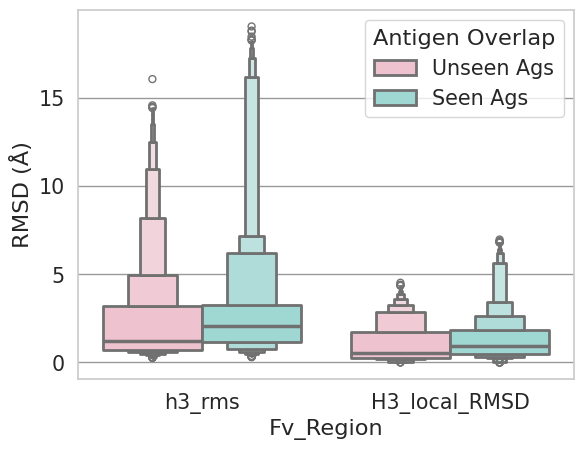

In [ ]:
# Ag overlap experiment

sns.set_style("whitegrid",{"grid.color":"0.6"})
g = sns.catplot(data=melted_nb_seenunseen_ag[melted_nb_seenunseen_ag['Fv_Region'].isin(['h3_rms','H3_local_RMSD'])].sort_values(by=['Bound_Unbound'],ascending=False),\
                 x='Fv_Region',y='RMSD (Å)',hue_order=['Unseen Ags','Seen Ags'],hue='Antigen Overlap',palette=pastel_palette[:2],linewidth=linewidth,legend=True,kind='boxen')
# g.ylim=((0,10))
# # g.set(ylim=g.axes.get_ylim()[::-1])
# g.axhline(y=1.0,ls='--',color='gray')
# g.set(xlabel=None)
sns.set(font_scale=1.35)
# for spine in g.spines.values():
#     spine.set_linewidth(1)
#     spine.set_color('black')
plt.savefig(f"{filepath}Nb_ag_overlap_bub_experiment.svg",format='svg',dpi=700,transparent=True,bbox_inches='tight')

### Abs

In [29]:
ab_bench =  pd.read_csv("results/round_8/datafiles/bound_ab_multiseed_rmsds.csv",index_col='Unnamed: 0')#final_af3_benchmark[final_af3_benchmark['Protein_type']=='nanobody']

seenag_pdbs = ab_sabdab[(ab_sabdab['pdb'].isin([x.split('_')[0] for x in ab_bound_bench.PDB_short.unique().tolist()]))\
                        & (ab_sabdab['antigen_name'].isin(ab_overlap_ags))].pdb.unique().tolist()

unseenag_pdbs = ab_sabdab[(ab_sabdab['pdb'].isin([x.split('_')[0] for x in ab_bound_bench.PDB_short.unique().tolist()]))\
                        & (~ab_sabdab['antigen_name'].isin(ab_overlap_ags))].pdb.unique().tolist()

In [30]:
ab_seenunseen_ag_sepdf = pd.concat([pd.concat([ab_bench[ab_bench['AF3_PDB'].str.contains(x)] for x in unseenag_pdbs]),\
    pd.concat([ab_bench[ab_bench['AF3_PDB'].str.contains(x)] for x in seenag_pdbs])],keys=['Unseen Ags','Seen Ags']).reset_index().drop(columns='level_1').rename(columns={'level_0':'Antigen Overlap'})

In [38]:
melted_ab_seenunseen_ag = pd.melt(ab_seenunseen_ag_sepdf,id_vars = ['Protein_type', 'Bound_Unbound',
       'Seed', 'PDB_short','Antigen Overlap'],value_vars=['ocd', 'frh_rms', 'h1_rms', 'h2_rms', 'h3_rms','H3_local_RMSD','frl_rms',
       'l1_rms', 'l2_rms', 'l3_rms'],var_name = "Fv_Region",value_name = "RMSD (Å)")
melted_ab_seenunseen_ag

,Protein_type,Bound_Unbound,Seed,PDB_short,Antigen Overlap,Fv_Region,RMSD (Å)
0,antibody,bound,14,NaN,Unseen Ags,ocd,2.782843
1,antibody,bound,17,NaN,Unseen Ags,ocd,3.828237
2,antibody,bound,9,NaN,Unseen Ags,ocd,3.291700
3,antibody,bound,20,NaN,Unseen Ags,ocd,3.870761
4,antibody,bound,6,NaN,Unseen Ags,ocd,2.960854
...,...,...,...,...,...,...,...
38345,antibody,bound,2,7so5_0.pdb,Seen Ags,l3_rms,0.638663
38346,antibody,bound,2,7so5_0.pdb,Seen Ags,l3_rms,0.591367
38347,antibody,bound,2,7so5_0.pdb,Seen Ags,l3_rms,0.610142
38348,antibody,bound,2,7so5_0.pdb,Seen Ags,l3_rms,0.654640


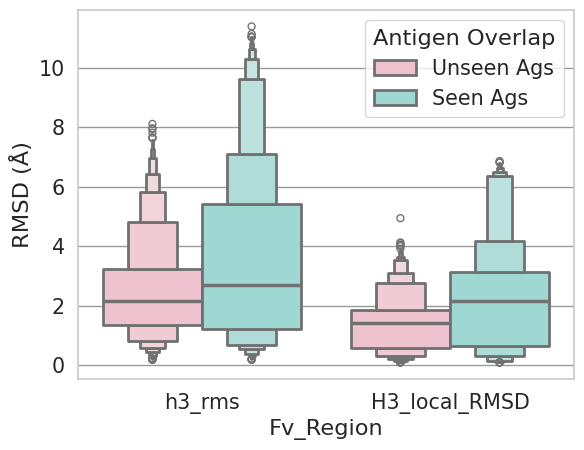

In [52]:
# Ag overlap experiment

sns.set_style("whitegrid",{"grid.color":"0.6"})
g = sns.boxenplot(data=melted_ab_seenunseen_ag[melted_ab_seenunseen_ag['Fv_Region'].isin(['h3_rms','H3_local_RMSD'])].sort_values(by=['Bound_Unbound'],ascending=False),\
                 x='Fv_Region',y='RMSD (Å)',hue_order=['Unseen Ags','Seen Ags'],hue='Antigen Overlap',palette=pastel_palette[:2],linewidth=linewidth,legend=True)
# g.ylim=((0,10))
# # g.set(ylim=g.axes.get_ylim()[::-1])
# g.axhline(y=1.0,ls='--',color='gray')
# g.set(xlabel=None)
sns.set(font_scale=1.35)
# for spine in g.spines.values():
#     spine.set_linewidth(1)
#     spine.set_color('black')

In [31]:
# combining ab and nb into single plot (consistency)

seen_unseen_ags = pd.concat([nb_seenunseen_ag_sepdf,ab_seenunseen_ag_sepdf],ignore_index=True)
melted_seen_unseen_ags = pd.melt(seen_unseen_ags,id_vars = ['Protein_type', 'Bound_Unbound',
       'Seed', 'PDB_short','Antigen Overlap'],value_vars=['ocd', 'frh_rms', 'h1_rms', 'h2_rms', 'h3_rms','H3_local_RMSD','frl_rms',
       'l1_rms', 'l2_rms', 'l3_rms'],var_name = "Fv_Region",value_name = "RMSD (Å)")

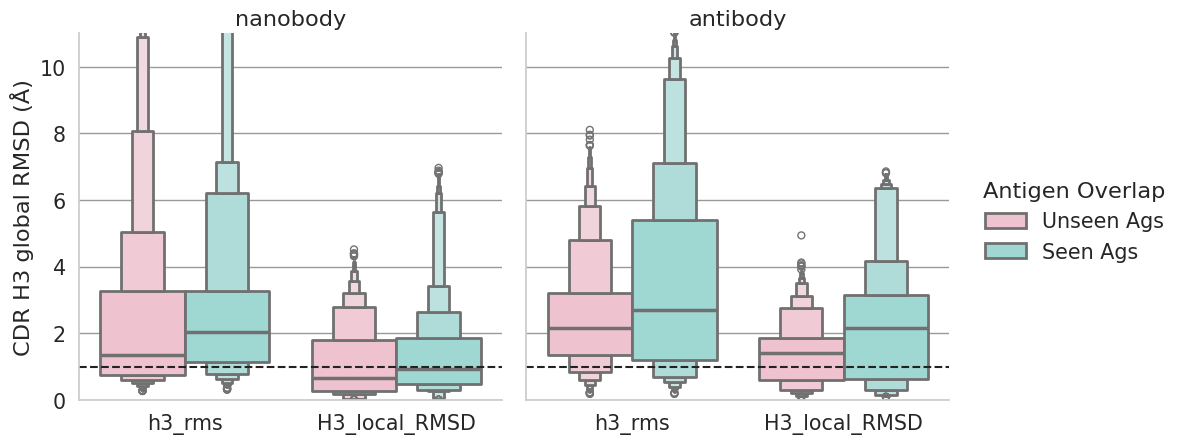

In [ ]:

# Ag overlap experiment
sns.set_style("whitegrid",{"grid.color":"0.6"})
g = sns.catplot(data=melted_seen_unseen_ags[melted_seen_unseen_ags['Fv_Region'].isin(['h3_rms','H3_local_RMSD'])].sort_values(by=['Bound_Unbound'],ascending=False),\
                 x='Fv_Region',y='RMSD (Å)',hue_order=['Unseen Ags','Seen Ags'],col='Protein_type',hue='Antigen Overlap',palette=pastel_palette[:2],linewidth=linewidth,legend=True,kind='boxen')
g.set(ylim=(0, 11),ylabel='CDR H3 global RMSD (Å)')
# # g.set(ylim=g.axes.get_ylim()[::-1])
g.refline(y=1.0,ls='--',color='#222222')
g.set_titles(col_template="{col_name}")
g.set(xlabel=None)
sns.set(font_scale=1.35)

In [ ]:
dataset_df = melted_seen_unseen_ags
ptype = 'antibody'
fv_region = 'h3_rms'
group1 = dataset_df[(dataset_df['Protein_type']==ptype)&(dataset_df['Antigen Overlap']=='Unseen Ags')&(dataset_df['Fv_Region']==fv_region)]['RMSD (Å)']
group2 = dataset_df[(dataset_df['Protein_type']==ptype)&(dataset_df['Antigen Overlap']=='Seen Ags')&(dataset_df['Fv_Region']==fv_region)]['RMSD (Å)']
seen_unseencompare = mannwhitneyu(group1.tolist(),group2.tolist())
print(f"{ptype} p-val for {fv_region}: {seen_unseencompare[1]}")


nanobody p-val for h3_rms: 4.869500864829808e-39


In [ ]:
dataset_df = melted_seen_unseen_ags
ptype = 'antibody'
fv_region = 'H3_local_RMSD'
group1 = dataset_df[(dataset_df['Protein_type']==ptype)&(dataset_df['Antigen Overlap']=='Unseen Ags')&(dataset_df['Fv_Region']==fv_region)]['RMSD (Å)']
group2 = dataset_df[(dataset_df['Protein_type']==ptype)&(dataset_df['Antigen Overlap']=='Seen Ags')&(dataset_df['Fv_Region']==fv_region)]['RMSD (Å)']
seen_unseencompare = mannwhitneyu(group1.tolist(),group2.tolist())
print(f"{ptype} p-val for {fv_region}: {seen_unseencompare[1]}")


nanobody p-val for H3_local_RMSD: 3.3049970346548678e-34


## bound-unbound test

#### Nbs

In [45]:
def get_20seeds(df,pdblist):
    twentyseed_list = []
    for i in pdblist:
        pdb_row = df[df['PDB_short']==i]
        seeds = pdb_row.Seed.unique().tolist()[:20]
        pdb_row = pdb_row[pdb_row['Seed'].isin(seeds)]
        twentyseed_list.append(pdb_row)
    return pd.concat(twentyseed_list)


In [ ]:
boundnb_rmsds = pd.read_csv("results/round_8/datafiles/bound_nb_multiseed_rmsds.csv",index_col='Unnamed: 0')
boundnb_rmsds['PDB_short']= ['_'.join(x.split('/')[-1].split('_')[-4:-2])+'.pdb' for x in boundnb_rmsds.AF3_PDB.tolist()]
boundnb_rmsds= get_20seeds(boundnb_rmsds,boundnb_rmsds.PDB_short.unique().tolist())
unboundnb_rmsds = pd.read_csv("results/round_8/datafiles/unbound_nb_multiseed_rmsds.csv",index_col='Unnamed: 0')
unboundnb_rmsds= get_20seeds(unboundnb_rmsds,unboundnb_rmsds.PDB_short.unique().tolist())
fullnb_bound_unbound = pd.concat([boundnb_rmsds,unboundnb_rmsds],ignore_index=True)
fullnb_bound_unbound

,AF3_Dir,AF3_PDB,Bound_Unbound,Protein_type,Native_Dir,Native_PDB,H3_local_RMSD,ocd,frh_rms,h1_rms,h2_rms,h3_rms,frl_rms,l1_rms,l2_rms,l3_rms,PDB_short,DockQ,DockQ_Classification,Seed
0,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,bound,nanobody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8cxn_2.pdb,3.434012,0.0,4.466730,6.166744,7.002302,6.647850,0.0,0.0,0.0,0.0,8cxn_2.pdb,NaN,NaN,10
1,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,bound,nanobody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8cxn_2.pdb,3.441833,0.0,4.472455,6.107289,7.052515,6.742234,0.0,0.0,0.0,0.0,8cxn_2.pdb,NaN,NaN,7
2,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,bound,nanobody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8cxn_2.pdb,3.422623,0.0,4.469364,5.994948,7.023617,6.743999,0.0,0.0,0.0,0.0,8cxn_2.pdb,NaN,NaN,5
3,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,bound,nanobody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8cxn_2.pdb,3.435848,0.0,4.477021,6.087749,7.026664,6.734138,0.0,0.0,0.0,0.0,8cxn_2.pdb,NaN,NaN,6
4,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,bound,nanobody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8cxn_2.pdb,3.429575,0.0,4.469043,6.056218,7.067272,6.799612,0.0,0.0,0.0,0.0,8cxn_2.pdb,NaN,NaN,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3273,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_renamed_fold_7r20_0_seed3_model_0.pdb,unbound,nanobody,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_7r20_0.pdb,3.423403,0.0,0.951679,2.098672,0.850111,10.044665,0.0,0.0,0.0,0.0,7r20_0.pdb,NaN,NaN,3
3274,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_renamed_fold_7r20_0_seed3_model_1.pdb,unbound,nanobody,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_7r20_0.pdb,3.325475,0.0,0.970992,1.975742,0.873430,9.242922,0.0,0.0,0.0,0.0,7r20_0.pdb,NaN,NaN,3
3275,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_renamed_fold_7r20_0_seed3_model_2.pdb,unbound,nanobody,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_7r20_0.pdb,3.414226,0.0,1.025513,2.131326,1.010852,10.041354,0.0,0.0,0.0,0.0,7r20_0.pdb,NaN,NaN,3
3276,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_renamed_fold_7r20_0_seed3_model_3.pdb,unbound,nanobody,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,renum_7r20_0.pdb,3.263705,0.0,1.004751,2.169320,0.908451,9.671795,0.0,0.0,0.0,0.0,7r20_0.pdb,NaN,NaN,3


In [47]:
melted_fullnb_bound_unbound = pd.melt(fullnb_bound_unbound,id_vars = ['Protein_type', 'Bound_Unbound',
       'Seed', 'PDB_short'],value_vars=['ocd', 'frh_rms', 'h1_rms', 'h2_rms', 'h3_rms','H3_local_RMSD','frl_rms',
       'l1_rms', 'l2_rms', 'l3_rms'],var_name = "Fv_Region",value_name = "RMSD (Å)")
melted_fullnb_bound_unbound

,Protein_type,Bound_Unbound,Seed,PDB_short,Fv_Region,RMSD (Å)
0,nanobody,bound,10,8cxn_2.pdb,ocd,0.0
1,nanobody,bound,7,8cxn_2.pdb,ocd,0.0
2,nanobody,bound,5,8cxn_2.pdb,ocd,0.0
3,nanobody,bound,6,8cxn_2.pdb,ocd,0.0
4,nanobody,bound,9,8cxn_2.pdb,ocd,0.0
...,...,...,...,...,...,...
32775,nanobody,unbound,3,7r20_0.pdb,l3_rms,0.0
32776,nanobody,unbound,3,7r20_0.pdb,l3_rms,0.0
32777,nanobody,unbound,3,7r20_0.pdb,l3_rms,0.0
32778,nanobody,unbound,3,7r20_0.pdb,l3_rms,0.0


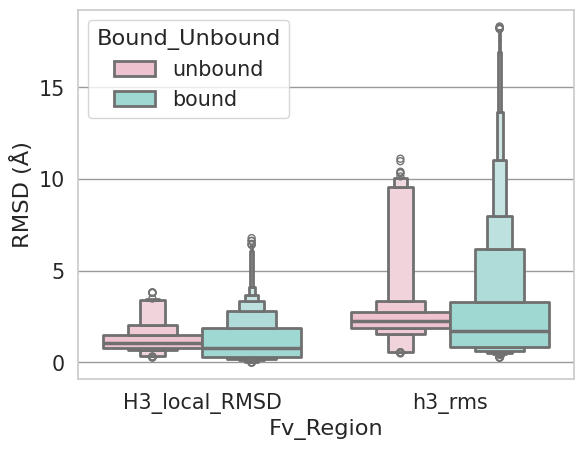

In [63]:
# Bound-Unbound with enough seeds experiment

sns.set_style("whitegrid",{"grid.color":"0.6"})
g = sns.boxenplot(data=melted_fullnb_bound_unbound[melted_fullnb_bound_unbound['Fv_Region'].isin(['h3_rms','H3_local_RMSD'])].sort_values(by=['Bound_Unbound'],ascending=False),\
                 x='Fv_Region',y='RMSD (Å)',hue_order=['unbound','bound'],hue='Bound_Unbound',palette=pastel_palette[:2],linewidth=linewidth,legend=True)
# g.ylim=((0,10))
# # g.set(ylim=g.axes.get_ylim()[::-1])
# g.axhline(y=1.0,ls='--',color='gray')
# g.set(xlabel=None)
sns.set(font_scale=1.35)
# for spine in g.spines.values():
#     spine.set_linewidth(1)
#     spine.set_color('black')

#### Abs

In [54]:
boundab_rmsds = pd.read_csv("results/round_8/datafiles/bound_ab_multiseed_rmsds.csv",index_col='Unnamed: 0')
boundab_rmsds['PDB_short']= ['_'.join(x.split('/')[-1].split('_')[-4:-2])+'.pdb' for x in boundab_rmsds.AF3_PDB.tolist()]
boundab_rmsds= get_20seeds(boundab_rmsds,boundab_rmsds.PDB_short.unique().tolist())
unboundab_rmsds = pd.read_csv("results/round_8/datafiles/unbound_ab_multiseed_rmsds.csv",index_col='Unnamed: 0')
unboundab_rmsds= get_20seeds(unboundab_rmsds,unboundab_rmsds.PDB_short.unique().tolist())
fullab_bound_unbound = pd.concat([boundab_rmsds,unboundab_rmsds],ignore_index=True)
fullab_bound_unbound

,AF3_Dir,AF3_PDB,Bound_Unbound,Protein_type,Native_Dir,Native_PDB,H3_local_RMSD,ocd,frh_rms,h1_rms,h2_rms,h3_rms,frl_rms,l1_rms,l2_rms,l3_rms,PDB_short,DockQ,DockQ_Classification,Seed
0,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,bound,antibody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8f9t_1.pdb,1.180349,1.103960,0.317664,0.292186,0.553596,1.112152,0.390720,0.173741,0.537939,0.334156,8f9t_1.pdb,NaN,NaN,7
1,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,bound,antibody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8f9t_1.pdb,1.137808,1.105953,0.353373,0.269339,0.508579,1.113769,0.339470,0.226010,0.538652,0.270320,8f9t_1.pdb,NaN,NaN,6
2,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,bound,antibody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8f9t_1.pdb,1.085068,1.604126,0.297799,0.252951,0.536496,1.144460,0.316023,0.191313,0.502733,0.328590,8f9t_1.pdb,NaN,NaN,15
3,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,bound,antibody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8f9t_1.pdb,0.932445,1.100653,0.320785,0.227271,0.528306,0.915996,0.390430,0.259871,0.518075,0.356271,8f9t_1.pdb,NaN,NaN,8
4,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,bound,antibody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8f9t_1.pdb,1.157101,0.263490,0.319694,0.277099,0.532692,1.178525,0.354551,0.318677,0.523889,0.309679,8f9t_1.pdb,NaN,NaN,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3192,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8g1b_1_seed2_model_4.pdb,unbound,antibody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8g1b_1.pdb,2.019595,4.402248,0.382337,0.387520,0.820300,2.946156,0.377985,1.242060,0.309776,0.740935,8g1b_1.pdb,NaN,NaN,2
3193,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8g1b_1_seed2_model_0.pdb,unbound,antibody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8g1b_1.pdb,1.906666,4.588850,0.347956,0.319054,0.787377,3.043465,0.371579,1.029293,0.326260,0.657133,8g1b_1.pdb,NaN,NaN,2
3194,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8g1b_1_seed2_model_1.pdb,unbound,antibody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8g1b_1.pdb,1.880896,3.547389,0.404077,0.420071,0.771825,3.010874,0.332305,0.962750,0.305823,0.589328,8g1b_1.pdb,NaN,NaN,2
3195,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8g1b_1_seed2_model_2.pdb,unbound,antibody,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8g1b_1.pdb,1.988007,3.663143,0.382649,0.371424,0.839291,3.221837,0.316070,0.885521,0.336010,0.650787,8g1b_1.pdb,NaN,NaN,2


In [56]:
bub_df = pd.concat([fullab_bound_unbound,fullnb_bound_unbound],ignore_index=True)
melted_bub_df =  pd.melt(bub_df,id_vars = ['Protein_type', 'Bound_Unbound',
       'Seed', 'PDB_short'],value_vars=['ocd', 'frh_rms', 'h1_rms', 'h2_rms', 'h3_rms','H3_local_RMSD','frl_rms',
       'l1_rms', 'l2_rms', 'l3_rms'],var_name = "Fv_Region",value_name = "RMSD (Å)")

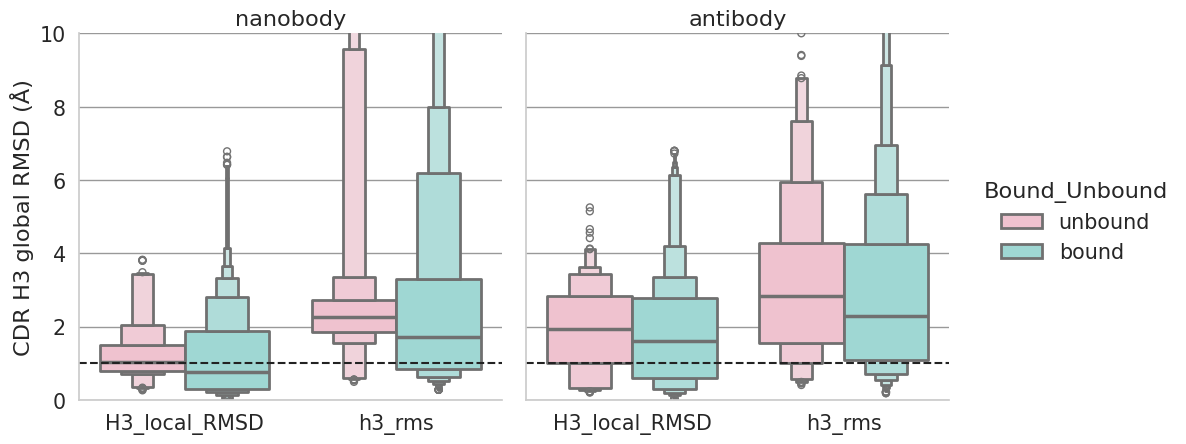

In [62]:
# Bound-Unbound with enough seeds experiment

sns.set_style("whitegrid",{"grid.color":"0.6"})
g = sns.catplot(data=melted_bub_df[melted_bub_df['Fv_Region'].isin(['h3_rms','H3_local_RMSD'])].sort_values(by=['Bound_Unbound'],ascending=False),\
                 x='Fv_Region',y='RMSD (Å)',hue_order=['unbound','bound'],col='Protein_type',hue='Bound_Unbound',palette=pastel_palette[:2],linewidth=linewidth,legend=True,kind='boxen')
# g.ylim=((0,10))
g.set(ylim=(0, 10),ylabel='CDR H3 global RMSD (Å)')
# # g.set(ylim=g.axes.get_ylim()[::-1])
g.refline(y=1.0,ls='--',color='#222222')
g.set_titles(col_template="{col_name}")
g.set(xlabel=None)
sns.set(font_scale=1.35)

In [64]:
dataset_df = melted_bub_df
ptype = 'nanobody'
fv_region = 'h3_rms'
group1 = dataset_df[(dataset_df['Protein_type']==ptype)&(dataset_df['Bound_Unbound']=='unbound')&(dataset_df['Fv_Region']==fv_region)]['RMSD (Å)']
group2 = dataset_df[(dataset_df['Protein_type']==ptype)&(dataset_df['Bound_Unbound']=='bound')&(dataset_df['Fv_Region']==fv_region)]['RMSD (Å)']
seen_unseencompare = mannwhitneyu(group1.tolist(),group2.tolist())
print(f"{ptype} p-val for {fv_region}: {seen_unseencompare[1]}")


nanobody p-val for h3_rms: 6.242247817262484e-06


In [65]:
dataset_df = melted_bub_df
ptype = 'nanobody'
fv_region = 'H3_local_RMSD'
group1 = dataset_df[(dataset_df['Protein_type']==ptype)&(dataset_df['Bound_Unbound']=='unbound')&(dataset_df['Fv_Region']==fv_region)]['RMSD (Å)']
group2 = dataset_df[(dataset_df['Protein_type']==ptype)&(dataset_df['Bound_Unbound']=='bound')&(dataset_df['Fv_Region']==fv_region)]['RMSD (Å)']
seen_unseencompare = mannwhitneyu(group1.tolist(),group2.tolist())
print(f"{ptype} p-val for {fv_region}: {seen_unseencompare[1]}")


nanobody p-val for H3_local_RMSD: 1.0809889124214501e-05


### Nbs

In [51]:
data_df=melted_AF2_v_AF3[(melted_AF2_v_AF3['Model_Source']=='AF3')\
                 &(melted_AF2_v_AF3['Protein_type']=='nanobody') & ((melted_AF2_v_AF3['Fv_Region'].str.contains('H3'))|(melted_AF2_v_AF3['Fv_Region'].str.contains('h3')))].dropna(subset=['RMSD (Å)'])
data_df = data_df[data_df['PDB_short'].isin(final_nbs)]
data_df['RMSD (Å)']=data_df['RMSD (Å)'].astype('float')
data_df=data_df.replace({"Fv_Region":{"h3_rms":"H3 global RMSD"}})
data_df=data_df.replace({"Fv_Region":{"H3_local_RMSD":"H3 local RMSD"}})
data_df.head()

,Model_Source,Protein_type,Bound_Unbound,Seed,Model,PDB_short,h3_len,h3_length,Fv_Region,RMSD (Å)
15838,AF3,nanobody,unbound,1.0,3.0,7xl1_1.pdb,17,long,H3 global RMSD,11.925721
15839,AF3,nanobody,unbound,1.0,0.0,7xl1_1.pdb,17,long,H3 global RMSD,12.138373
15840,AF3,nanobody,unbound,1.0,2.0,7xl1_1.pdb,17,long,H3 global RMSD,12.315085
15841,AF3,nanobody,unbound,1.0,4.0,7xl1_1.pdb,17,long,H3 global RMSD,12.683690
15842,AF3,nanobody,unbound,1.0,1.0,7xl1_1.pdb,17,long,H3 global RMSD,12.225099


In [52]:
diffag_nbs = ['8pyr_0.pdb', '8oud_1.pdb', '8ce4_3.pdb', '7zmv_3.pdb',
       '7ust_0.pdb', '8c9x_1.pdb', '8cd0_0.pdb', '7zmv_0.pdb',
       '7zmm_3.pdb', '8ce4_1.pdb', '7zmq_0.pdb', '8ont_0.pdb',
       '8pyr_1.pdb', '7usv_0.pdb', '7zmq_1.pdb', '8j1n_0.pdb',
       '7zms_0.pdb', '7zml_3.pdb', '8ce4_2.pdb', '8hbv_0.pdb',
       '7zmm_2.pdb', '8ce4_4.pdb', '8oud_0.pdb', '8oud_2.pdb',
       '7zmv_2.pdb', '7zmv_1.pdb', '7zmt_1.pdb', '7zml_1.pdb',
       '8c9x_0.pdb', '8f8w_0.pdb', '7zml_0.pdb', '8f8w_3.pdb',
       '8f8x_0.pdb', '8f8x_1.pdb', '7zmm_1.pdb', '8ce4_0.pdb',
       '8f8w_1.pdb', '8f8w_2.pdb', '7usv_1.pdb', '7zml_2.pdb',
       '8c9x_3.pdb', '8hbw_0.pdb', '7zmm_0.pdb', '8c9x_2.pdb',
       '7zmt_0.pdb', '8c9x_4.pdb']
nb_brokenup = pd.concat([data_df[(data_df['PDB_short'].isin(diffag_nbs))|(data_df['Bound_Unbound']=='unbound')],\
    data_df[(~data_df['PDB_short'].isin(diffag_nbs))|(data_df['Bound_Unbound']=='unbound')]],keys=['Seq_ID<=0.4','Seq_ID>0.4']).reset_index().drop(columns=['level_1']).rename(columns={'level_0':"Ag_Overlap"})


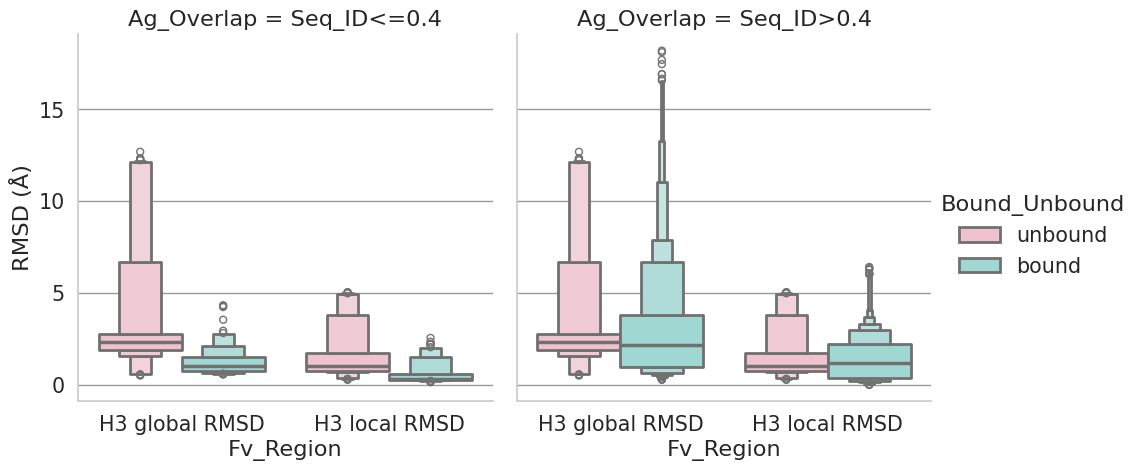

In [ ]:
sns.set_style("whitegrid",{"grid.color":"0.6"})
g = sns.catplot(data=nb_brokenup.sort_values(by=['Bound_Unbound'],ascending=False),\
                 x='Fv_Region',y='RMSD (Å)',hue='Bound_Unbound',col_order=['Seq_ID<=0.4','Seq_ID>0.4'],col='Ag_Overlap',palette=pastel_palette[:2],linewidth=linewidth,legend=True,kind='boxen')
# g.ylim=((0,10))
# # g.set(ylim=g.axes.get_ylim()[::-1])
# g.axhline(y=1.0,ls='--',color='gray')
# g.set(xlabel=None)
sns.set(font_scale=1.35)
# for spine in g.spines.values():
#     spine.set_linewidth(1)
#     spine.set_color('black')

In [18]:
nb_sabdab[nb_sabdab['pdb'].isin(x.split('_')[0] for x in data_df[(~data_df['PDB_short'].isin(diffag_nbs))].PDB_short.unique().tolist())].value_counts(subset=['antigen_name'])

antigen_name                                                                     
spike glycoprotein                                                                   32
spike protein s1                                                                     18
synaptotagmin-1                                                                       8
cftr inhibitory factor                                                                6
fragilysin                                                                            4
gasdermin-d                                                                           4
cystinosin homolog                                                                    4
equilibrative nucleoside/nucleobase transporter                                       2
hyaluronan synthase                                                                   2
capsid protein vp1                                                                    2
activity-regulated cytoskeleton-associ

In [13]:
spike_nbs = nb_sabdab[(nb_sabdab['pdb'].isin(x.split('_')[0] for x in data_df[(~data_df['PDB_short'].isin(diffag_nbs))].PDB_short.unique().tolist()))&(nb_sabdab['antigen_name'].isin(['spike glycoprotein','spike protein s1']))].pdb.unique().tolist()

In [14]:
nb_brokenup.head()

,Ag_Overlap,Model_Source,Protein_type,Bound_Unbound,Seed,Model,PDB_short,h3_len,h3_length,Fv_Region,RMSD (Å)
0,Seq_ID<=0.4,AF3,nanobody,unbound,1.0,3.0,7xl1_1.pdb,17,long,H3 global RMSD,11.925721
1,Seq_ID<=0.4,AF3,nanobody,unbound,1.0,0.0,7xl1_1.pdb,17,long,H3 global RMSD,12.138373
2,Seq_ID<=0.4,AF3,nanobody,unbound,1.0,2.0,7xl1_1.pdb,17,long,H3 global RMSD,12.315085
3,Seq_ID<=0.4,AF3,nanobody,unbound,1.0,4.0,7xl1_1.pdb,17,long,H3 global RMSD,12.683690
4,Seq_ID<=0.4,AF3,nanobody,unbound,1.0,1.0,7xl1_1.pdb,17,long,H3 global RMSD,12.225099


In [42]:
sns.set_style("whitegrid",{"grid.color":"0.6"})
def pdbshortisin(df,pdblist):
    pdbs = []
    for x in pdblist: 
        pdbs.append(df[df['PDB_short'].str.contains(x)])
    return pd.concat(pdbs)


In [ ]:

# g = sns.catplot(data=nb_brokenup.sort_values(by=['Bound_Unbound'],ascending=False),\
#                  x='Fv_Region',y='RMSD (Å)',hue='Bound_Unbound',col='Ag_Overlap',palette=pastel_palette[:2],linewidth=linewidth,legend=True,kind='boxen')
# pdbshortisin(nb_brokenup.sort_values(by=['Bound_Unbound']),nb_sabdab[(nb_sabdab['pdb'].isin(x.split('_')[0] for x in data_df[(~data_df['PDB_short'].isin(diffag_nbs))].PDB_short.unique().tolist()))&(nb_sabdab['antigen_name'].isin(['spike glycoprotein','spike protein s1']))].pdb.unique().tolist())
g = sns.catplot(data=pd.concat([pdbshortisin(nb_brokenup.sort_values(by=['Bound_Unbound']),spike_nbs),data_df[(data_df['Bound_Unbound']=='unbound')]]),\
                 x='Fv_Region',y='RMSD (Å)',hue='Bound_Unbound',palette=pastel_palette[:2],linewidth=linewidth,legend=True,kind='boxen')
# g.ylim=((0,10))
# # g.set(ylim=g.axes.get_ylim()[::-1])
# g.axhline(y=1.0,ls='--',color='gray')
# g.set(xlabel=None)
# sns.set(font_scale=1.35)
# for spine in g.spines.values():
#     spine.set_linewidth(1)
#     spine.set_color('black')

In [56]:
nb_ag_analysisdf = pd.concat([data_df[(data_df['PDB_short'].isin(diffag_nbs))|(data_df['Bound_Unbound']=='unbound')],\
                              pd.concat([pdbshortisin(nb_brokenup.sort_values(by=['Bound_Unbound']),spike_nbs),data_df[(data_df['Bound_Unbound']=='unbound')]]).drop(columns=['Ag_Overlap']), \
                              pdbshortisNOTin(nb_brokenup.sort_values(by=['Bound_Unbound']),spike_nbs).drop(columns=['Ag_Overlap'])],keys=['Seq_ID<=0.4','Seq_ID>0.4 (Spike Protein)','Seq_ID>0.4']).reset_index().drop(columns=['level_1']).rename(columns={'level_0':"Ag_Overlap"})

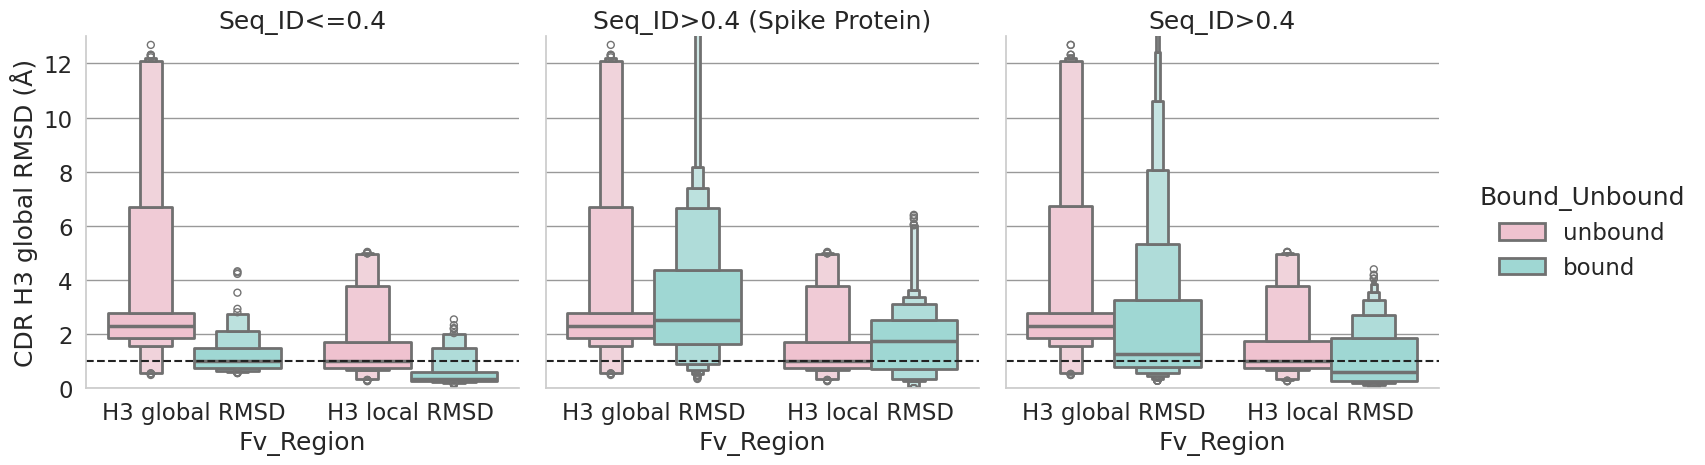

In [63]:
sns.set_style("whitegrid",{"grid.color":"0.6"})
# plt.figure(figsize = (9,9))
ax = sns.catplot(data=nb_ag_analysisdf,\
                 x='Fv_Region',y='RMSD (Å)',hue='Bound_Unbound',hue_order=['unbound','bound'],col='Ag_Overlap',palette=pastel_palette[:2],linewidth=linewidth,legend=True,kind='boxen')
sns.set(font_scale=1.5)
ax.set(ylim=(0, 13),ylabel='CDR H3 global RMSD (Å)')
ax.set_titles(col_template="{col_name}")
ax.refline(y=1.0,ls='--',color='#222222')
plt.savefig(f"{filepath}Nb_ag_overlap_bub_experiment.svg",format='svg',dpi=700,transparent=True,bbox_inches='tight')

In [89]:
ptype = 'nanobody'
diffag_nb_df = nb_ag_analysisdf[(nb_ag_analysisdf['Ag_Overlap']=='Seq_ID<=0.4')]
unbound_global_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='unbound')&(diffag_nb_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
bound_global_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='bound')&(diffag_nb_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} global for Seq_ID<=0.4 p-val: {mannwhitneyu(unbound_global_diffagnb,bound_global_diffagnb)[1]}")

nanobody global for Seq_ID<=0.4 p-val: 1.5979351929707403e-15


In [90]:
ptype = 'nanobody'
diffag_nb_df = nb_ag_analysisdf[(nb_ag_analysisdf['Ag_Overlap']=='Seq_ID<=0.4')]
unbound_local_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='unbound')&(diffag_nb_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
bound_local_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='bound')&(diffag_nb_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} local for Seq_ID<=0.4 p-val: {mannwhitneyu(unbound_local_diffagnb,bound_local_diffagnb)[1]}")

nanobody local for Seq_ID<=0.4 p-val: 2.542727337848909e-15


In [91]:
ptype = 'nanobody'
diffag_nb_df = nb_ag_analysisdf[(nb_ag_analysisdf['Ag_Overlap']=='Seq_ID>0.4 (Spike Protein)')]
unbound_global_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='unbound')&(diffag_nb_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
bound_global_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='bound')&(diffag_nb_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} global for Seq_ID>0.4 (Spike Protein) p-val: {mannwhitneyu(unbound_global_diffagnb,bound_global_diffagnb)[1]}")

nanobody global for Seq_ID>0.4 (Spike Protein) p-val: 0.14461365965158093


In [92]:
ptype = 'nanobody'
diffag_nb_df = nb_ag_analysisdf[(nb_ag_analysisdf['Ag_Overlap']=='Seq_ID>0.4 (Spike Protein)')]
unbound_local_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='unbound')&(diffag_nb_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
bound_local_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='bound')&(diffag_nb_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} local for Seq_ID>0.4 (Spike Protein) p-val: {mannwhitneyu(unbound_local_diffagnb,bound_local_diffagnb)[1]}")

nanobody local for Seq_ID>0.4 (Spike Protein) p-val: 0.008447721080654164


In [93]:
ptype = 'nanobody'
diffag_nb_df = nb_ag_analysisdf[(nb_ag_analysisdf['Ag_Overlap']=='Seq_ID>0.4')]
unbound_global_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='unbound')&(diffag_nb_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
bound_global_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='bound')&(diffag_nb_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} global for Seq_ID>0.4 p-val: {mannwhitneyu(unbound_global_diffagnb,bound_global_diffagnb)[1]}")

nanobody global for Seq_ID>0.4 p-val: 1.0765544947030757e-11


In [94]:
ptype = 'nanobody'
diffag_nb_df = nb_ag_analysisdf[(nb_ag_analysisdf['Ag_Overlap']=='Seq_ID>0.4')]
unbound_local_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='unbound')&(diffag_nb_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
bound_local_diffagnb = diffag_nb_df[(diffag_nb_df['Bound_Unbound']=='bound')&(diffag_nb_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} local for Seq_ID>0.4 p-val: {mannwhitneyu(unbound_local_diffagnb,bound_local_diffagnb)[1]}")

nanobody local for Seq_ID>0.4 p-val: 9.659907037499494e-11


### Abs

In [30]:
data_df=melted_AF2_v_AF3[(melted_AF2_v_AF3['Model_Source']=='AF3')\
                 &(melted_AF2_v_AF3['Protein_type']=='antibody') & ((melted_AF2_v_AF3['Fv_Region'].str.contains('H3'))|(melted_AF2_v_AF3['Fv_Region'].str.contains('h3')))].dropna(subset=['RMSD (Å)'])
data_df = data_df[data_df['PDB_short'].isin(final_abs)]
data_df['RMSD (Å)']=data_df['RMSD (Å)'].astype('float')
data_df=data_df.replace({"Fv_Region":{"h3_rms":"H3 global RMSD"}})
data_df=data_df.replace({"Fv_Region":{"H3_local_RMSD":"H3 local RMSD"}})
data_df.head()

,Model_Source,Protein_type,Bound_Unbound,Seed,Model,PDB_short,h3_len,h3_length,Fv_Region,RMSD (Å)
13768,AF3,antibody,bound,2.0,2.0,7wog_0.pdb,15,medium,H3 global RMSD,3.948227
13769,AF3,antibody,bound,2.0,1.0,7wog_0.pdb,15,medium,H3 global RMSD,2.160832
13770,AF3,antibody,bound,2.0,4.0,7wog_0.pdb,15,medium,H3 global RMSD,4.526896
13771,AF3,antibody,bound,2.0,3.0,7wog_0.pdb,15,medium,H3 global RMSD,2.272635
13772,AF3,antibody,bound,2.0,0.0,7wog_0.pdb,15,medium,H3 global RMSD,2.374370


In [37]:
diffag_abs = ['7yru_0.pdb', '8j7t_0.pdb', '8f6l_0.pdb', '8f6o_0.pdb']
ab_brokenup = pd.concat([data_df[(data_df['PDB_short'].isin(diffag_abs))|(data_df['Bound_Unbound']=='unbound')],\
    data_df[(~data_df['PDB_short'].isin(diffag_abs))|(data_df['Bound_Unbound']=='unbound')]],keys=['Seq_ID<=0.4','Seq_ID>0.4']).reset_index().drop(columns=['level_1']).rename(columns={'level_0':"Ag_Overlap"})

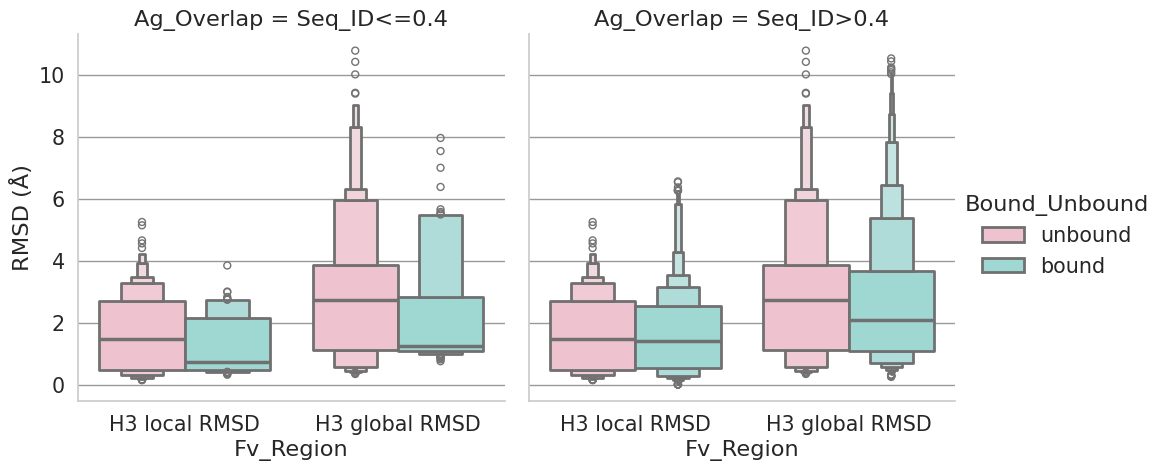

In [39]:
sns.set_style("whitegrid",{"grid.color":"0.6"})
g = sns.catplot(data=ab_brokenup.sort_values(by=['Bound_Unbound'],ascending=False),\
                 x='Fv_Region',y='RMSD (Å)',hue='Bound_Unbound',col_order=['Seq_ID<=0.4','Seq_ID>0.4'],col='Ag_Overlap',palette=pastel_palette[:2],linewidth=linewidth,legend=True,kind='boxen')
# g.ylim=((0,10))
# # g.set(ylim=g.axes.get_ylim()[::-1])
# g.axhline(y=1.0,ls='--',color='gray')
# g.set(xlabel=None)
sns.set(font_scale=1.35)
# for spine in g.spines.values():
#     spine.set_linewidth(1)
#     spine.set_color('black')

In [40]:
ab_sabdab[ab_sabdab['pdb'].isin(x.split('_')[0] for x in data_df[(~data_df['PDB_short'].isin(diffag_abs))].PDB_short.unique().tolist())].value_counts(subset=['antigen_name'])

antigen_name                                                                             
spike glycoprotein                                                                           42
spike protein s1                                                                             37
spike protein s2'                                                                            16
fusion glycoprotein f0                                                                       15
neuraminidase                                                                                 9
surface glycoprotein                                                                          5
long neurotoxin 1                                                                             5
circumsporozoite protein npdp peptide                                                         4
il17rb protein                                                                                4
interleukin-17a                               

In [41]:
spike_abs = ab_sabdab[(ab_sabdab['pdb'].isin(x.split('_')[0] for x in data_df[(~data_df['PDB_short'].isin(diffag_abs))].PDB_short.unique().tolist()))&(ab_sabdab['antigen_name'].isin(['spike glycoprotein','spike protein s1','spike protein s2','sars-cov-2 fusion peptide','pegylated spike s2 peptide','sars-cov-2 s fusion peptide','spike protein s2 fusion peptide']))].pdb.unique().tolist()

In [44]:
ab_ag_analysisdf = pd.concat([data_df[(data_df['PDB_short'].isin(diffag_abs))|(data_df['Bound_Unbound']=='unbound')],\
                              pd.concat([pdbshortisin(ab_brokenup.sort_values(by=['Bound_Unbound']),spike_abs),data_df[(data_df['Bound_Unbound']=='unbound')]]).drop(columns=['Ag_Overlap']), \
                              pdbshortisNOTin(ab_brokenup.sort_values(by=['Bound_Unbound']),spike_abs).drop(columns=['Ag_Overlap'])],keys=['Seq_ID<=0.4','Seq_ID>0.4 (Spike Protein)','Seq_ID>0.4']).reset_index().drop(columns=['level_1']).rename(columns={'level_0':"Ag_Overlap"})

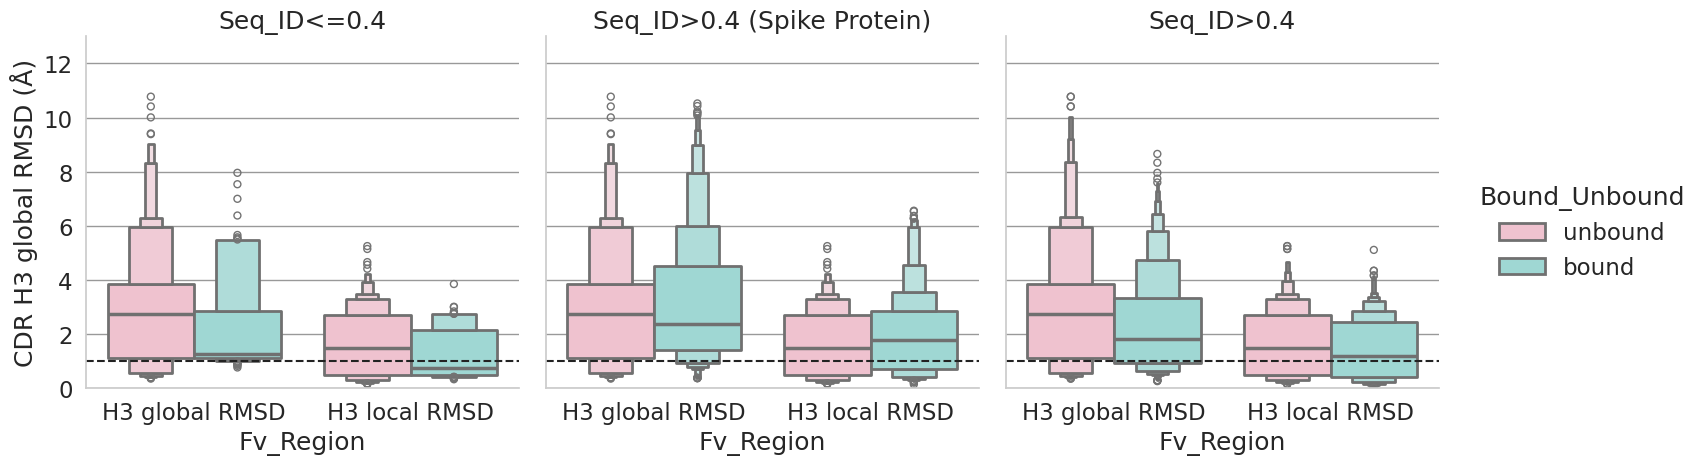

In [106]:
sns.set_style("whitegrid",{"grid.color":"0.6"})
# plt.figure(figsize = (9,9))
ax = sns.catplot(data=ab_ag_analysisdf,\
                 x='Fv_Region',y='RMSD (Å)',hue='Bound_Unbound',hue_order=['unbound','bound'],col='Ag_Overlap',palette=pastel_palette[:2],linewidth=linewidth,legend=True,kind='boxen')
sns.set(font_scale=1.5)
ax.set(ylim=(0, 13),ylabel='CDR H3 global RMSD (Å)')
ax.set_titles(col_template="{col_name}")
ax.refline(y=1.0,ls='--',color='#222222')
plt.savefig(f"{filepath}Ab_ag_overlap_bub_experiment.svg",format='svg',dpi=700,transparent=True,bbox_inches='tight')

In [110]:
ptype = 'antibody'
diffag_ab_df = ab_ag_analysisdf[(ab_ag_analysisdf['Ag_Overlap']=='Seq_ID<=0.4')]
unbound_global_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='unbound')&(diffag_ab_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
bound_global_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='bound')&(diffag_ab_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} global for Seq_ID<=0.4 p-val: {mannwhitneyu(unbound_global_diffagab,bound_global_diffagab)[1]}")

antibody global for Seq_ID<=0.4 p-val: 0.0315137135692884


In [111]:
ptype = 'antibody'
diffag_ab_df = ab_ag_analysisdf[(ab_ag_analysisdf['Ag_Overlap']=='Seq_ID<=0.4')]
unbound_local_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='unbound')&(diffag_ab_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
bound_local_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='bound')&(diffag_ab_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} local for Seq_ID<=0.4 p-val: {mannwhitneyu(unbound_local_diffagab,bound_local_diffagab)[1]}")

antibody local for Seq_ID<=0.4 p-val: 0.07649748597254122


In [112]:
ptype = 'antibody'
diffag_ab_df = ab_ag_analysisdf[(ab_ag_analysisdf['Ag_Overlap']=='Seq_ID>0.4 (Spike Protein)')]
unbound_global_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='unbound')&(diffag_ab_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
bound_global_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='bound')&(diffag_ab_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} global for Seq_ID>0.4 p-val: {mannwhitneyu(unbound_global_diffagab,bound_global_diffagab)[1]}")

antibody global for Seq_ID>0.4 p-val: 0.5908893986648988


In [113]:
ptype = 'antibody'
diffag_ab_df = ab_ag_analysisdf[(ab_ag_analysisdf['Ag_Overlap']=='Seq_ID>0.4 (Spike Protein)')]
unbound_local_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='unbound')&(diffag_ab_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
bound_local_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='bound')&(diffag_ab_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} local for Seq_ID>0.4 (Spike Protein) p-val: {mannwhitneyu(unbound_local_diffagab,bound_local_diffagab)[1]}")

antibody local for Seq_ID>0.4 (Spike Protein) p-val: 0.00777119854441561


In [114]:
ptype = 'antibody'
diffag_ab_df = ab_ag_analysisdf[(ab_ag_analysisdf['Ag_Overlap']=='Seq_ID>0.4')]
unbound_global_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='unbound')&(diffag_ab_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
bound_global_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='bound')&(diffag_ab_df['Fv_Region']=='H3 global RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} global for Seq_ID>0.4 p-val: {mannwhitneyu(unbound_global_diffagab,bound_global_diffagab)[1]}")

antibody global for Seq_ID>0.4 p-val: 2.327518705637506e-07


In [115]:
ptype = 'antibody'
diffag_ab_df = ab_ag_analysisdf[(ab_ag_analysisdf['Ag_Overlap']=='Seq_ID>0.4')]
unbound_local_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='unbound')&(diffag_ab_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
bound_local_diffagab = diffag_ab_df[(diffag_ab_df['Bound_Unbound']=='bound')&(diffag_ab_df['Fv_Region']=='H3 local RMSD')]['RMSD (Å)'].tolist()
print(f"{ptype} local for Seq_ID>0.4 p-val: {mannwhitneyu(unbound_local_diffagab,bound_local_diffagab)[1]}")

antibody local for Seq_ID>0.4 p-val: 0.0001581509154712526


## Panel 5: Scoring Optimization

In [66]:
fulldelgb_df = pd.read_csv(f"results/round_6/datafiles/top_ranked_renum_fv_all_bindingenergies.csv").drop(columns=['Unnamed: 0'])
fulldelgb_df['Bound_Unbound'] = ['bound']*fulldelgb_df.shape[0]
fulldelgb_df['PDB_short']= ["_".join(x.split("_")[-5:-3])+'.pdb' if 'bound' not in x else "_".join(x.split("_")[-6:-4])+'.pdb' for x in fulldelgb_df.PDB.tolist()]
fulldelgb_df['Seed']= [int(x.split("_")[-3].split('d')[-1]) if 'bound' not in x else int(x.split("_")[-4].split('d')[-1]) for x in fulldelgb_df.PDB.tolist()]
fulldelgb_df['Model']= [int(x.split("_")[-1].split(".")[0]) for x in fulldelgb_df.PDB.tolist()]
fulldelgb_df

,PDB,del_G_B,Protein_type,Bound_Unbound,PDB_short,Seed,Model
0,renum_fv_fold_7wog_0_seed1_model_3.pdb,18.744175,antibody,bound,7wog_0.pdb,1,3
1,renum_fv_fold_7wg3_1_seed1_model_0.pdb,57.675197,antibody,bound,7wg3_1.pdb,1,0
2,renum_fv_fold_8ath_1_seed1_model_0.pdb,6.112339,antibody,bound,8ath_1.pdb,1,0
3,renum_fv_fold_8hp9_0_seed1_model_2.pdb,-78.321379,antibody,bound,8hp9_0.pdb,1,2
4,renum_fv_fold_8sgn_0_seed1_model_0.pdb,40.704204,antibody,bound,8sgn_0.pdb,1,0
...,...,...,...,...,...,...,...
183,renum_renamed_fold_7tpr_1_seed1_model_0.pdb,45.367333,nanobody,bound,7tpr_1.pdb,1,0
184,renum_renamed_fold_8emz_0_seed1_model_0.pdb,106.173977,nanobody,bound,8emz_0.pdb,1,0
185,renum_renamed_fold_7q6c_0_seed1_bound_model_0.pdb,35.049829,nanobody,bound,7q6c_0.pdb,1,0
186,renum_renamed_fold_8cxq_0_seed1_model_0.pdb,-36.906251,nanobody,bound,8cxq_0.pdb,1,0


In [67]:
vh_nb_rank_delgb = pd.read_csv("results/round_7/datafiles/vh_simnbs_GB.csv",index_col='Unnamed: 0')
vh_nb_rank_delgb['Bound_Unbound'] = ['bound']*vh_nb_rank_delgb.shape[0]
vh_nb_rank_delgb['PDB_short']= ["_".join(x.split("_")[-5:-3])+'.pdb' if 'bound' not in x else "_".join(x.split("_")[-6:-4])+'.pdb' for x in vh_nb_rank_delgb.PDB.tolist()]
vh_nb_rank_delgb['Seed']= [int(x.split("_")[-3].split('d')[-1]) if 'bound' not in x else int(x.split("_")[-4].split('d')[-1]) for x in vh_nb_rank_delgb.PDB.tolist()]
vh_nb_rank_delgb['Model']= [int(x.split("_")[-1].split(".")[0]) for x in vh_nb_rank_delgb.PDB.tolist()]
fulldelgb_df=pd.concat([fulldelgb_df,vh_nb_rank_delgb],ignore_index=True)
fulldelgb_df

,PDB,del_G_B,Protein_type,Bound_Unbound,PDB_short,Seed,Model
0,renum_fv_fold_7wog_0_seed1_model_3.pdb,18.744175,antibody,bound,7wog_0.pdb,1,3
1,renum_fv_fold_7wg3_1_seed1_model_0.pdb,57.675197,antibody,bound,7wg3_1.pdb,1,0
2,renum_fv_fold_8ath_1_seed1_model_0.pdb,6.112339,antibody,bound,8ath_1.pdb,1,0
3,renum_fv_fold_8hp9_0_seed1_model_2.pdb,-78.321379,antibody,bound,8hp9_0.pdb,1,2
4,renum_fv_fold_8sgn_0_seed1_model_0.pdb,40.704204,antibody,bound,8sgn_0.pdb,1,0
...,...,...,...,...,...,...,...
187,renum_renamed_fold_7zmm_0_seed1_model_1.pdb,-26.708163,nanobody,bound,7zmm_0.pdb,1,1
188,renum_stitched_renamed_fold_8cy7_2_seed1_model...,33.975431,nanobody,bound,8cy7_2.pdb,1,1
189,renum_stitched_renamed_fold_8di5_0_seed1_model...,211.447943,nanobody,bound,8di5_0.pdb,1,0
190,renum_stitched_renamed_fold_8q7s_4_seed_1_mode...,-6.430398,nanobody,bound,4_seed.pdb,1,0


In [68]:
relaxed_delgb_df = pd.read_csv(f"results/round_6/datafiles/topranked_renum_fv_all_RELAXEDbindingenergies.csv").drop(columns=['Unnamed: 0'])
relaxed_delgb_df['Bound_Unbound'] = ['bound']*relaxed_delgb_df.shape[0]
relaxed_delgb_df['PDB_short']= ["_".join(x.split("_")[-5:-3])+'.pdb'\
    if '7q6c_0' not in x else "_".join(x.split("_")[-6:-4])+'.pdb'\
          for x in relaxed_delgb_df.Pred_PDB.tolist()]
relaxed_delgb_df['Seed']= [int(x.split("_")[-3].split('d')[-1]) if 'bound' not in x else int(x.split("_")[-4].split('d')[-1]) for x in relaxed_delgb_df.Pred_PDB.tolist()]
relaxed_delgb_df['Model']= [int(x.split("_")[-1].split(".")[0]) for x in relaxed_delgb_df.Pred_PDB.tolist()]
relaxed_delgb_df = relaxed_delgb_df.rename(columns={"Pred_PDB":"Relaxed_PDB","Pred_Dir":"Relaxed_Dir"})
relaxed_delgb_df

,Relaxed_Dir,Relaxed_PDB,del_G_B,Protein_type,Bound_Unbound,PDB_short,Seed,Model
0,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_7wog_0_seed1_model_3.pdb,-71.713244,antibody,bound,7wog_0.pdb,1,3
1,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_7wg3_1_seed1_model_0.pdb,-58.685492,antibody,bound,7wg3_1.pdb,1,0
2,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_8ath_1_seed1_model_0.pdb,-77.933328,antibody,bound,8ath_1.pdb,1,0
3,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_8hp9_0_seed1_model_2.pdb,-85.054073,antibody,bound,8hp9_0.pdb,1,2
4,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_8sgn_0_seed1_model_0.pdb,-94.556164,antibody,bound,8sgn_0.pdb,1,0
...,...,...,...,...,...,...,...,...
183,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,overall_renum_renamed_fold_7tpr_1_seed1_model_...,-26.176384,nanobody,bound,7tpr_1.pdb,1,0
184,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,overall_renum_renamed_fold_8emz_0_seed1_model_...,-24.334845,nanobody,bound,8emz_0.pdb,1,0
185,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,overall_renum_renamed_fold_7q6c_0_seed1_bound_...,-29.346845,nanobody,bound,7q6c_0.pdb,1,0
186,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,overall_renum_renamed_fold_8cxq_0_seed1_model_...,-64.743206,nanobody,bound,8cxq_0.pdb,1,0


In [69]:
vh_nb_delgb_relaxed = pd.read_csv("results/round_7/datafiles/vh_simnbs_Relaxed_Gb.csv",index_col='Unnamed: 0')
vh_nb_delgb_relaxed=vh_nb_delgb_relaxed.rename(columns={'Pred_Dir':'Relaxed_Dir','Pred_PDB':"Relaxed_PDB"})
vh_nb_delgb_relaxed['Bound_Unbound'] = ['bound']*vh_nb_delgb_relaxed.shape[0]
vh_nb_delgb_relaxed['PDB_short']= ["_".join(x.split("_")[-5:-3])+'.pdb' if 'bound' not in x else "_".join(x.split("_")[-6:-4])+'.pdb' for x in vh_nb_delgb_relaxed.Relaxed_PDB.tolist()]
vh_nb_delgb_relaxed['Seed']= [int(x.split("_")[-3].split('d')[-1]) if 'bound' not in x else int(x.split("_")[-4].split('d')[-1]) for x in vh_nb_delgb_relaxed.Relaxed_PDB.tolist()]
vh_nb_delgb_relaxed['Model']= [int(x.split("_")[-1].split(".")[0]) for x in vh_nb_delgb_relaxed.Relaxed_PDB.tolist()]
relaxed_delgb_df=pd.concat([relaxed_delgb_df,vh_nb_delgb_relaxed],ignore_index=True)
relaxed_delgb_df

,Relaxed_Dir,Relaxed_PDB,del_G_B,Protein_type,Bound_Unbound,PDB_short,Seed,Model
0,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_7wog_0_seed1_model_3.pdb,-71.713244,antibody,bound,7wog_0.pdb,1,3
1,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_7wg3_1_seed1_model_0.pdb,-58.685492,antibody,bound,7wg3_1.pdb,1,0
2,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_8ath_1_seed1_model_0.pdb,-77.933328,antibody,bound,8ath_1.pdb,1,0
3,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_8hp9_0_seed1_model_2.pdb,-85.054073,antibody,bound,8hp9_0.pdb,1,2
4,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_8sgn_0_seed1_model_0.pdb,-94.556164,antibody,bound,8sgn_0.pdb,1,0
...,...,...,...,...,...,...,...,...
186,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,overall_renum_renamed_fold_8cxq_0_seed1_model_...,-64.743206,nanobody,bound,8cxq_0.pdb,1,0
187,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,overall_renum_renamed_fold_7zmm_0_seed1_model_...,-53.051841,nanobody,bound,7zmm_0.pdb,1,1
188,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,overall_renum_stitched_renamed_fold_8di5_0_see...,-45.875990,nanobody,bound,8di5_0.pdb,1,0
189,/home/ftalib1/scr4_jgray21/ftalib1/AF3_Benchma...,overall_renum_stitched_renamed_fold_8q7s_4_see...,-34.560313,nanobody,bound,4_seed.pdb,1,0


In [70]:
be_withothermetrics = final_af3_benchmark.merge(fulldelgb_df.rename(columns={"PDB":'AF3_PDB'}),on=['AF3_PDB','PDB_short','Protein_type','Seed','Model','Bound_Unbound']).drop_duplicates()
be_withothermetrics

,AF3_Dir,AF3_PDB,Bound_Unbound,Native_Dir,Native_PDB,H3_local_RMSD,ocd,frh_rms,h1_rms,h2_rms,...,I_pLDDT,DockQ_Classification,h3_len,h3_length,L3_plddt_arrays,Avg_L3_pLDDT,F1,Fnat,Rank,del_G_B
0,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8qrg_0_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8qrg_0.pdb,2.012609,1.412208,0.332826,0.632234,0.412164,...,81.565395,Incorrect,12.0,medium,NaN,NaN,NaN,NaN,NaN,136.244930
1,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_renamed_fold_8oud_0_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8oud_0.pdb,0.133549,0.000000,0.463190,1.531432,0.665184,...,64.759211,Incorrect,10.0,medium,NaN,NaN,NaN,NaN,NaN,85.355504
2,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_renamed_fold_8b8i_0_seed1_model_2.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8b8i_0.pdb,0.222188,0.000000,0.454705,0.554737,0.413732,...,95.879375,High,11.0,medium,NaN,NaN,NaN,NaN,NaN,-46.496881
3,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8tbq_1_seed1_model_2.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8tbq_1.pdb,1.685917,2.890520,0.289481,0.325972,0.420205,...,84.445286,Medium,15.0,medium,NaN,NaN,NaN,NaN,NaN,-22.657866
4,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_renamed_fold_8qf5_0_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8qf5_0.pdb,3.622599,0.000000,0.994122,1.990907,0.604531,...,70.227532,Incorrect,12.0,medium,NaN,NaN,NaN,NaN,NaN,-13.674447
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_renamed_fold_7x7e_0_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_7x7e_0.pdb,2.658100,0.000000,0.369470,0.829245,0.426686,...,71.348030,Incorrect,22.0,long,NaN,NaN,NaN,NaN,NaN,-12.646023
104,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_renamed_fold_7sp8_0_seed1_model_1.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_7sp8_0.pdb,0.605910,0.000000,0.695349,0.976430,1.045859,...,81.920541,Medium,18.0,long,NaN,NaN,NaN,NaN,NaN,-29.915786
105,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fv_fold_7tow_0_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7tow_0.pdb,6.137579,2.230517,0.191284,0.422303,0.395441,...,71.854167,Acceptable,25.0,long,NaN,NaN,NaN,NaN,NaN,40.710988
106,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fv_fold_7tow_1_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7tow_1.pdb,6.175914,1.761778,0.203926,0.307254,0.391685,...,61.288704,Incorrect,25.0,long,NaN,NaN,NaN,NaN,NaN,23.403804


In [71]:
relaxbe_withothermetrics = final_af3_benchmark.merge(relaxed_delgb_df,on=['PDB_short','Seed','Model','Protein_type','Bound_Unbound']).drop_duplicates()
relaxbe_withothermetrics

,AF3_Dir,AF3_PDB,Bound_Unbound,Native_Dir,Native_PDB,H3_local_RMSD,ocd,frh_rms,h1_rms,h2_rms,...,h3_len,h3_length,L3_plddt_arrays,Avg_L3_pLDDT,F1,Fnat,Rank,Relaxed_Dir,Relaxed_PDB,del_G_B
0,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8qrg_0_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8qrg_0.pdb,2.012609,1.412208,0.332826,0.632234,0.412164,...,12.0,medium,NaN,NaN,NaN,NaN,NaN,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_8qrg_0_seed1_model_0.pdb,-80.875303
1,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_renamed_fold_8oud_0_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8oud_0.pdb,0.133549,0.000000,0.463190,1.531432,0.665184,...,10.0,medium,NaN,NaN,NaN,NaN,NaN,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,overall_renum_renamed_fold_8oud_0_seed1_model_...,-60.400844
2,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_renamed_fold_8b8i_0_seed1_model_2.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8b8i_0.pdb,0.222188,0.000000,0.454705,0.554737,0.413732,...,11.0,medium,NaN,NaN,NaN,NaN,NaN,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_renamed_fold_8b8i_0_seed1_model_...,-54.581129
3,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_fv_fold_8tbq_1_seed1_model_2.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_8tbq_1.pdb,1.685917,2.890520,0.289481,0.325972,0.420205,...,15.0,medium,NaN,NaN,NaN,NaN,NaN,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_fv_fold_8tbq_1_seed1_model_2.pdb,-63.688342
4,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,renum_renamed_fold_8qf5_0_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_8qf5_0.pdb,3.622599,0.000000,0.994122,1.990907,0.604531,...,12.0,medium,NaN,NaN,NaN,NaN,NaN,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/so...,overall_renum_renamed_fold_8qf5_0_seed1_model_...,-73.239208
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_renamed_fold_7x7e_0_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_7x7e_0.pdb,2.658100,0.000000,0.369470,0.829245,0.426686,...,22.0,long,NaN,NaN,NaN,NaN,NaN,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,overall_renum_renamed_fold_7x7e_0_seed1_model_...,-42.444817
102,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_renamed_fold_7sp8_0_seed1_model_1.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_7sp8_0.pdb,0.605910,0.000000,0.695349,0.976430,1.045859,...,18.0,long,NaN,NaN,NaN,NaN,NaN,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,overall_renum_renamed_fold_7sp8_0_seed1_model_...,-48.098932
103,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fv_fold_7tow_0_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7tow_0.pdb,6.137579,2.230517,0.191284,0.422303,0.395441,...,25.0,long,NaN,NaN,NaN,NaN,NaN,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,overall_renum_fv_fold_7tow_0_seed1_model_0.pdb,-70.648875
104,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,renum_fv_fold_7tow_1_seed1_model_0.pdb,bound,/scratch4/jgray21/ftalib1/AF3_Benchmark/New_AF...,renum_fv_7tow_1.pdb,6.175914,1.761778,0.203926,0.307254,0.391685,...,25.0,long,NaN,NaN,NaN,NaN,NaN,/scratch4/jgray21/ftalib1/AF3_Benchmark/AF3/ex...,overall_renum_fv_fold_7tow_1_seed1_model_0.pdb,-93.946659


In [23]:
def range_checker(metric2_start,metric2_end):
    if metric2_start == metric2_start:
        metric2_start = int(round(float(metric2_start)))
        pass_1 = False
    else:
        pass_1 = True
    if metric2_end == metric2_end:
        metric2_end = int(round(float(metric2_end)))
        pass_2 = False
    else:
        pass_2 = True
    if True in [pass_1,pass_2]:
        return False, False
    else:
        return metric2_start,metric2_end

In [24]:
def fpr_range_maker(metric1,df,ptype,metric2,i):
    if metric1!='del_G_B':
        #checking tn ranges
        metric2_start = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df['DockQ']<0.23)][metric2].min()
        metric2_end = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df['DockQ']<0.23)][metric2].max()
        tn_start,tn_end = range_checker(metric2_start,metric2_end)
        #checking fp ranges
        metric2_start = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df['DockQ']<0.23)][metric2].min()
        metric2_end = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df['DockQ']<0.23)][metric2].max()
        fp_start,fp_end = range_checker(metric2_start,metric2_end)
        return [[tn_start,tn_end],[fp_start,fp_end]]
    else:
        #checking tn ranges
        metric2_start = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df['DockQ']<0.23)][metric2].min()
        metric2_end = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df['DockQ']<0.23)][metric2].max()
        tn_start,tn_end = range_checker(metric2_start,metric2_end)
        #checking fp ranges
        metric2_start = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df['DockQ']<0.23)][metric2].min()
        metric2_end = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df['DockQ']<0.23)][metric2].max()
        fp_start,fp_end = range_checker(metric2_start,metric2_end)
        return [[tn_start,tn_end],[fp_start,fp_end]]

def tpr_range_maker(metric1,df,ptype,metric2,i):
    if metric1!='del_G_B':
        #checking fn ranges
        metric2_start = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df['DockQ']>=0.23)][metric2].min()
        metric2_end = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df['DockQ']>=0.23)][metric2].max()
        fn_start, fn_end = range_checker(metric2_start,metric2_end)
        #checking tp ranges
        metric2_start = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df['DockQ']>=0.23)][metric2].min()
        metric2_end = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df['DockQ']>=0.23)][metric2].max()
        tp_start, tp_end = range_checker(metric2_start,metric2_end)
    else:
        #checking fn ranges
        metric2_start = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df['DockQ']>=0.23)][metric2].min()
        metric2_end = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df['DockQ']>=0.23)][metric2].max()
        #checking tp ranges
        metric2_start = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df['DockQ']>=0.23)][metric2].min()
        metric2_end = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df['DockQ']>=0.23)][metric2].max()
        tp_start, tp_end = range_checker(metric2_start,metric2_end)
    return [[fn_start,fn_end],[tp_start,tp_end]]
    

In [25]:
def tpr_calc(df,ptype,metric,threshold_range):
    tprs = []
    for i in threshold_range:
        tp = df[(df['Protein_type']==ptype)&(df[metric]>=i)&(df['DockQ']>=0.23)].shape[0]
        fn = df[(df['Protein_type']==ptype)&(df[metric]<i)&(df['DockQ']>=0.23)].shape[0]
        tpr = tp / (tp+fn)
        tprs.append(tpr)
    return tprs

def fpr_calc(df,ptype,metric,threshold_range):
    fprs = []
    for i in threshold_range:
        fp = df[(df['Protein_type']==ptype)&(df[metric]>=i)&(df['DockQ']<0.23)].shape[0]
        tn = df[(df['Protein_type']==ptype)&(df[metric]<i)&(df['DockQ']<0.23)].shape[0]
        fpr = fp / (fp+tn)
        fprs.append(fpr)
    return fprs

def tpr_energies_calc(df,ptype,metric,threshold_range):
    tprs = []
    for i in threshold_range:
        tp = df[(df['Protein_type']==ptype)&(df[metric]<=i)&(df['DockQ']>=0.23)].shape[0]
        fn = df[(df['Protein_type']==ptype)&(df[metric]>i)&(df['DockQ']>=0.23)].shape[0]
        tpr = tp / (tp+fn)
        tprs.append(tpr)
    return tprs

def fpr_energies_calc(df,ptype,metric,threshold_range):
    fprs = []
    for i in threshold_range:
        fp = df[(df['Protein_type']==ptype)&(df[metric]<=i)&(df['DockQ']<0.23)].shape[0]
        tn = df[(df['Protein_type']==ptype)&(df[metric]>i)&(df['DockQ']<0.23)].shape[0]
        fpr = fp / (fp+tn)
        fprs.append(fpr)
    return fprs

def double_metric_tpr_old(df,ptype,metric1,metric1_cutoff,metric2,metric2_range):
    tprs = []
    for i in metric2_range:
        if metric2!='del_G_B':
            tp = df[(df['Protein_type']==ptype)&(df[metric1]>metric1_cutoff)&(df[metric2]>=i)&(df['DockQ']>=0.23)].shape[0]
            fn = df[(df['Protein_type']==ptype)&(df[metric1]<metric1_cutoff)&(df[metric2]<i)&(df['DockQ']>=0.23)].shape[0]
            tpr = tp / (tp+fn)
            tprs.append(tpr)
        else:
            tp = df[(df['Protein_type']==ptype)&(df[metric1]>metric1_cutoff)&(df[metric2]<i)&(df['DockQ']>=0.23)].shape[0]
            fn = df[(df['Protein_type']==ptype)&(df[metric1]<metric1_cutoff)&(df[metric2]>=i)&(df['DockQ']>=0.23)].shape[0]
            tpr = tp / (tp+fn)
            tprs.append(tpr)
    return tprs

def double_metric_tpr(df,ptype,metric1,metric1_range,metric2,metric2_range):
    tprs = []
    metric1_val=[]
    metric2_val=[]
    for i in metric1_range:
        tn_fp_startends = tpr_range_maker(metric1,df,ptype,metric2,i)
        # print(metric2_start,metric2_end)
        if [[False,False],[False,False]]== tn_fp_startends:
            pass
        elif False in tn_fp_startends[0]:
            range_to_use = 1
        elif False in tn_fp_startends[1]:
            range_to_use = 0
        else:
            range_to_use = [0 if np.absolute(tn_fp_startends[0][1]-tn_fp_startends[0][0])>=np.absolute(tn_fp_startends[1][1]-tn_fp_startends[1][0]) else 1][0]
            if metric2!='del_G_B':
                metric2_range = list(np.array(range(tn_fp_startends[range_to_use][0],tn_fp_startends[range_to_use][1])))
            else:
                metric2_range = list(np.array(range(tn_fp_startends[range_to_use][0],tn_fp_startends[range_to_use][1])))
            for j in metric2_range:
                if metric1=='del_G_B':
                    if metric2!='del_G_B':
                        tp = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df[metric2]>=j)&(df['DockQ']>=0.23)].shape[0]
                        fn = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df[metric2]<j)&(df['DockQ']>=0.23)].shape[0]
                        tpr = tp / (tp+fn)
                        metric1_val.append(i)
                        metric2_val.append(j)
                        tprs.append(tpr)
                    else:
                        tp = df[(df['Protein_type']==ptype)&(df[metric1]<i)&(df[metric2]<j)&(df['DockQ']>=0.23)].shape[0]
                        fn = df[(df['Protein_type']==ptype)&(df[metric1]>=i)&(df[metric2]>=j)&(df['DockQ']>=0.23)].shape[0]
                        # print(f"{i}")
                        # print(f"{j}")
                        # print(f"tp: {tp}")
                        # print(f"fn: {fn}")
                        tpr = tp / (tp+fn)
                        metric1_val.append(i)
                        metric2_val.append(j)
                        tprs.append(tpr)
                else:
                    if metric2!='del_G_B':
                        tp = df[(df['Protein_type']==ptype)&(df[metric1]>=i)&(df[metric2]>=j)&(df['DockQ']>=0.23)].shape[0]
                        fn = df[(df['Protein_type']==ptype)&(df[metric1]<i)&(df[metric2]<j)&(df['DockQ']>=0.23)].shape[0]
                        tpr = tp / (tp+fn)
                        metric1_val.append(i)
                        metric2_val.append(j)
                        tprs.append(tpr)
                    else:
                        # print(f'metric1: {metric1}, value: {i}')
                        # print(f'metric2: {metric2}, value: {j}')
                        tp = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df[metric2]<j)&(df['DockQ']>=0.23)].shape[0]
                        fn = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df[metric2]>=j)&(df['DockQ']>=0.23)].shape[0]
                        # print(f"{i}")
                        # print(f"{j}")
                        # print(f"tp: {tp}")
                        # print(f"fn: {fn}")
                        tpr = tp / (tp+fn)
                        metric1_val.append(i)
                        metric2_val.append(j)
                        tprs.append(tpr)
    return metric1_val, metric2_val, tprs

def double_metric_fpr(df,ptype,metric1,metric1_range,metric2,metric2_range):
    print(metric2_range)
    fprs = []
    metric1_val=[]
    metric2_val=[]
    for i in metric1_range:
        tn_fp_startends = fpr_range_maker(metric1,df,ptype,metric2,i)
        # print(metric2_start,metric2_end)
        if [[False,False],[False,False]]== tn_fp_startends:
            pass
        elif False in tn_fp_startends[0]:
            range_to_use = 1
        elif False in tn_fp_startends[1]:
            range_to_use = 0
        else:
            range_to_use = [0 if np.absolute(tn_fp_startends[0][1]-tn_fp_startends[0][0])>=np.absolute(tn_fp_startends[1][1]-tn_fp_startends[1][0]) else 1][0]
        if metric2!='del_G_B':
            fpr_min = np.maximum(metric2_range[0],tn_fp_startends[range_to_use][0])
            fpr_max = np.minimum(metric2_range[-1],tn_fp_startends[range_to_use][1])
            metric2_range_usable = [x for x in metric2_range if (x>fpr_min and x<fpr_max)]
        else:
            fpr_min = np.maximum(metric2_range[0],tn_fp_startends[range_to_use][0])
            fpr_max = np.minimum(metric2_range[-1],tn_fp_startends[range_to_use][1])
            metric2_range_usable = [x for x in metric2_range if (x>fpr_min and x<fpr_max)]
        for j in metric2_range_usable:
            if metric1=='del_G_B':
                if metric2!='del_G_B':
                    fp = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df[metric2]>=j)&(df['DockQ']<0.23)].shape[0]
                    tn = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df[metric2]<j)&(df['DockQ']<0.23)].shape[0]
                    # print(f"{i}")
                    # print(f"{j}")
                    # print(f"tp: {fp}")
                    # print(f"fn: {tn}")
                    fpr = fp / (fp+tn)
                    metric1_val.append(i)
                    metric2_val.append(j)
                    fprs.append(fpr)
                else:
                    fp = df[(df['Protein_type']==ptype)&(df[metric1]<i)&(df[metric2]<j)&(df['DockQ']<0.23)].shape[0]
                    tn = df[(df['Protein_type']==ptype)&(df[metric1]>=i)&(df[metric2]>=j)&(df['DockQ']<0.23)].shape[0]
                    # print(f"{i}")
                    # print(f"{j}")
                    # print(f"tp: {fp}")
                    # print(f"fn: {tn}")
                    fpr = fp / (fp+tn)
                    metric1_val.append(i)
                    metric2_val.append(j)
                    fprs.append(fpr)
            else:
                if metric2!='del_G_B':
                    # print(f'metric1: {metric1}, value: {i}')
                    # print(f'metric2: {metric2}, value: {j}')
                    fp = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df[metric2]>j)&(df['DockQ']<0.23)].shape[0]
                    tn = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df[metric2]<=j)&(df['DockQ']<0.23)].shape[0]
                    # print(f"{i}")
                    # print(f"{j}")
                    # print(f"tp: {fp}")
                    # print(f"fn: {tn}")
                    fpr = fp / (fp+tn)
                    metric1_val.append(i)
                    metric2_val.append(j)
                    fprs.append(fpr)
                else:
                    fp = df[(df['Protein_type']==ptype)&(df[metric1]>i)&(df[metric2]<j)&(df['DockQ']<0.23)].shape[0]
                    tn = df[(df['Protein_type']==ptype)&(df[metric1]<=i)&(df[metric2]>=j)&(df['DockQ']<0.23)].shape[0]
                    # print(f"{i}")
                    # print(f"{j}")
                    # print(f"tp: {fp}")
                    # print(f"fn: {tn}")
                    fpr = fp / (fp+tn)
                    metric1_val.append(i)
                    metric2_val.append(j)
                    fprs.append(fpr)
    return metric1_val, metric2_val, fprs

In [26]:
# redoing AUC calcs, but using set optimized threshold of interface metrics and judging second metric with it

iplddt_range_abs = np.array(list(range(48,96,2)))
iplddt_range_nbs = np.array(list(range(63,96,1)))
iptm_range_abs = np.array(list(range(1,90,3)))/100
iptm_set_range_abs = [float(0.5)]
iplddt_set_range_abs = [float(85)]
iptmla_range_abs = np.array(list(range(0,101,1)))/100
iptm_range_nbs = np.array(list(range(11,93,1)))/100
iptm_set_range_nbs = [0.4]
iplddt_set_range_nbs = [float(85)]
h3_range_abs = np.array(list(range(62,95,3)))
h3_range_nbs = np.array(list(range(55,98,1)))
delgb_range_nbs = np.array(list(range(-40,318,2))+[316,round(be_withothermetrics[be_withothermetrics['Protein_type']=='nanobody'].del_G_B.max())])
delgb_range_abs = np.array(list(range(round(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].del_G_B.min()),318,2))+[316,round(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].del_G_B.max())])
# ab_iplddt_tprs = tpr_calc(be_withothermetrics,'antibody','I_pLDDT',iplddt_range_abs)
# ab_iptm_fprs = fpr_calc(be_withothermetrics,'antibody','ipTM_HA',iptm_range_abs)
# ab_iptmla_fprs = fpr_calc(be_withothermetrics,'antibody','ipTM_LA',iptmla_range_abs)
# ab_iptm_tprs = tpr_calc(be_withothermetrics,'antibody','ipTM_HA',iptm_range_abs)
# ab_iptmla_tprs = tpr_calc(be_withothermetrics,'antibody','ipTM_LA',iptmla_range_abs)
# ab_iplddt_fprs = fpr_calc(be_withothermetrics,'antibody','I_pLDDT',iplddt_range_abs)
# ab_delgb_tprs = tpr_energies_calc(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_abs[-1]+50],'antibody','del_G_B',delgb_range_abs)
# ab_delgb_fprs = fpr_energies_calc(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_abs[-1]+50],'antibody','del_G_B',delgb_range_abs)
# ab_h3plddt_tprs = tpr_calc(be_withothermetrics,'antibody','Avg_H3_pLDDT',h3_range_abs)
# ab_h3plddt_fprs = fpr_calc(be_withothermetrics,'antibody','Avg_H3_pLDDT',h3_range_abs)
# ab_iptm_delgb_tprs = double_metric_tpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_abs[-1]+50],'antibody','ipTM_HA',iptm_set_range_abs,'del_G_B',delgb_range_abs)
# ab_iptm_delgb_fprs = double_metric_fpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_abs[-1]+50],'antibody','ipTM_HA',iptm_set_range_abs,'del_G_B',delgb_range_abs)
# ab_iptm_h3plddt_tprs = double_metric_tpr(be_withothermetrics,'antibody','ipTM_HA',iptm_set_range_abs,'Avg_H3_pLDDT',h3_range_abs)
# ab_iptm_h3plddt_fprs = double_metric_fpr(be_withothermetrics,'antibody','ipTM_HA',iptm_set_range_abs,'Avg_H3_pLDDT',h3_range_abs)
# ab_iplddt_delgb_tprs = double_metric_tpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_abs[-1]+50],'antibody','I_pLDDT',iplddt_set_range_abs,'del_G_B',delgb_range_abs)
# ab_iplddt_delgb_fprs = double_metric_fpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_abs[-1]+50],'antibody','I_pLDDT',iplddt_set_range_abs,'del_G_B',delgb_range_abs)
# ab_iplddt_h3plddt_tprs = double_metric_tpr(be_withothermetrics,'antibody','I_pLDDT',iplddt_set_range_abs,'Avg_H3_pLDDT',h3_range_abs)
# ab_iplddt_h3plddt_fprs = double_metric_fpr(be_withothermetrics,'antibody','I_pLDDT',iplddt_set_range_abs,'Avg_H3_pLDDT',h3_range_abs)
# ab_delgb_iplddt_tprs = double_metric_tpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_abs[-1]+10],'antibody','del_G_B',[-40.0],'I_pLDDT',iplddt_range_abs)
# ab_delgb_iplddt_fprs = double_metric_fpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_abs[-1]+10],'antibody','del_G_B',[-40.0],'I_pLDDT',iplddt_range_abs)
# print('antibodies done!')

# nb_iplddt_tprs = tpr_calc(be_withothermetrics,'nanobody','I_pLDDT',iplddt_range_nbs)
# nb_iplddt_fprs = fpr_calc(be_withothermetrics,'nanobody','I_pLDDT',iplddt_range_nbs)
# nb_iptm_tprs = tpr_calc(be_withothermetrics,'nanobody','ipTM_HA',iptm_range_nbs)
# nb_iptm_fprs = fpr_calc(be_withothermetrics,'nanobody','ipTM_HA',iptm_range_nbs)
# nb_delgb_tprs = tpr_energies_calc(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_nbs[-1]+10],'nanobody','del_G_B',delgb_range_nbs)
# nb_delgb_fprs = fpr_energies_calc(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_nbs[-1]+10],'nanobody','del_G_B',delgb_range_nbs)
# nb_h3plddt_tprs = tpr_calc(be_withothermetrics,'nanobody','Avg_H3_pLDDT',h3_range_nbs)
# nb_h3plddt_fprs = fpr_calc(be_withothermetrics,'nanobody','Avg_H3_pLDDT',h3_range_nbs)
# nb_iptm_delgb_tprs = double_metric_tpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_nbs[-1]+10],'nanobody','ipTM_HA',iptm_set_range_nbs,'del_G_B',delgb_range_nbs)
# nb_iptm_delgb_fprs = double_metric_fpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_nbs[-1]+10],'nanobody','ipTM_HA',iptm_set_range_nbs,'del_G_B',delgb_range_nbs)
# nb_iptm_h3plddt_tprs = double_metric_tpr(be_withothermetrics,'nanobody','ipTM_HA',iptm_set_range_nbs,'Avg_H3_pLDDT',h3_range_nbs)
# nb_iptm_h3plddt_fprs = double_metric_fpr(be_withothermetrics,'nanobody','ipTM_HA',iptm_set_range_nbs,'Avg_H3_pLDDT',h3_range_nbs)
# nb_iplddt_delgb_tprs = double_metric_tpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_nbs[-1]+10],'nanobody','I_pLDDT',iplddt_set_range_nbs,'del_G_B',delgb_range_nbs)
# nb_iplddt_delgb_fprs = double_metric_fpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_nbs[-1]+10],'nanobody','I_pLDDT',iplddt_set_range_nbs,'del_G_B',delgb_range_nbs)
# nb_iplddt_h3plddt_tprs = double_metric_tpr(be_withothermetrics,'nanobody','I_pLDDT',iplddt_set_range_nbs,'Avg_H3_pLDDT',h3_range_nbs)
# nb_iplddt_h3plddt_fprs = double_metric_fpr(be_withothermetrics,'nanobody','I_pLDDT',iplddt_set_range_nbs,'Avg_H3_pLDDT',h3_range_nbs)
# nb_delgb_iplddt_tprs = double_metric_tpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_nbs[-1]+10],'nanobody','del_G_B',[0.0],'I_pLDDT',iplddt_range_nbs)
# nb_delgb_iplddt_fprs = double_metric_fpr(be_withothermetrics[be_withothermetrics['del_G_B']<=delgb_range_nbs[-1]+10],'nanobody','del_G_B',[0.0],'I_pLDDT',iplddt_range_nbs)
# print('nanobodies done!')

#### running double joint optimization

##### abs

In [27]:
metric1_list = ['ipTM_HA','I_pLDDT']
metric2_list = ['del_G_B','Avg_H3_pLDDT']
iptm_range_abs = (0.01)*np.array(range(int(100*float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].ipTM_HA.min())),int(100*float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].ipTM_HA.max())),5))
iptm_range_abs_old = np.array(list(range(1,90,3)))/100
iplddt_range_abs_old = np.array(list(range(48,96,2)))
iplddt_range_abs = np.array(range(int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].I_pLDDT.min())),int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].I_pLDDT.max())),5))
delgb_range_abs = np.array(list(range(int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].del_G_B.min())),int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].del_G_B.max())),25)))
h3_range_abs = np.array(range(int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].Avg_H3_pLDDT.min())),int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].Avg_H3_pLDDT.max()))))
metric1_to_range_ab_dict = {'ipTM_HA':iptm_range_abs,'I_pLDDT':iplddt_range_abs}
# metric1_to_range_nb_dict = {'ipTM_HA':iptm_range_nbs,'I_pLDDT':iplddt_range_nbs}
# for i in metric1_list:
#     metric1_range = metric1_to_range_ab_dict[i]
#     for j in metric1_range:
#         ab_delgb = be_withothermetrics[be_withothermetrics[i]<=]
iptm_range_abs

array([0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55, 0.6 ,
       0.65, 0.7 , 0.75, 0.8 , 0.85])

In [28]:
def rate_dfmaker(metric1,metric2,metric1_values,metric2_values,prs,prtype):
    r_df = pd.DataFrame({'Metric 1':[metric1]*len(prs),'Metric 2':[metric2]*len(prs),\
   'Metric 1 Values':metric1_values,'Metric 2 Values':metric2_values,prtype:prs })
    return r_df

def r_runner(df,ptype,metric1,metric1_val,metric2,metric2_val):
    metric1_values, metric2_values, tprs  = double_metric_tpr(df,ptype,metric1,metric1_val,metric2,metric2_val)
    tpr_df=rate_dfmaker(metric1,metric2,metric1_values,metric2_values,tprs,'True positive rate')
    metric1_values, metric2_values, fprs  = double_metric_fpr(df,ptype,metric1,metric1_val,metric2,pd.Series(metric2_values).unique().tolist())
    fpr_df=rate_dfmaker(metric1,metric2,metric1_values,metric2_values,fprs,'False positive rate')
    doublemetric_thresh_df= tpr_df.merge(fpr_df,on=['Metric 1','Metric 2','Metric 1 Values','Metric 2 Values'])
    return doublemetric_thresh_df

In [30]:
ab_iptm_delgb_df = r_runner(be_withothermetrics,'antibody','ipTM_HA',list(iptm_range_abs),'del_G_B',list(delgb_range_abs))
ab_iplddt_delgb_df = r_runner(be_withothermetrics,'antibody','I_pLDDT',list(iplddt_range_abs),'del_G_B',list(delgb_range_abs))
ab_iptm_h3plddt_df = r_runner(be_withothermetrics,'antibody','ipTM_HA',list((0.01)*np.array(range(int(100*float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].ipTM_HA.min())),int(100*float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].ipTM_HA.max())),2))),'Avg_H3_pLDDT',list(h3_range_abs))
ab_iplddt_h3plddt_df = r_runner(be_withothermetrics,'antibody','I_pLDDT',list(np.array(range(int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].I_pLDDT.min())),int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='antibody'].I_pLDDT.max()))))),'Avg_H3_pLDDT',list(h3_range_abs))
ab_jointopt_df = pd.concat([ab_iptm_delgb_df,ab_iptm_h3plddt_df,ab_iplddt_delgb_df,ab_iplddt_h3plddt_df],ignore_index=True)
ab_jointopt_df

[-80, -79, -78, -77, -76, -75, -74, -73, -72, -71, -70, -69, -68, -67, -66, -65, -64, -63, -62, -61, -60, -59, -58, -57, -56, -55, -54, -53, -52, -51, -50, -49, -48, -47, -46, -45, -44, -43, -42, -41, -40, -39, -38, -37, -36, -35, -34, -33, -32, -31, -30, -29, -28, -27, -26, -25, -24, -23, -22, -21, -20, -19, -18, -17, -16, -15, -14, -13, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45]
[-80, -79, -78, -77, -76, -75, -74, -73, -72, -71, -70, -69, -68, -67, -66, -65, -64, -63, -62, -61, -60, -59, -58, -57, -56, -55, -54, -53, -52, -51, -50, -49, -48, -47, -46, -45, -44, -43, -42, -41, -40, -39, -38, -37, -36, -35, -34, -33, -32, -31, -30, -29, -28, -27, -26, -25, -24, -23, -22, -21, -20, -19, -18, -17, -16, -15, -14, -13, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 

,Metric 1,Metric 2,Metric 1 Values,Metric 2 Values,True positive rate,False positive rate
0,ipTM_HA,del_G_B,0.1,-48,0.923077,1.0
1,ipTM_HA,del_G_B,0.1,-47,0.923077,1.0
2,ipTM_HA,del_G_B,0.1,-46,0.923077,1.0
3,ipTM_HA,del_G_B,0.1,-45,0.923077,1.0
4,ipTM_HA,del_G_B,0.1,-44,0.923077,1.0
...,...,...,...,...,...,...
2236,I_pLDDT,Avg_H3_pLDDT,95.0,88,0.428571,0.0
2237,I_pLDDT,Avg_H3_pLDDT,95.0,89,0.333333,0.0
2238,I_pLDDT,Avg_H3_pLDDT,95.0,90,0.333333,0.0
2239,I_pLDDT,Avg_H3_pLDDT,95.0,91,0.333333,0.0


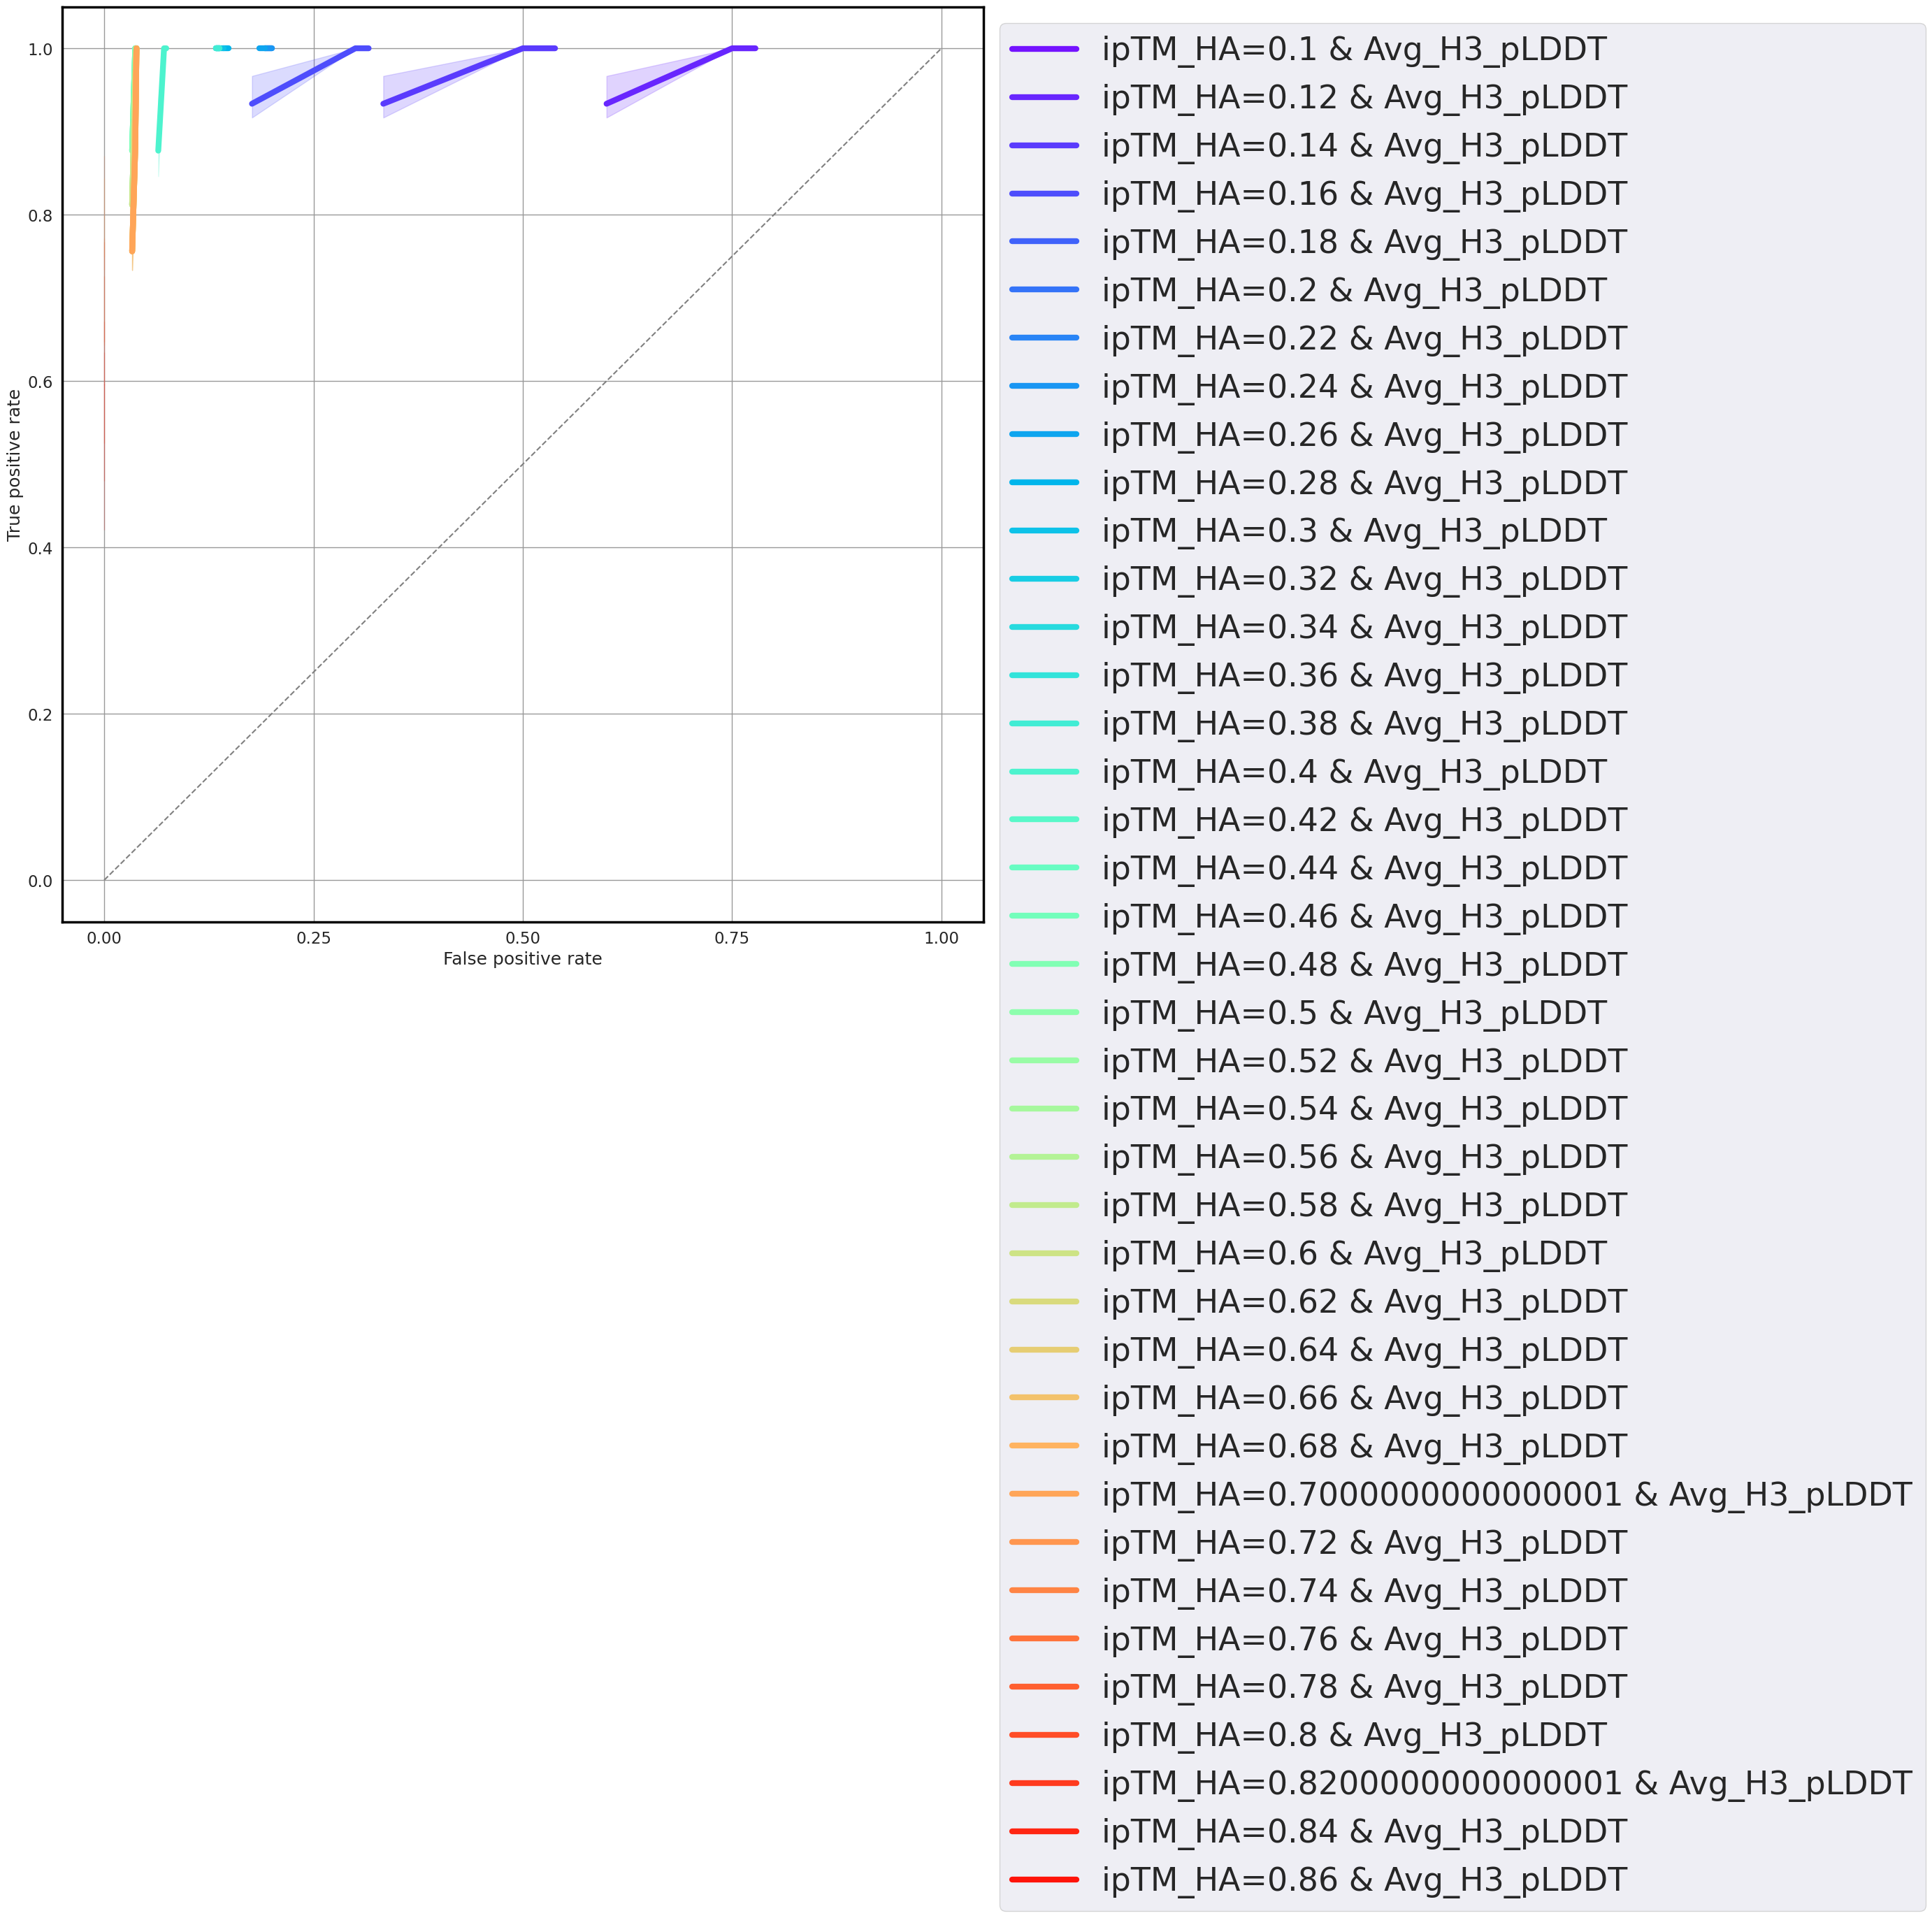

In [31]:
sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(17,17))
df = ab_iptm_h3plddt_df
df['Metric'] = [df.iloc[x]['Metric 1']+'='+str(df.iloc[x]['Metric 1 Values']) +' & '+ df.iloc[x]['Metric 2'] for x in range(df.shape[0])] 
ax = sns.lineplot(data=df,x='False positive rate',y='True positive rate',hue='Metric',linewidth=6,palette='rainbow')
sns.lineplot(x=np.array(list(range(0,11,1)))/10,y=np.array(list(range(0,11,1)))/10,ls='--',color='gray')
for spine in ax.spines.values():
    spine.set_linewidth(2.5)
    spine.set_color('black')
sns.set(font_scale=3)
ax.set(xticks=[0,0.25,0.50,0.75,1.0]) 
sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))
plt.savefig(f'results/round_9/plots/Ab_AUROC_iptm_h3plddt_joint_culled.svg',format='svg',dpi=700,transparent=True,bbox_inches='tight')

In [39]:
ab_jointopt_df['Metric'] = [ab_jointopt_df.iloc[x]['Metric 1']+'='+str(ab_jointopt_df.iloc[x]['Metric 1 Values']) +' & '+ ab_jointopt_df.iloc[x]['Metric 2'] for x in range(ab_jointopt_df.shape[0])] 

In [ ]:
ab_jointopt_df.to_csv("results/round_7/datafiles/culled_ab_roc_jointopt.csv") #,index_col='Unnamed: 0')

In [48]:
metric1_list = ['ipTM_HA','I_pLDDT']
metric2_list = ['del_G_B','Avg_H3_pLDDT']
iptm_range_nbs = (0.01)*np.array(range(int(100*float(be_withothermetrics[be_withothermetrics['Protein_type']=='nanobody'].ipTM_HA.min())),int(100*float(be_withothermetrics[be_withothermetrics['Protein_type']=='nanobody'].ipTM_HA.max())),5))
iptm_range_abs_old = np.array(list(range(1,90,3)))/100
iplddt_range_abs_old = np.array(list(range(48,96,2)))
iplddt_range_nbs = np.array(range(int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='nanobody'].I_pLDDT.min())),int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='nanobody'].I_pLDDT.max())),5))
delgb_range_nbs = np.array(list(range(int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='nanobody'].del_G_B.min())),int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='nanobody'].del_G_B.max())),25)))
h3_range_nbs = np.array(range(int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='nanobody'].Avg_H3_pLDDT.min())),int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='nanobody'].Avg_H3_pLDDT.max()))))
metric1_to_range_ab_dict = {'ipTM_HA':iptm_range_abs,'I_pLDDT':iplddt_range_abs}
# metric1_to_range_nb_dict = {'ipTM_HA':iptm_range_nbs,'I_pLDDT':iplddt_range_nbs}
# for i in metric1_list:
#     metric1_range = metric1_to_range_ab_dict[i]
#     for j in metric1_range:
#         ab_delgb = be_withothermetrics[be_withothermetrics[i]<=]
h3_range_nbs

array([50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66,
       67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83,
       84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97])

In [46]:
nb_iptm_delgb_df = r_runner(be_withothermetrics,'nanobody','ipTM_HA',list(iptm_range_nbs),'del_G_B',list(delgb_range_nbs))
nb_iplddt_delgb_df = r_runner(be_withothermetrics,'nanobody','I_pLDDT',list(iplddt_range_nbs),'del_G_B',list(delgb_range_nbs))
nb_iptm_h3plddt_df = r_runner(be_withothermetrics,'nanobody','ipTM_HA',list(iptm_range_nbs),'Avg_H3_pLDDT',list(h3_range_nbs))
nb_iplddt_h3plddt_df = r_runner(be_withothermetrics,'nanobody','I_pLDDT',np.array(range(int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='nanobody'].I_pLDDT.min())),int(float(be_withothermetrics[be_withothermetrics['Protein_type']=='nanobody'].I_pLDDT.max())))),'Avg_H3_pLDDT',list(h3_range_nbs))
nb_jointopt_df = pd.concat([nb_iptm_delgb_df,nb_iptm_h3plddt_df,nb_iplddt_delgb_df,nb_iplddt_h3plddt_df],ignore_index=True)
nb_jointopt_df

[-46, -45, -44, -43, -42, -41, -40, -39, -38, -37, -36, -35, -34, -33, -32, -31, -30, -29, -28, -27, -26, -25, -24, -23, -22, -21, -20, -19, -18, -17, -16, -15, -14, -13, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
[-46, -45, -44, -43, -42, -41, -40, -39, -38, -37, -36, -35, -34, -33, -32, -31, -30, -29, -28, -27, -26, -25, -24, -23, -22, -21, -20, -19, -18, -17, -16, -15, -14, -13, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
[50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97]
[66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65]


,Metric 1,Metric 2,Metric 1 Values,Metric 2 Values,True positive rate,False positive rate
0,ipTM_HA,del_G_B,0.2,-9,0.944444,0.138889
1,ipTM_HA,del_G_B,0.2,-8,0.944444,0.138889
2,ipTM_HA,del_G_B,0.2,-7,0.944444,0.138889
3,ipTM_HA,del_G_B,0.2,-6,0.944444,0.138889
4,ipTM_HA,del_G_B,0.2,-5,0.944444,0.138889
...,...,...,...,...,...,...
1214,I_pLDDT,del_G_B,92.0,17,0.888889,0.000000
1215,I_pLDDT,del_G_B,92.0,18,0.888889,0.000000
1216,I_pLDDT,del_G_B,92.0,19,0.888889,0.000000
1217,I_pLDDT,del_G_B,92.0,20,0.888889,0.000000


In [50]:
nb_jointopt_df['Metric'] = [nb_jointopt_df.iloc[x]['Metric 1']+'='+str(nb_jointopt_df.iloc[x]['Metric 1 Values']) +' & '+ nb_jointopt_df.iloc[x]['Metric 2'] for x in range(nb_jointopt_df.shape[0])] 
nb_jointopt_df.to_csv("results/round_7/datafiles/culled_nb_roc_jointopt.csv") #,index_col='Unnamed: 0')

In [53]:
sns.set_style("whitegrid",{"grid.color":"0.6"})
plt.figure(figsize=(17,17))
df = nb_iplddt_delgb_df
df['Metric'] = [df.iloc[x]['Metric 1']+'='+str(df.iloc[x]['Metric 1 Values']) +' & '+ df.iloc[x]['Metric 2'] for x in range(df.shape[0])] 
ax = sns.lineplot(data=df,x='False positive rate',y='True positive rate',hue='Metric',linewidth=6)
sns.lineplot(x=np.array(list(range(0,11,1)))/10,y=np.array(list(range(0,11,1)))/10,ls='--',color='gray')
for spine in ax.spines.values():
    spine.set_linewidth(2.5)
    spine.set_color('black')
sns.set(font_scale=3)
ax.set(xticks=[0,0.25,0.50,0.75,1.0]) 
sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))
plt.savefig(f'results/round_7/plots/Nb_AUROC_iplddt_delgb_joint_culled.svg',format='svg',dpi=700,transparent=True,bbox_inches='tight')

: 

# iptm-dockq correlation

In [19]:
top_df['DockQ']=top_df['DockQ'].astype(float)
top_df['ipTM_HA']=top_df['ipTM_HA'].astype(float)

/tmp/ipykernel_2293373/4110920467.py:6: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax = sns.scatterplot(ax=axes[0],data=datadf,x='ipTM_HA',y='DockQ',hue='DockQ_Classification',hue_order=['Incorrect','Acceptable','Medium','High'],edgecolor='black',alpha=0.5,s=150,palette=pastel_palette,legend=False)


ab stats: PearsonRResult(statistic=0.838502137870719, pvalue=5.536492122938406e-14)
nb stats: PearsonRResult(statistic=0.7143562230244468, pvalue=1.46417112294171e-10)


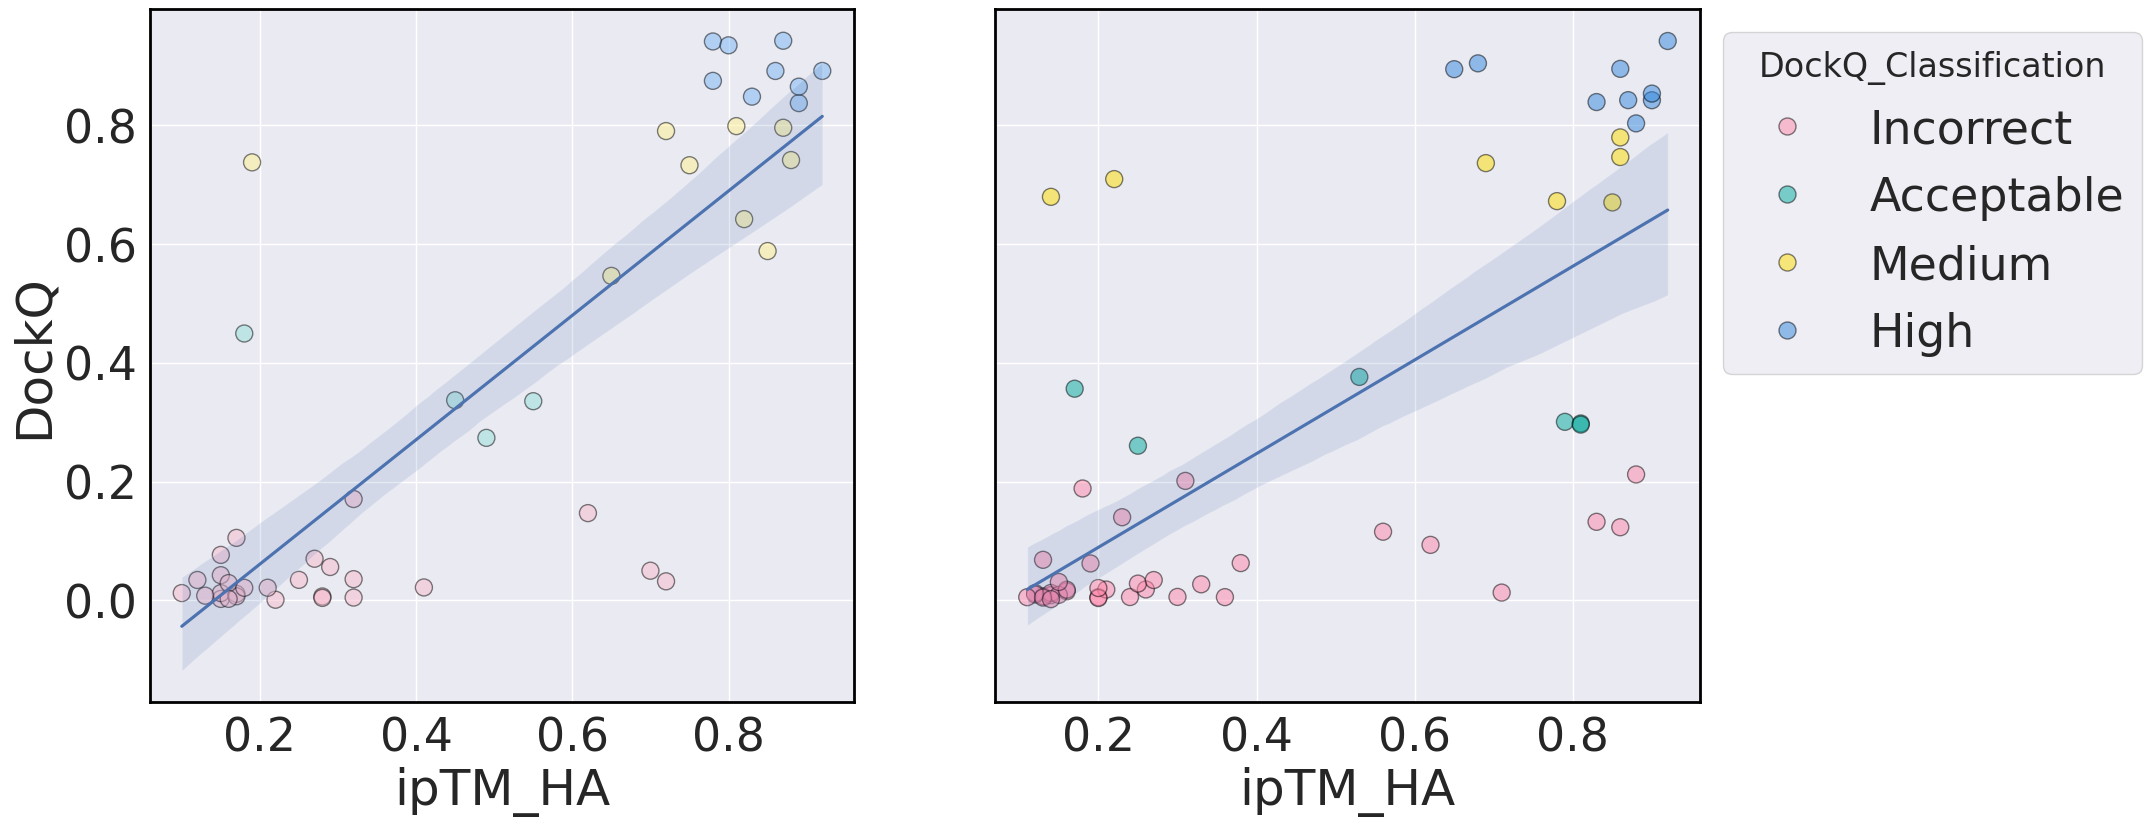

In [25]:
# plt.figure(figsize=(10,10))
fig, axes = plt.subplots(1,2, figsize=(20, 9), sharey=True)
custom_params = {"axes.spines.right": True, "axes.spines.top": True,"grid.color":"0.6"}
sns.set_theme(style='whitegrid', rc=custom_params,font_scale=3)
datadf = top_df[(top_df['Protein_type']=='antibody')] #[(top_df['Protein_type']=='antibody')]
ax = sns.scatterplot(ax=axes[0],data=datadf,x='ipTM_HA',y='DockQ',hue='DockQ_Classification',hue_order=['Incorrect','Acceptable','Medium','High'],edgecolor='black',alpha=0.5,s=150,palette=pastel_palette,legend=False)
sns.set(font_scale=3)
# sns.set_style("whitegrid",{"grid.color":"0.6"})
sns.regplot(ax=axes[0],data=datadf,x='ipTM_HA',y='DockQ',scatter=False,order=1)
# sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
for spine in ax.spines.values():
    spine.set_linewidth(2)
    spine.set_color('black')
# plt.figure(figsize=(10,10))
x = datadf.ipTM_HA.dropna().astype(float).tolist()
y = datadf.DockQ.dropna().astype(float).tolist()
res = stats.pearsonr(x, y)
print(f"ab stats: {res}")
custom_params = {"axes.spines.right": True, "axes.spines.top": True,"grid.color":"0.6"}
sns.set_theme(style='whitegrid', rc=custom_params,font_scale=2)
datadf = top_df[(top_df['Protein_type']=='nanobody')]
ax = sns.scatterplot(ax=axes[1],data=datadf,x='ipTM_HA',y='DockQ',hue='DockQ_Classification',hue_order=['Incorrect','Acceptable','Medium','High'],edgecolor='black',alpha=0.5,s=150,palette=palette)
# sns.set_style("whitegrid",{"grid.color":"0.6"})
sns.set(font_scale=3)
sns.regplot(ax=axes[1],data=datadf,x='ipTM_HA',y='DockQ',scatter=False,order=1)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
for spine in ax.spines.values():
    spine.set_linewidth(2)
    spine.set_color('black')
x = datadf.ipTM_HA.dropna().astype(float).tolist()[:60]
y = datadf.DockQ.dropna().astype(float).tolist()
res = stats.pearsonr(x, y)
print(f"nb stats: {res}")
plt.savefig('results/round_9/plots/Top_ranked_ab_v_nb_dockqviptm.svg',format='svg',dpi=700,transparent=True,bbox_inches='tight')